# DATA 37000 Final Project: When does fine-tuning help, and what is color worth?
Duorui Xu · Autumn 2026

This notebook is the complete record of my final project, executed from top to bottom in one go (Kernel → Restart & Run All, code cells 1 to 41 in order) on my own laptop GPU. Part 1 is retrained in this execution and reproduces its locked checkpoints bit for bit. The 78 models of Part 2 and their test scores were produced in earlier sessions, each part right after its lock, and are reloaded here once every checkpoint has been checked against its saved hash. The project has two parts.

**Part 1, the required comparison.** I adapt an ImageNet-pretrained ResNet18 to six breeds from Oxford-IIIT Pet in two ways: training only a new classification head on the frozen network, or also fine-tuning its last residual stage, `layer4`. Fine-tuning got 587 of the 598 test photos right and the frozen baseline 584 (98.16% vs. 97.66%). That difference is inside the noise (exact McNemar p = 0.61, 95% interval for the difference −0.67 to +1.67 percentage points), so on this task I can't show that fine-tuning helps. Its selected checkpoint came after a single epoch, and it overfit after that. A sensitivity check with the assignment's literal stopping rule ends Part 1.

**Part 2, the extension: what is color worth?** The idea came from Prof. Lo in his office hours: let the same two models learn from black-and-white photos instead of color ones. In Part 2a, with the full training split, taking color away costs almost nothing. Over five seeds, a model trained and tested in black and white is as accurate as one trained and tested in color: the frozen model gains 0.77 points on average (interval −0.37 to +1.97) and the fine-tuned model loses 0.13 (interval −1.47 to +1.14). Part 2b asks what that leaves open. Does the answer change when the models learn from 1, 5 or 20 photos per breed instead of 80? And do the color models use color even where they don't need it? To answer the second question, I change only the colors of the test photos and keep their brightness, and with it their black-and-white versions, exactly as it was. The answer is that the models do not need color but do use it: learning without color costs at most a few points even with one photo per breed, while rotating only the pet's colors costs the fine-tuned models 14.78 points with one photo per breed and 2.07 with 80, and the background's colors play no measurable part.

Every choice was made on the validation set and written to a lock file, together with the analysis plan, before the test set was used: once for Part 1, once for Part 2a and once for Part 2b (the Part 1 lock file has a history, explained where it is written). Results are in `results/`, figures in `figures/`, and the model weights in `checkpoints/`, which is not submitted. The project, with this notebook, is on GitHub at <https://github.com/AlastorrrXu/d370-final-xu-duorui>. The next two sections list where each part of the assignment is and where every file lives.

### Where each part of the assignment is
| Assignment | Where in this notebook |
|---|---|
| Six breeds, 80/20 split per breed with a fixed seed, actual counts, saved indices and class mapping | Part 1 · Data and split |
| 1. Six-class ResNet18 from Lab 7a; one-epoch head-only warm-up; saved checkpoint | Model; Shared warm-up |
| 2. Frozen baseline and fine-tuned `layer4` from that checkpoint (1e-4 for `layer4`, 1e-3 for the head); frozen BatchNorm statistics fixed | Model; Training both models; the checks after the cost table |
| 3. Same images, preprocessing, head learning rate and epochs; plateau rule with at least 5 epochs; device, seed, settings and time; validation-based selection; lock before the test | Setup; Training both models; Lock the choices; Sensitivity check |
| 4. Learning curves; test accuracy and macro-F1; training time and trainable parameters; confusion matrix; three errors; both models on the same test photos; one source of uncertainty; one next experiment | fig1; the test cells; the cost table; fig2; Error analysis (fig3); McNemar test and paired bootstrap; the last section |
| 5. Paired Grad-CAM on two photos with the same target class, layer and display settings | Paired Grad-CAM (fig4, figS1; supplement figS2) |
| 6. One extension | Part 2a (the full split, five seeds) and Part 2b (fewer photos; changing only the color) |

### Where everything is
| | Address |
|---|---|
| This project on GitHub | <https://github.com/AlastorrrXu/d370-final-xu-duorui> |
| Dataset, official page | <https://www.robots.ox.ac.uk/~vgg/data/pets/>. The data cell downloads it with torchvision if it is not there yet. |
| ImageNet weights | torchvision's `IMAGENET1K_V1`, downloaded automatically into the PyTorch cache on first use |
| Project folder (`OUT`) | the folder this notebook is started from; the first code cell stops if the notebook is not in it |
| Dataset folder (`DATA_ROOT`) | `../data/bigdata` next to the project folder (in this run `C:\Users\LENOVO\d370-26a\data\bigdata`), or the folder named by the environment variable `D370_DATA`; the images and annotations land in its `oxford-iiit-pet` subfolder |
| Results, figures, model weights | `results/`, `figures/` and `checkpoints/` inside the project folder; the weights are not submitted |

To run the notebook on another machine, open it from its own folder; nothing has to be edited. The `results/` folder that comes with it is the record of the reported run and holds its three lock files. A rerun on other hardware will not reproduce the checkpoints bit for bit, so the lock check in Part 1 stops it. To rerun everything from scratch without touching that record, set the environment variable `D370_TAG`, for example to `rerun`: every result, figure and checkpoint then goes to `results_rerun/`, `figures_rerun/` and `checkpoints_rerun/` instead (about 1.5 hours on the GPU below).

## Part 1. Frozen features vs. fine-tuning `layer4`

### Setup
Everything that defines the experiment is in this cell and was fixed before the first run: the six breeds, the validation fraction, the batch size, the learning rates and the epoch rule. I seed everything with 42, turn off cuDNN autotuning and TF32, and ask PyTorch for deterministic algorithms. The cell also records the hardware and software versions in `results/run_config.json`, and it takes the folder it is started from as the project folder.

In [1]:
import os, json, time, hashlib, random, platform, sys, zipfile, warnings
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
from pathlib import Path
from datetime import datetime, timezone
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torchvision, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import models, transforms
from torchvision.datasets import OxfordIIITPet
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix, precision_recall_fscore_support
from scipy.stats import binomtest

SEED = 42
BREEDS = ["Abyssinian", "Bengal", "Persian", "Beagle", "Pug", "Samoyed"]
VAL_FRAC = 0.2
WARMUP_EPOCHS = 1
MIN_EPOCHS, PATIENCE, MAX_EPOCHS = 100, 2, 200
BATCH, EVAL_BATCH = 16, 32
HEAD_LR, L4_LR = 1e-3, 1e-4
NUM_WORKERS = 0
DEVICE = None
OUT = Path.cwd()       # the project folder: open this notebook (or run d370_final.py) from the folder that holds it
assert (OUT / "d370_final_results.ipynb").exists() or (OUT / "d370_final.py").exists(), f"start from the project folder, not {OUT}"
DATA_ROOT = os.environ.get("D370_DATA") or str(OUT.parent / "data" / "bigdata")   # Oxford-IIIT Pet is kept (or downloaded) here
TAG = os.environ.get("D370_TAG", "")   # "" = the reported run's folders; any other tag starts a fresh run in results_<tag>/ etc.
assert MIN_EPOCHS >= 5

sfx = f"_{TAG}" if TAG else ""
RES, FIG, CKPT = OUT / f"results{sfx}", OUT / f"figures{sfx}", OUT / f"checkpoints{sfx}"
for d in (RES, FIG, CKPT):
    d.mkdir(parents=True, exist_ok=True)
os.makedirs(DATA_ROOT, exist_ok=True)
dump = lambda obj, p: Path(p).write_text(json.dumps(obj, indent=2, default=str), encoding="utf-8")

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.use_deterministic_algorithms(True, warn_only=True)
torch.backends.cudnn.benchmark, torch.backends.cudnn.deterministic = False, True
torch.backends.cudnn.allow_tf32 = torch.backends.cuda.matmul.allow_tf32 = False

if DEVICE: device = torch.device(DEVICE)
elif torch.cuda.is_available(): device = torch.device("cuda")
elif torch.backends.mps.is_available(): device = torch.device("mps")
else: device = torch.device("cpu")

env = dict(python=sys.version.split()[0], platform=platform.platform(), torch=torch.__version__,
           torchvision=torchvision.__version__, device=str(device))
if device.type == "cuda":
    p = torch.cuda.get_device_properties(device)
    env.update(gpu=torch.cuda.get_device_name(device), gpu_mem_gb=round(p.total_memory / 2**30, 1),
               cuda=torch.version.cuda, cudnn=torch.backends.cudnn.version())
else:
    env.update(cpu=platform.processor() or platform.machine(), torch_threads=torch.get_num_threads())
settings = dict(seed=SEED, breeds=BREEDS, val_frac=VAL_FRAC, warmup_epochs=WARMUP_EPOCHS, min_epochs=MIN_EPOCHS,
                patience=PATIENCE, max_epochs=MAX_EPOCHS, batch=BATCH, eval_batch=EVAL_BATCH, head_lr=HEAD_LR,
                layer4_lr=L4_LR, num_workers=NUM_WORKERS, data_root=str(Path(DATA_ROOT).resolve()),
                tf32=False, cudnn_deterministic=True)
dump({"env": env, "settings": settings}, RES / "run_config.json")
env

{'python': '3.12.0',
 'platform': 'Windows-11-10.0.26300-SP0',
 'torch': '2.11.0+cu128',
 'torchvision': '0.26.0+cu128',
 'device': 'cuda',
 'gpu': 'NVIDIA GeForce RTX 5060 Laptop GPU',
 'gpu_mem_gb': 8.0,
 'cuda': '12.8',
 'cudnn': 91900}

This run used an NVIDIA GeForce RTX 5060 Laptop GPU (8 GB) with CUDA 12.8, cuDNN 9.19 and PyTorch 2.11.0 on Windows 11. Re-running the notebook on this machine reproduced both selected checkpoints bit for bit, with the same SHA-256 hashes as my previous runs, so these numbers are repeatable; the lock cell below checks this every time.

### Data and split
The six breeds are the assignment's defaults. The next cell checks that they exist in the dataset's own class list, remaps them to labels 0–5, and splits each breed's development images 80/20 into training and validation with one seeded generator. The split is saved, and if a saved split already exists, the cell checks that it comes out identical. The official test split is not touched here; it is only loaded after everything is locked.

In [2]:
development = OxfordIIITPet(root=DATA_ROOT, split="trainval", target_types="category", download=True)
assert all(b in development.class_to_idx for b in BREEDS), [b for b in BREEDS if b not in development.class_to_idx]
orig = {b: development.class_to_idx[b] for b in BREEDS}
o2n = {orig[b]: i for i, b in enumerate(BREEDS)}
labels = np.array(development._labels)
ids = [Path(p).stem for p in development._images]

rng = np.random.default_rng(SEED)
tr_idx, va_idx = [], []
for b in BREEDS:
    perm = rng.permutation(np.flatnonzero(labels == orig[b]))
    nv = int(round(VAL_FRAC * len(perm)))
    va_idx += perm[:nv].tolist()
    tr_idx += perm[nv:].tolist()
tr_idx, va_idx = sorted(tr_idx), sorted(va_idx)
assert not set(tr_idx) & set(va_idx)

split = dict(seed=SEED, val_frac=VAL_FRAC, original_label=orig, new_label={b: i for i, b in enumerate(BREEDS)},
             train_idx=tr_idx, val_idx=va_idx, train_ids=[ids[j] for j in tr_idx], val_ids=[ids[j] for j in va_idx])
if (RES / "split.json").exists():
    old = json.loads((RES / "split.json").read_text(encoding="utf-8"))
    assert old["train_idx"] == tr_idx and old["val_idx"] == va_idx, "split changed?"
dump(split, RES / "split.json")
dump({"breeds": BREEDS, "original_index": orig, "new_index": split["new_label"]}, RES / "class_mapping.json")
pd.DataFrame([dict(split=s, dataset_index=j, image_id=ids[j], original_label=int(labels[j]),
                   breed=BREEDS[o2n[int(labels[j])]]) for s, idx in [("train", tr_idx), ("val", va_idx)] for j in idx]
             ).to_csv(RES / "split_manifest.csv", index=False)
counts = pd.DataFrame([dict(breed=b, original_label=orig[b], new_label=i, trainval=int((labels == orig[b]).sum()),
                            train=int(sum(labels[j] == orig[b] for j in tr_idx)),
                            val=int(sum(labels[j] == orig[b] for j in va_idx))) for i, b in enumerate(BREEDS)])
counts.to_csv(RES / "split_counts.csv", index=False)
print(len(development), "trainval images over all 37 breeds |", len(tr_idx), "train,", len(va_idx), "val")
counts

3680 trainval images over all 37 breeds | 480 train, 120 val


,breed,original_label,new_label,trainval,train,val
0,Abyssinian,0,0,100,80,20
1,Bengal,5,1,100,80,20
2,Persian,23,2,100,80,20
3,Beagle,4,3,100,80,20
4,Pug,25,4,100,80,20
5,Samoyed,29,5,100,80,20


Every breed has exactly 100 development images, so the split is a clean 80/20: 480 training and 120 validation photos.

The next cell sets the preprocessing. Training photos are resized, randomly cropped to 224×224 and randomly flipped; validation and test photos get a fixed center crop instead. Both are normalized with ImageNet's channel statistics, which is what these pretrained weights expect. Lab 7a's padding-and-crop trick assumes small square CIFAR images, so I adapted it to rectangular photos.

In [3]:
mean, std = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
tf_train = transforms.Compose([transforms.Resize(256), transforms.RandomCrop(224), transforms.RandomHorizontalFlip(),
                               transforms.ToTensor(), transforms.Normalize(mean, std)])
tf_eval = transforms.Compose([transforms.Resize(256), transforms.CenterCrop(224), transforms.ToTensor(),
                              transforms.Normalize(mean, std)])
remap = o2n.__getitem__
dev_train = OxfordIIITPet(DATA_ROOT, split="trainval", target_types="category", transform=tf_train, target_transform=remap)
dev_eval = OxfordIIITPet(DATA_ROOT, split="trainval", target_types="category", transform=tf_eval, target_transform=remap)
train_ds, val_ds = Subset(dev_train, tr_idx), Subset(dev_eval, va_idx)
print(len(train_ds), "train /", len(val_ds), "val")

480 train / 120 val


### Model
Both models are the same ResNet18 with ImageNet weights, with the 1000-class output layer replaced by a new `Linear(512, 6)`. They differ only in what is allowed to change. In the frozen model only the head trains. The fine-tuned model also trains `layer4`, which holds about three quarters of all parameters.

One detail matters here. Setting `requires_grad=False` does not stop a BatchNorm layer from updating its running statistics, so every BatchNorm layer without trainable parameters stays in eval mode, as in Lab 7a.

In [4]:
CONDS = ["frozen", "finetune"]

def build():
    m = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    m.requires_grad_(False)
    torch.manual_seed(SEED)
    m.fc = nn.Linear(512, len(BREEDS))
    return m

def setup(m, cond):
    m.requires_grad_(False)
    m.fc.requires_grad_(True)
    if cond == "finetune":
        m.layer4.requires_grad_(True)
    return m

def make_opt(m, cond):
    groups = [{"params": list(m.fc.parameters()), "lr": HEAD_LR}]
    if cond == "finetune":
        groups.insert(0, {"params": list(m.layer4.parameters()), "lr": L4_LR})
    opt = torch.optim.Adam(groups)
    assert {id(p) for g in opt.param_groups for p in g["params"]} == {id(p) for p in m.parameters() if p.requires_grad}
    return opt

def train_mode(m):
    m.train()
    for mod in m.modules():
        if isinstance(mod, nn.BatchNorm2d) and not any(p.requires_grad for p in mod.parameters()):
            mod.eval()

rows = []
for c in CONDS:
    m = setup(build(), c)
    train_mode(m)
    rows.append(dict(condition=c, total=sum(p.numel() for p in m.parameters()),
                     trainable=sum(p.numel() for p in m.parameters() if p.requires_grad),
                     bn_layers=sum(isinstance(x, nn.BatchNorm2d) for x in m.modules()),
                     bn_using_batch_stats=sum(isinstance(x, nn.BatchNorm2d) and x.training for x in m.modules())))
del m
pd.DataFrame(rows)

,condition,total,trainable,bn_layers,bn_using_batch_stats
0,frozen,11179590,3078,20,0
1,finetune,11179590,8396806,20,5


In the frozen model only 3,078 parameters train, 0.03% of the network. Fine-tuning brings that to 8,396,806, about 75%. Only the five BatchNorm layers inside `layer4` use batch statistics, and only in the fine-tuned model (last column).

The helpers in the next cell do the training and evaluation. Two of them matter for a fair comparison. `run_epoch` reseeds the shuffling and the augmentation from the epoch number, so both models see exactly the same mini-batches, and it hashes each epoch's batches so I can check that afterwards. It also records how long each epoch waits for the data loader and how long the GPU computes, which matters for the cost question.

In [5]:
def sync():
    if device.type == "cuda": torch.cuda.synchronize()
    elif device.type == "mps": torch.mps.synchronize()

def run_epoch(m, opt, epoch):
    train_mode(m)
    g = torch.Generator()
    g.manual_seed(SEED * 1000 + epoch)
    loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True, num_workers=NUM_WORKERS, generator=g)
    torch.manual_seed(SEED * 1000 + epoch)
    h = hashlib.sha256()
    tot, correct, n, t_data, t_comp = 0.0, 0, 0, 0.0, 0.0
    sync()
    if device.type == "cuda":
        mem0 = torch.cuda.memory_allocated(device)
        torch.cuda.reset_peak_memory_stats(device)
    t0 = t_last = time.perf_counter()
    for x, y in loader:
        h.update(y.numpy().astype(np.int64).tobytes())
        h.update(np.float64(x.double().sum().item()).tobytes())
        t1 = time.perf_counter()
        t_data += t1 - t_last
        x, y = x.to(device), y.to(device)
        opt.zero_grad(set_to_none=True)
        out = m(x)
        loss = F.cross_entropy(out, y)
        loss.backward()
        opt.step()
        tot += loss.item() * len(y)
        correct += (out.argmax(1) == y).sum().item()
        n += len(y)
        t_last = time.perf_counter()
        t_comp += t_last - t1
    sync()
    r = dict(train_loss=tot / n, train_acc=correct / n, train_time=time.perf_counter() - t0, data_time=t_data,
             compute_time=t_comp, batches_hash=h.hexdigest()[:16], gpu_peak_inc_mb=None)
    if device.type == "cuda":
        r["gpu_peak_inc_mb"] = round((torch.cuda.max_memory_allocated(device) - mem0) / 2**20, 1)
    return r

@torch.no_grad()
def predict(m, ds):
    m.eval()
    outs, ys = [], []
    for x, y in DataLoader(ds, batch_size=EVAL_BATCH, shuffle=False, num_workers=NUM_WORKERS):
        outs.append(m(x.to(device)).float().cpu())
        ys.append(y)
    return torch.cat(outs), torch.cat(ys)

def macro_f1(y, p):
    k = len(BREEDS)
    cm = np.bincount(k * np.asarray(y) + np.asarray(p), minlength=k * k).reshape(k, k)
    tp = np.diag(cm); fp = cm.sum(0) - tp; fn = cm.sum(1) - tp
    d = 2 * tp + fp + fn
    return float(np.mean(np.where(d > 0, 2 * tp / np.maximum(d, 1), 0.0)))

def evaluate(m, ds):
    sync(); t0 = time.perf_counter()
    logits, y = predict(m, ds)
    sync()
    pred = logits.argmax(1)
    nc = int((pred == y).sum())
    return dict(loss=F.cross_entropy(logits, y).item(), correct=nc, n=len(y), acc=nc / len(y),
                macro_f1=macro_f1(y.numpy(), pred.numpy()), time=time.perf_counter() - t0)

def better(r, b):
    return b is None or r["val_correct"] > b["val_correct"] or (r["val_correct"] == b["val_correct"] and r["val_loss"] < b["val_loss"])

def since_best(hist):
    best, be = -1, 0
    for r in hist:
        if r["val_correct"] > best:
            best, be = r["val_correct"], r["epoch"]
    return hist[-1]["epoch"] - be

def warm_device():
    w = models.resnet18(weights=None)
    w.fc = nn.Linear(512, len(BREEDS))
    w = setup(w, "finetune").to(device)
    o = torch.optim.Adam([p for p in w.parameters() if p.requires_grad], lr=1e-4)
    x = torch.randn(BATCH, 3, 224, 224, device=device)
    y = torch.randint(0, len(BREEDS), (BATCH,), device=device)
    for _ in range(2):
        train_mode(w); o.zero_grad(set_to_none=True); F.cross_entropy(w(x), y).backward(); o.step()
    setup(w, "frozen"); train_mode(w); F.cross_entropy(w(x), y).backward()
    with torch.no_grad():
        w.eval(); w(torch.randn(EVAL_BATCH, 3, 224, 224, device=device))
    sync()
    if device.type == "cuda": torch.cuda.empty_cache()

### Shared warm-up
A brand-new head is random, so the first gradients that reach `layer4` would be noise. To keep that from hurting the fine-tuned model, I first train only the head for one epoch and save it. Both models start from this same checkpoint.

In [6]:
warm_device()
m = setup(build(), "warmup").to(device)
opt = make_opt(m, "warmup")
before = evaluate(m, val_ds)
w_tr = [run_epoch(m, opt, -e) for e in range(WARMUP_EPOCHS)]
w_val = evaluate(m, val_ds)
torch.save({k: v.detach().cpu().clone() for k, v in m.state_dict().items()}, CKPT / "warmup_head.pt")
dump(dict(train=w_tr, val_before=before, val_after=w_val, train_time=sum(r["train_time"] for r in w_tr)), RES / "warmup.json")
print(f"warm-up: train loss {w_tr[-1]['train_loss']:.4f} ({sum(r['train_time'] for r in w_tr):.1f}s) | "
      f"val acc {before['acc']:.3f} with the random head -> {w_val['acc']:.4f} ({w_val['correct']}/{w_val['n']}), "
      f"val loss {w_val['loss']:.4f}")

warm-up: train loss 0.9336 (1.9s) | val acc 0.275 with the random head -> 0.9500 (114/120), val loss 0.4018


One epoch takes the head from 27.5% (random) to 95.0% validation accuracy (114/120) in under two seconds. The ImageNet features are already doing most of the work.

### Training both models
Both models reload the warm-up checkpoint and get fresh Adam optimizers: learning rate 1e-3 for the head and, in the fine-tuned model only, 1e-4 for `layer4`. They train side by side, epoch by epoch, on the same batches.

**Epoch budget, a deliberate deviation.** The assignment says to train until validation accuracy plateaus for 2 consecutive epochs, with at least 5 epochs. I keep the plateau rule exactly as written but only start checking it at epoch 100, with a cap of 200, for two reasons. First, one epoch here is only 30 optimizer steps, far below usual fine-tuning budgets: Kornblith et al. (2019) fine-tuned for 20,000 steps on full datasets and, in their experiments on small subsets, for at least 1,000 steps or 100 epochs. Second, with 120 validation photos, accuracy moves in steps of 0.83 points, so two epochs without a new best happen by chance early on. Each model gets its own plateau epoch, and both are then trained to the later of the two, so they always get the same number of epochs. The sensitivity check at the end of Part 1 applies the literal rule instead and shows that the conclusion does not depend on this choice.

**Selection.** For each model I keep the checkpoint with the best validation accuracy. Ties go to the lower validation loss, then to the earlier epoch. In the log, `*` marks a new best.

In [7]:
warm_device()
(RES / "train_log.txt").write_text("")
w_state = torch.load(CKPT / "warmup_head.pt", map_location="cpu")
runs = {}
for c in CONDS:
    m = build()
    m.load_state_dict(w_state)
    m = setup(m, c).to(device)
    s = evaluate(m, val_ds)
    if s["correct"] != w_val["correct"] or abs(s["loss"] - w_val["loss"]) > 1e-4:
        if abs(s["loss"] - w_val["loss"]) > 1e-2:
            raise RuntimeError(f"{c}: reloaded warm-up gives {s['correct']} / {s['loss']:.5f}")
        warnings.warn(f"{c}: reloaded warm-up {s['correct']} / {s['loss']:.6f} vs {w_val['correct']} / {w_val['loss']:.6f}")
    runs[c] = dict(m=m, opt=make_opt(m, c), hist=[], best=None, best_state=None, plateau=None)

t_start = time.perf_counter()
stop = None
for ep in range(1, MAX_EPOCHS + 1):
    msg = []
    for c, R in runs.items():
        tr = run_epoch(R["m"], R["opt"], ep)
        va = evaluate(R["m"], val_ds)
        rec = dict(condition=c, epoch=ep, **tr, val_loss=va["loss"], val_acc=va["acc"], val_correct=va["correct"],
                   val_n=va["n"], val_macro_f1=va["macro_f1"], val_time=va["time"])
        R["hist"].append(rec)
        if better(rec, R["best"]):
            R["best"] = rec
            R["best_state"] = {k: v.detach().cpu().clone() for k, v in R["m"].state_dict().items()}
        if R["plateau"] is None and ep >= MIN_EPOCHS and since_best(R["hist"]) >= PATIENCE:
            R["plateau"] = ep
        line = (f"{c:8s} ep {ep:3d} | train loss {tr['train_loss']:.4f} acc {tr['train_acc']:.3f} | val acc {va['acc']:.4f} "
                f"({va['correct']}/{va['n']}) loss {va['loss']:.4f} F1 {va['macro_f1']:.4f} | {tr['train_time']:.1f}s "
                f"(compute {tr['compute_time']:.1f}s) | {tr['batches_hash']}")
        with open(RES / "train_log.txt", "a") as f:
            f.write(line + "\n")
        msg.append(f"{c} tr {tr['train_loss']:.3f} val {va['correct']}/{va['n']}{'*' if R['best']['epoch'] == ep else ' '} "
                   f"{va['loss']:.3f} {tr['train_time']:.1f}s")
    print(f"ep {ep:3d} | " + " | ".join(msg))
    if all(R["plateau"] for R in runs.values()):
        stop = ep
        break
if stop is None:
    stop = MAX_EPOCHS
    print("hit MAX_EPOCHS before both runs plateaued")
print(f"\n{time.perf_counter() - t_start:.1f}s for both runs incl. validation")

assert [r["batches_hash"] for r in runs["frozen"]["hist"]] == [r["batches_hash"] for r in runs["finetune"]["hist"]]

lit = {c: next((e for e in range(5, len(R["hist"]) + 1) if since_best(R["hist"][:e]) >= PATIENCE), None) for c, R in runs.items()}
under5 = None
if all(lit.values()):
    e5 = max(lit.values())
    sel5 = {}
    for c, R in runs.items():
        bb = None
        for r in R["hist"][:e5]:
            if better(r, bb):
                bb = r
        sel5[c] = bb["epoch"]
    under5 = dict(plateau=lit, E=e5, selected=sel5)

summary = dict(E=stop, plateau={c: R["plateau"] for c, R in runs.items()}, min_epochs=MIN_EPOCHS, patience=PATIENCE,
               under_floor_5=under5, device=str(device), cond={})
for c, R in runs.items():
    h, b = R["hist"], R["best"]
    torch.save(R["best_state"], CKPT / f"{c}_selected.pt")
    torch.save({k: v.detach().cpu().clone() for k, v in R["m"].state_dict().items()}, CKPT / f"{c}_last.pt")
    ntr = sum(p.numel() for p in R["m"].parameters() if p.requires_grad)
    peaks = [r["gpu_peak_inc_mb"] for r in h[1:] if r["gpu_peak_inc_mb"] is not None]
    summary["cond"][c] = dict(
        selected_epoch=b["epoch"], selected=b, trainable=ntr,
        lr={"layer4": L4_LR, "head": HEAD_LR} if c == "finetune" else {"head": HEAD_LR},
        train_time_total=sum(r["train_time"] for r in h), compute_time_total=sum(r["compute_time"] for r in h),
        data_time_total=sum(r["data_time"] for r in h), val_time_total=sum(r["val_time"] for r in h),
        train_time_to_selected=sum(r["train_time"] for r in h if r["epoch"] <= b["epoch"]),
        train_s_per_epoch=float(np.mean([r["train_time"] for r in h])),
        compute_s_per_epoch=float(np.mean([r["compute_time"] for r in h])),
        data_s_per_epoch=float(np.mean([r["data_time"] for r in h])),
        grad_adam_mib=12 * ntr / 2**20, gpu_peak_inc_mib=max(peaks) if peaks else None,
        sha256=hashlib.sha256((CKPT / f"{c}_selected.pt").read_bytes()).hexdigest())
dump(summary, RES / "training_summary.json")
hist = pd.DataFrame([r for R in runs.values() for r in R["hist"]])
hist.to_csv(RES / "history.csv", index=False)
S = summary["cond"]
for c in CONDS:
    print(f"{c:8s} selected epoch {S[c]['selected_epoch']}: val acc {S[c]['selected']['val_acc']:.4f}, "
          f"val loss {S[c]['selected']['val_loss']:.4f}, val F1 {S[c]['selected']['val_macro_f1']:.4f}")
print("first plateau:", summary["plateau"], "-> both trained E =", stop, "epochs")

ep   1 | frozen tr 0.262 val 113/120* 0.195 1.8s | finetune tr 0.270 val 118/120* 0.081 2.0s
ep   2 | frozen tr 0.144 val 117/120* 0.137 1.9s | finetune tr 0.074 val 117/120  0.073 2.2s
ep   3 | frozen tr 0.100 val 118/120* 0.120 1.8s | finetune tr 0.037 val 114/120  0.089 1.9s
ep   4 | frozen tr 0.092 val 118/120* 0.110 1.8s | finetune tr 0.038 val 116/120  0.101 2.0s
ep   5 | frozen tr 0.067 val 117/120  0.095 1.8s | finetune tr 0.027 val 117/120  0.088 2.0s
ep   6 | frozen tr 0.064 val 115/120  0.099 1.8s | finetune tr 0.020 val 117/120  0.084 2.0s
ep   7 | frozen tr 0.064 val 117/120  0.082 1.8s | finetune tr 0.015 val 117/120  0.094 2.2s
ep   8 | frozen tr 0.047 val 118/120* 0.081 1.8s | finetune tr 0.011 val 116/120  0.103 2.1s
ep   9 | frozen tr 0.048 val 118/120  0.083 2.0s | finetune tr 0.014 val 116/120  0.105 2.0s
ep  10 | frozen tr 0.039 val 117/120  0.078 1.9s | finetune tr 0.010 val 116/120  0.108 2.1s
ep  11 | frozen tr 0.035 val 118/120* 0.072 1.9s | finetune tr 0.012 v

Both models plateaued at exactly epoch 100, but they got there very differently. The frozen head reaches 118/120 by epoch 3 and stays mostly at 117–118 for the rest of the run; its one 119/120 comes at epoch 20, which is why that epoch is selected. The fine-tuned model is already at its best, 118/120, after a single epoch and never beats that. Its training loss then falls to about 0.001, while its validation loss drifts up to 0.2–0.4 and its validation accuracy down to 112–116.

**Cost.** The next table compares what each model cost: time per epoch, split into GPU compute and data loading; total training time; and the extra memory for gradients and Adam state, which is exactly 12 bytes per trainable parameter. The last printed line is a validation-only what-if: where both models would have stopped under the assignment's literal floor of 5 epochs.

In [8]:
cost = pd.DataFrame({c: {"epochs": stop, "selected epoch": S[c]["selected_epoch"],
                         "train s/epoch": round(S[c]["train_s_per_epoch"], 2),
                         "compute s/epoch": round(S[c]["compute_s_per_epoch"], 2),
                         "data loading s/epoch": round(S[c]["data_s_per_epoch"], 2),
                         "train s total": round(S[c]["train_time_total"], 1),
                         "train s to selected": round(S[c]["train_time_to_selected"], 1),
                         "grad + Adam state MiB": round(S[c]["grad_adam_mib"], 2),
                         "GPU peak increment MiB": S[c]["gpu_peak_inc_mib"]} for c in CONDS})
print("device:", env.get("gpu", env["device"]))
print(f"fine-tune / frozen per epoch: wall-clock {S['finetune']['train_s_per_epoch'] / S['frozen']['train_s_per_epoch']:.2f}x, "
      f"compute only {S['finetune']['compute_s_per_epoch'] / S['frozen']['compute_s_per_epoch']:.2f}x")
print("validation-only check with the literal floor of 5:", summary["under_floor_5"])
cost

device: NVIDIA GeForce RTX 5060 Laptop GPU
fine-tune / frozen per epoch: wall-clock 1.10x, compute only 1.56x
validation-only check with the literal floor of 5: {'plateau': {'frozen': 5, 'finetune': 5}, 'E': 5, 'selected': {'frozen': 4, 'finetune': 1}}


,frozen,finetune
epochs,100.00,100.00
selected epoch,20.00,1.00
train s/epoch,1.93,2.12
compute s/epoch,0.36,0.56
data loading s/epoch,1.58,1.57
train s total,193.20,212.40
train s to selected,37.60,2.00
grad + Adam state MiB,0.04,96.09
GPU peak increment MiB,107.20,75.20


Per epoch, fine-tuning costs only about 1.1× the wall-clock time of the frozen model (the exact numbers are in the table), because both runs spend most of each epoch, about 1.6 s, waiting for the CPU to decode and augment JPEGs; the GPU compute alone is about 1.6×. Fine-tuning also needs 96 MiB more for gradients and Adam state. I would not read the "GPU peak increment" row as a comparison: it is measured against the memory in use just before each epoch, and for the fine-tuned model that baseline still holds the previous step's `layer4` gradients, which is why fine-tuning *appears* to use less.

Counted only up to the selected checkpoints, the order reverses: the frozen head was selected after 20 epochs, under 40 s of training, and the fine-tuned model after one epoch, about 2 s.

Under the literal floor of 5 epochs, both models would have stopped at epoch 5, with selected epochs 4 (frozen) and 1 (fine-tuned). The sensitivity check at the end of Part 1 scores those two checkpoints on the test set.

**Checks.** The next cell verifies that everything that should stay frozen is bit-identical to the warm-up checkpoint, BatchNorm buffers included, that `layer4` changed only in the fine-tuned model, and that the two models saw the same mini-batches in every epoch.

In [9]:
w_state = torch.load(CKPT / "warmup_head.pt", map_location="cpu")
ver = {}
for c in CONDS:
    for which in ["selected", "last"]:
        sd = torch.load(CKPT / f"{c}_{which}.pt", map_location="cpu")
        changed = [k for k in sd if not torch.equal(sd[k], w_state[k])]
        bad = [k for k in changed if not k.startswith("fc.") and not (c == "finetune" and k.startswith("layer4."))]
        assert not bad, bad
        ver[f"{c}_{which}"] = {"fc changed": any(k.startswith("fc.") for k in changed),
                               "layer4 tensors changed": sum(k.startswith("layer4.") for k in changed),
                               "layer4 BN running stats changed": sum(k.startswith("layer4.") and "running" in k for k in changed),
                               "frozen tensors changed": len(bad)}
dump(ver, RES / "verification.json")
same = (hist[hist.condition == "frozen"].batches_hash.values == hist[hist.condition == "finetune"].batches_hash.values).all()
print("identical mini-batches in every epoch:", same)
pd.DataFrame(ver).T

identical mini-batches in every epoch: True


,fc changed,layer4 tensors changed,layer4 BN running stats changed,frozen tensors changed
frozen_selected,True,0,0,0
frozen_last,True,0,0,0
finetune_selected,True,30,10,0
finetune_last,True,30,10,0


All three hold. `layer4` changed only in the fine-tuned model (all 30 tensors, including its 10 running-statistic buffers), nothing else changed in either model, and the mini-batch hashes matched in all 100 epochs.

The learning curves start at the shared warm-up (epoch 0). Stars mark the selected checkpoints, the green line is where the plateau checks begin, and the grey line is where both runs stopped.

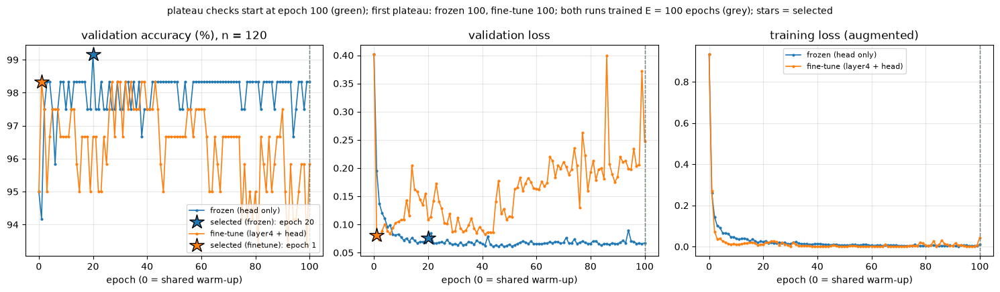

In [10]:
col = {"frozen": "tab:blue", "finetune": "tab:orange"}
lab = {"frozen": "frozen (head only)", "finetune": "fine-tune (layer4 + head)"}
fig, ax = plt.subplots(1, 3, figsize=(15, 4.4))
for c in CONDS:
    h = hist[hist.condition == c]
    ep = [0] + h.epoch.tolist()
    ax[0].plot(ep, [100 * w_val["acc"]] + (100 * h.val_acc).tolist(), "o-", ms=2, lw=1.2, color=col[c], label=lab[c])
    ax[1].plot(ep, [w_val["loss"]] + h.val_loss.tolist(), "o-", ms=2, lw=1.2, color=col[c], label=lab[c])
    ax[2].plot(ep, [w_tr[-1]["train_loss"]] + h.train_loss.tolist(), "o-", ms=2, lw=1.2, color=col[c], label=lab[c])
    se = S[c]["selected_epoch"]
    ax[0].plot(se, 100 * h.val_acc.iloc[se - 1], "*", ms=16, color=col[c], mec="k", label=f"selected ({c}): epoch {se}")
    ax[1].plot(se, h.val_loss.iloc[se - 1], "*", ms=16, color=col[c], mec="k")
for a, t in zip(ax, [f"validation accuracy (%), n = {len(va_idx)}", "validation loss", "training loss (augmented)"]):
    a.axvline(MIN_EPOCHS, color="tab:green", ls=":", lw=1)
    a.axvline(stop, color="gray", ls="--", lw=1)
    a.set_title(t); a.set_xlabel("epoch (0 = shared warm-up)"); a.grid(alpha=0.3)
ax[0].legend(fontsize=8, loc="lower right"); ax[2].legend(fontsize=8)
fig.suptitle(f"plateau checks start at epoch {MIN_EPOCHS} (green); first plateau: frozen {summary['plateau']['frozen']}, "
             f"fine-tune {summary['plateau']['finetune']}; both runs trained E = {stop} epochs (grey); stars = selected", fontsize=10)
fig.tight_layout()
fig.savefig(FIG / "fig1_learning_curves.png", dpi=150)
plt.show()

The validation-loss panel shows the difference most clearly. The frozen head is essentially a logistic regression on fixed features and keeps improving slowly for all 100 epochs. Fine-tuning `layer4` memorizes the 480 training photos within a few epochs and becomes steadily more overconfident on validation. For the fine-tuned model the stopping epoch matters a lot; for the frozen head it barely does.

### Lock the choices, then the test set
Before the test split exists, I write down everything I am going to report: the selected epoch of each model, the SHA-256 hash of each checkpoint, which model counts as the overall pick (higher validation accuracy, then lower validation loss, then the cheaper frozen model), and the whole analysis plan. All of it goes to `results/locked_choices.json`.

If that file already exists, the cell does not rewrite it. It checks instead that the retrained checkpoints have exactly the locked hashes, and stops otherwise. This guard is new: before it existed, an earlier top-to-bottom execution, at 01:46 UTC on November 18, rewrote the lock file with a new date. The selections did not change. Both checkpoints had the same SHA-256 hashes as before, and the first Part 1 lock, written before 00:04 UTC on November 17, survives as a hash inside Part 2a's lock, next to these same two checkpoint hashes; Part 2a prints both checks.

In [11]:
f_, t_ = S["frozen"]["selected"], S["finetune"]["selected"]
if t_["val_correct"] != f_["val_correct"]:
    overall = "finetune" if t_["val_correct"] > f_["val_correct"] else "frozen"
elif t_["val_loss"] != f_["val_loss"]:
    overall = "finetune" if t_["val_loss"] < f_["val_loss"] else "frozen"
else:
    overall = "frozen"
plan1 = ["test accuracy (Wilson 95% CI), macro-F1, per-class precision/recall/F1, confusion matrices",
         "same test images: 2x2 table, exact McNemar, paired bootstrap (10000, seed 42) for acc and macro-F1 differences",
         "error analysis: 3 most confident test errors of the overall model; fallback validation errors, then least confident correct",
         "Grad-CAM at layer4, target = true breed; image A = disagreement with largest change in p(true), image B = another error, prefer both wrong"]
selected1 = {c: dict(epoch=S[c]["selected_epoch"], val_correct=S[c]["selected"]["val_correct"],
                     val_loss=S[c]["selected"]["val_loss"], sha256=S[c]["sha256"]) for c in CONDS}
lock_path1 = RES / "locked_choices.json"
if lock_path1.exists():
    # an existing lock is never rewritten: the retrained checkpoints have to reproduce it bit for bit
    lock = json.loads(lock_path1.read_text(encoding="utf-8"))
    same = (all(lock["selected"][c]["epoch"] == selected1[c]["epoch"] and lock["selected"][c]["sha256"] == selected1[c]["sha256"]
                for c in CONDS) and lock["overall"] == overall and lock["E"] == stop and lock["plan"] == plan1)
    assert same, ("the retrained checkpoints or the plan differ from the locked ones; to rerun from scratch without touching "
                  "the reported run, set the environment variable D370_TAG (see the first code cell)")
    print(f"already locked at {lock['locked_at']}; both retrained checkpoints reproduce the locked SHA-256 hashes bit for bit")
else:
    lock = dict(locked_at=datetime.now(timezone.utc).isoformat(timespec="seconds"), selected=selected1, overall=overall,
                E=stop, plateau=summary["plateau"], settings=settings, plan=plan1)
    dump(lock, lock_path1)
    print("locked at", lock["locked_at"])
print(json.dumps({k: lock[k] for k in ["locked_at", "selected", "overall", "E"]}, indent=1))


already locked at 2026-11-18T01:46:30+00:00; both retrained checkpoints reproduce the locked SHA-256 hashes bit for bit
{
 "locked_at": "2026-11-18T01:46:30+00:00",
 "selected": {
  "frozen": {
   "epoch": 20,
   "val_correct": 119,
   "val_loss": 0.07667315751314163,
   "sha256": "066ac8aadd3a2766eb5618e738ae30a607c332d85c6990ba4b7115244fd4b1e4"
  },
  "finetune": {
   "epoch": 1,
   "val_correct": 118,
   "val_loss": 0.08075480163097382,
   "sha256": "bc0640a1be30498b0d27dabac876eac2b93f0c89d808858ad2a74176eb777d1e"
  }
 },
 "overall": "frozen",
 "E": 100
}


The frozen model is the overall pick, but only by one validation photo (119 vs. 118).

The test cell checks the hashes again, loads the official test split, which no earlier cell touches, confirms that none of its images is in the development set, and scores both models once. Besides accuracy with a Wilson 95% interval, it reports macro-F1, per-breed precision, recall and F1, and the confusion matrices.

In [12]:
lock = json.loads((RES / "locked_choices.json").read_text(encoding="utf-8"))
for c in CONDS:
    assert hashlib.sha256((CKPT / f"{c}_selected.pt").read_bytes()).hexdigest() == lock["selected"][c]["sha256"]
test_full = OxfordIIITPet(DATA_ROOT, split="test", target_types="category", transform=tf_eval, target_transform=remap, download=True)
te_idx = [i for i, l in enumerate(test_full._labels) if l in o2n]
te_ids = [Path(test_full._images[i]).stem for i in te_idx]
assert not set(te_ids) & set(split["train_ids"] + split["val_ids"])
test_ds = Subset(test_full, te_idx)

def load_sel(c):
    m = build()
    m.load_state_dict(torch.load(CKPT / f"{c}_selected.pt", map_location="cpu"))
    return setup(m, c).to(device).eval()

def wilson(k, n, z=1.959963984540054):
    ph, den = k / n, 1 + z * z / n
    mid, half = (ph + z * z / (2 * n)) / den, z * np.sqrt(ph * (1 - ph) / n + z * z / (4 * n * n)) / den
    return [float(mid - half), float(mid + half)]

K = len(BREEDS)
test, P = {"n": len(test_ds), "cond": {}}, {}
for c in CONDS:
    m = load_sel(c)
    t0 = time.perf_counter()
    logits, yt = predict(m, test_ds)
    ti = time.perf_counter() - t0
    y = yt.numpy()
    P[c] = logits.softmax(1).numpy()
    pred = P[c].argmax(1)
    mf = macro_f1(y, pred)
    assert abs(mf - f1_score(y, pred, average="macro", labels=list(range(K)), zero_division=0)) < 1e-12
    pr, rc, f1s, sup = precision_recall_fscore_support(y, pred, labels=list(range(K)), zero_division=0)
    nc = int((pred == y).sum())
    test["cond"][c] = dict(acc=nc / len(y), correct=nc, acc_ci95=wilson(nc, len(y)), macro_f1=mf,
                           loss=F.cross_entropy(logits, yt).item(), infer_time=ti,
                           cm=confusion_matrix(y, pred, labels=list(range(K))).tolist(),
                           per_class={BREEDS[i]: dict(precision=float(pr[i]), recall=float(rc[i]), f1=float(f1s[i]), n=int(sup[i]))
                                      for i in range(K)})
test["counts"] = {BREEDS[i]: int((y == i).sum()) for i in range(K)}

pf, pt = P["frozen"].argmax(1), P["finetune"].argmax(1)
cf, ct = pf == y, pt == y
b10, b01 = int((cf & ~ct).sum()), int((~cf & ct).sum())
B = 10000
rng = np.random.default_rng(SEED)
da, dm = np.empty(B), np.empty(B)
for b in range(B):
    i = rng.integers(0, len(y), len(y))
    da[b] = ct[i].mean() - cf[i].mean()
    dm[b] = macro_f1(y[i], pt[i]) - macro_f1(y[i], pf[i])
test["paired"] = dict(both_correct=int((cf & ct).sum()), only_frozen=b10, only_finetune=b01, both_wrong=int((~cf & ~ct).sum()),
                      mcnemar_p=float(binomtest(min(b10, b01), b10 + b01, 0.5).pvalue) if b10 + b01 else 1.0,
                      d_acc=float(ct.mean() - cf.mean()), d_acc_ci=[float(np.percentile(da, 2.5)), float(np.percentile(da, 97.5))],
                      d_f1=macro_f1(y, pt) - macro_f1(y, pf), d_f1_ci=[float(np.percentile(dm, 2.5)), float(np.percentile(dm, 97.5))],
                      bootstrap=B)
dump(test, RES / "test_metrics.json")

pred_df = pd.DataFrame(dict(position=np.arange(len(y)), dataset_index=te_idx, image_id=te_ids,
                            true=[BREEDS[i] for i in y], label=y))
for c in CONDS:
    pred_df[f"pred_{c}"] = [BREEDS[i] for i in P[c].argmax(1)]
    pred_df[f"conf_{c}"] = P[c].max(1).round(6)
    pred_df[f"p_true_{c}"] = P[c][np.arange(len(y)), y].round(6)
pred_df.to_csv(RES / "test_predictions.csv", index=False)
np.savez(RES / "test_probs.npz", y=y, frozen=P["frozen"], finetune=P["finetune"])
for c in CONDS:
    assert accuracy_score(pred_df.true, pred_df[f"pred_{c}"]) == test["cond"][c]["acc"]
    t = test["cond"][c]
    print(f"{c:8s} test acc {t['acc']:.4f} ({t['correct']}/{test['n']}, 95% CI {t['acc_ci95'][0]:.3f}-{t['acc_ci95'][1]:.3f}), "
          f"macro-F1 {t['macro_f1']:.4f}, loss {t['loss']:.4f}")
print("test images per breed:", test["counts"])

frozen   test acc 0.9766 (584/598, 95% CI 0.961-0.986), macro-F1 0.9765, loss 0.0716
finetune test acc 0.9816 (587/598, 95% CI 0.967-0.990), macro-F1 0.9814, loss 0.0655
test images per breed: {'Abyssinian': 98, 'Bengal': 100, 'Persian': 100, 'Beagle': 100, 'Pug': 100, 'Samoyed': 100}


On the test set the order flips: fine-tuning gets 587/598 right and the frozen model 584/598 (98.16% vs. 97.66%), and the two Wilson intervals overlap almost completely.

In [13]:
Pv = {}
for c in CONDS:
    lg, yv = predict(load_sel(c), val_ds)
    Pv[c] = lg.softmax(1).numpy()
yv = yv.numpy()
val_df = pd.DataFrame(dict(position=np.arange(len(yv)), dataset_index=va_idx, image_id=split["val_ids"],
                           true=[BREEDS[i] for i in yv], label=yv))
for c in CONDS:
    val_df[f"pred_{c}"] = [BREEDS[i] for i in Pv[c].argmax(1)]
    val_df[f"conf_{c}"] = Pv[c].max(1).round(6)
    val_df[f"p_true_{c}"] = Pv[c][np.arange(len(yv)), yv].round(6)
val_df.to_csv(RES / "val_predictions.csv", index=False)

T = test["cond"]
main = pd.DataFrame({c: {"trainable params": f"{S[c]['trainable']:,}", "selected epoch": S[c]["selected_epoch"],
                         "val acc": f"{100 * S[c]['selected']['val_acc']:.2f}% ({S[c]['selected']['val_correct']}/{len(va_idx)})",
                         "val macro-F1": round(S[c]["selected"]["val_macro_f1"], 4),
                         "test acc": f"{100 * T[c]['acc']:.2f}% ({T[c]['correct']}/{test['n']})",
                         "test acc 95% CI": f"{100 * T[c]['acc_ci95'][0]:.1f}-{100 * T[c]['acc_ci95'][1]:.1f}",
                         "test macro-F1": round(T[c]["macro_f1"], 4), "test loss": round(T[c]["loss"], 4),
                         "epochs": stop, "train s total": round(S[c]["train_time_total"], 1),
                         "train s/epoch": round(S[c]["train_s_per_epoch"], 2), "compute s/epoch": round(S[c]["compute_s_per_epoch"], 2),
                         "train s to selected": round(S[c]["train_time_to_selected"], 1),
                         "grad + Adam MiB": round(S[c]["grad_adam_mib"], 1), "GPU peak inc MiB": S[c]["gpu_peak_inc_mib"]}
                     for c in CONDS})
main.to_csv(RES / "table_main.csv")
per_class = pd.DataFrame({(c, q): {b: round(T[c]["per_class"][b][q], 3) for b in BREEDS} for c in CONDS for q in ["precision", "recall", "f1"]})
per_class.to_csv(RES / "table_per_class.csv")
display(main)
per_class

,frozen,finetune
trainable params,"3,078","8,396,806"
selected epoch,20,1
val acc,99.17% (119/120),98.33% (118/120)
val macro-F1,0.9917,0.9833
test acc,97.66% (584/598),98.16% (587/598)
test acc 95% CI,96.1-98.6,96.7-99.0
test macro-F1,0.9765,0.9814
test loss,0.0716,0.0655
epochs,100,100
train s total,193.2,212.4


frozen                finetune              
           precision recall     f1 precision recall     f1
Abyssinian     0.921  0.949  0.935     0.989  0.918  0.952
Bengal         0.949  0.940  0.945     0.934  0.990  0.961
Persian        1.000  0.980  0.990     0.980  0.990  0.985
Beagle         0.990  1.000  0.995     0.990  1.000  0.995
Pug            1.000  0.990  0.995     1.000  0.990  0.995
Samoyed        1.000  1.000  1.000     1.000  1.000  1.000

Per breed, the dogs are close to perfect for both models: Beagle and Samoyed 100% recall, Pug 99%. All of the differences are in the cats.

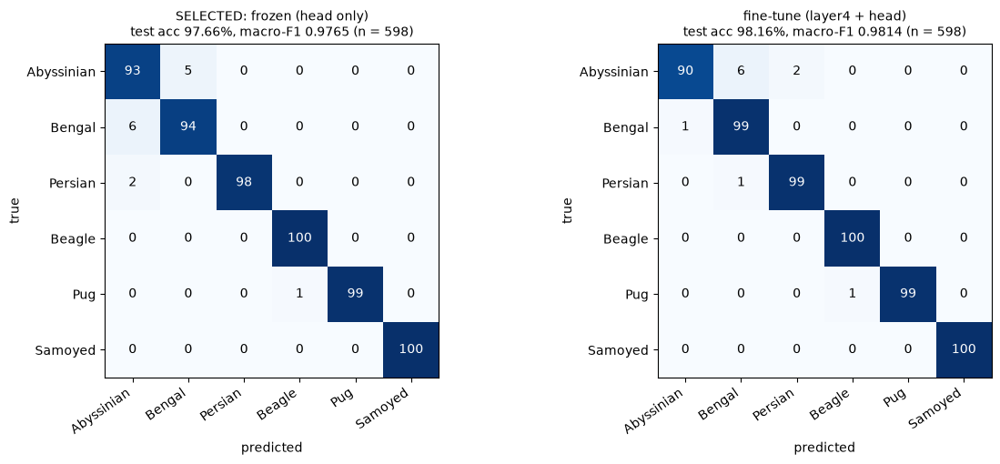

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12.5, 5.2))
for a, c in zip(ax, [overall] + [x for x in CONDS if x != overall]):
    cm = np.array(T[c]["cm"])
    a.imshow(cm, cmap="Blues")
    for i in range(K):
        for j in range(K):
            a.text(j, i, cm[i, j], ha="center", va="center", fontsize=10, color="white" if cm[i, j] > cm.max() / 2 else "black")
    a.set_xticks(range(K)); a.set_xticklabels(BREEDS, rotation=35, ha="right")
    a.set_yticks(range(K)); a.set_yticklabels(BREEDS)
    a.set_xlabel("predicted"); a.set_ylabel("true")
    a.set_title(f"{'SELECTED: ' if c == overall else ''}{lab[c]}\ntest acc {100 * T[c]['acc']:.2f}%, macro-F1 {T[c]['macro_f1']:.4f} (n = {test['n']})", fontsize=10)
fig.tight_layout()
fig.savefig(FIG / "fig2_confusion_matrices.png", dpi=150)
plt.show()

Every cat error involves Abyssinian or Bengal, as the true or the predicted breed. Those are the two breeds that are not ImageNet-1K classes, whereas Persian cat, beagle, pug and Samoyed all are, so the pretrained features were never trained to tell these two apart. Fine-tuning does not remove the Abyssinian–Bengal confusion, it moves it: Bengal errors drop from 6 to 1, while Abyssinian errors rise from 5 to 8.

Both models are scored on the same 598 photos, so the fair comparison is a paired one: what matters is the photos that only one of the two gets right. The exact McNemar test uses exactly those disagreements, and a paired bootstrap over the test photos gives 95% intervals for the differences in accuracy and macro-F1.

In [15]:
pc = test["paired"]
display(pd.DataFrame({"fine-tune correct": [pc["both_correct"], pc["only_finetune"]],
                      "fine-tune wrong": [pc["only_frozen"], pc["both_wrong"]]}, index=["frozen correct", "frozen wrong"]))
print(f"exact McNemar p = {pc['mcnemar_p']:.4f}")
print(f"accuracy difference (fine-tune - frozen) {100 * pc['d_acc']:+.2f} pp, 95% CI [{100 * pc['d_acc_ci'][0]:+.2f}, {100 * pc['d_acc_ci'][1]:+.2f}]")
print(f"macro-F1 difference {pc['d_f1']:+.4f}, 95% CI [{pc['d_f1_ci'][0]:+.4f}, {pc['d_f1_ci'][1]:+.4f}]")
print(f"extra cost of fine-tuning: {S['finetune']['trainable'] - S['frozen']['trainable']:,} more trainable params, "
      f"{S['finetune']['train_time_total'] - S['frozen']['train_time_total']:.1f}s more training over {stop} epochs, "
      f"{S['finetune']['grad_adam_mib'] - S['frozen']['grad_adam_mib']:.1f} MiB more grad + Adam state; "
      f"test inference {T['frozen']['infer_time']:.1f}s vs {T['finetune']['infer_time']:.1f}s")
dis = pred_df[pred_df.pred_frozen != pred_df.pred_finetune]
print(len(dis), "test images where the two models disagree")
dis[["image_id", "true", "pred_frozen", "p_true_frozen", "pred_finetune", "p_true_finetune"]]

,fine-tune correct,fine-tune wrong
frozen correct,578,6
frozen wrong,9,5


exact McNemar p = 0.6072
accuracy difference (fine-tune - frozen) +0.50 pp, 95% CI [-0.67, +1.67]
macro-F1 difference +0.0049, 95% CI [-0.0080, +0.0176]
extra cost of fine-tuning: 8,393,728 more trainable params, 19.2s more training over 100 epochs, 96.1 MiB more grad + Adam state; test inference 2.4s vs 2.4s
16 test images where the two models disagree


,image_id,true,pred_frozen,p_true_frozen,pred_finetune,p_true_finetune
12,Abyssinian_217,Abyssinian,Abyssinian,0.798733,Bengal,0.369953
14,Abyssinian_21,Abyssinian,Abyssinian,0.492859,Persian,0.089596
16,Abyssinian_221,Abyssinian,Bengal,0.376950,Abyssinian,0.530276
17,Abyssinian_223,Abyssinian,Bengal,0.179641,Abyssinian,0.603753
33,Abyssinian_32,Abyssinian,Abyssinian,0.978503,Bengal,0.458658
47,Abyssinian_50,Abyssinian,Abyssinian,0.805647,Persian,0.315362
49,Abyssinian_52,Abyssinian,Abyssinian,0.931136,Bengal,0.434003
72,Abyssinian_76,Abyssinian,Abyssinian,0.712106,Bengal,0.450576
87,Abyssinian_90,Abyssinian,Bengal,0.407684,Abyssinian,0.545247
225,Bengal_34,Bengal,Abyssinian,0.339110,Bengal,0.510127


Fine-tuning fixes 9 photos and breaks 6. The exact McNemar p is 0.61, the 95% interval for the accuracy difference runs from −0.67 to +1.67 points, and the macro-F1 interval (−0.0080 to +0.0176) also contains zero. All 16 photos the two models disagree on are cats. So on this task I can't show that fine-tuning helps: it is cheap at this scale, but what it really costs is care, since it only works with validation-based checkpoint selection, while the frozen head was stable for 100 epochs.

### Error analysis
These are the three most confident test errors of the overall pick, chosen by the rule fixed before testing. Each image is the 224×224 center crop the model actually sees, and the bars show both models' probabilities.

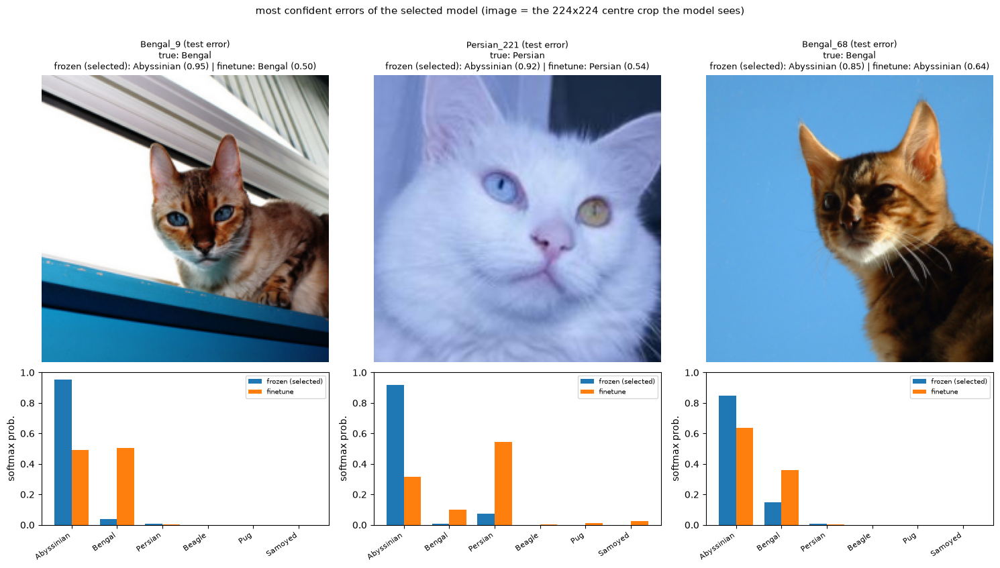

,kind,image_id,true,pred_frozen,conf_frozen,pred_finetune,conf_finetune
0,test error,Bengal_9,Bengal,Abyssinian,0.954086,Bengal,0.504067
1,test error,Persian_221,Persian,Abyssinian,0.919177,Persian,0.544965
2,test error,Bengal_68,Bengal,Abyssinian,0.846525,Abyssinian,0.635790


In [16]:
other = [c for c in CONDS if c != overall][0]
errs = pred_df[pred_df[f"pred_{overall}"] != pred_df.true].sort_values(f"conf_{overall}", ascending=False, kind="stable")
cases = [dict(r, source="test", kind="test error") for r in errs.head(3).to_dict("records")]
if len(cases) < 3:
    ve = val_df[val_df[f"pred_{overall}"] != val_df.true].sort_values(f"conf_{overall}", ascending=False, kind="stable")
    cases += [dict(r, source="val", kind="validation error") for r in ve.head(3 - len(cases)).to_dict("records")]
if len(cases) < 3:
    lc = pred_df[pred_df[f"pred_{overall}"] == pred_df.true].sort_values(f"conf_{overall}", kind="stable")
    cases += [dict(r, source="test", kind="low-confidence correct") for r in lc.head(3 - len(cases)).to_dict("records")]

def show(t):
    return (t.cpu() * torch.tensor(std)[:, None, None] + torch.tensor(mean)[:, None, None]).clamp(0, 1).permute(1, 2, 0).numpy()

def get_img(cs):
    ds = test_full if cs["source"] == "test" else dev_eval
    x, yy = ds[int(cs["dataset_index"])]
    return x, yy, Path(ds._images[int(cs["dataset_index"])]).stem

mdl = {c: load_sel(c) for c in CONDS}
fig, ax = plt.subplots(2, len(cases), figsize=(5 * len(cases), 8.6), gridspec_kw={"height_ratios": [3, 1.4]}, squeeze=False)
for j, cs in enumerate(cases):
    x, yy, iid = get_img(cs)
    assert iid == cs["image_id"] and BREEDS[yy] == cs["true"]
    with torch.no_grad():
        pr = {c: mdl[c](x[None].to(device)).softmax(1)[0].cpu().numpy() for c in CONDS}
    for c in CONDS:
        if abs(pr[c].max() - cs[f"conf_{c}"]) > 1e-3:
            warnings.warn(f"{iid} {c}: {pr[c].max():.5f} vs saved {cs[f'conf_{c}']:.5f}")
    ax[0, j].imshow(show(x)); ax[0, j].axis("off")
    ax[0, j].set_title(f"{iid} ({cs['kind']})\ntrue: {cs['true']}\n{overall} (selected): {cs[f'pred_{overall}']} "
                       f"({cs[f'conf_{overall}']:.2f}) | {other}: {cs[f'pred_{other}']} ({cs[f'conf_{other}']:.2f})", fontsize=9)
    xs = np.arange(K)
    ax[1, j].bar(xs - 0.19, pr[overall], 0.38, color=col[overall], label=f"{overall} (selected)")
    ax[1, j].bar(xs + 0.19, pr[other], 0.38, color=col[other], label=other)
    ax[1, j].set_xticks(xs); ax[1, j].set_xticklabels(BREEDS, rotation=35, ha="right", fontsize=8)
    ax[1, j].set_ylim(0, 1); ax[1, j].set_ylabel("softmax prob."); ax[1, j].legend(fontsize=7)
fig.suptitle("most confident errors of the selected model (image = the 224x224 centre crop the model sees)", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.97))
fig.savefig(FIG / "fig3_error_cases.png", dpi=150)
plt.show()
pd.DataFrame(cases)[["kind", "image_id", "true", "pred_frozen", "conf_frozen", "pred_finetune", "conf_finetune"]]

All three are cats called Abyssinian with 85–95% confidence, and in each one the face dominates the crop, while the face is not what separates these breeds.

**Bengal_9.** A backlit head under a window blind, with almost none of the spotted coat visible. Fine-tuning gets it right, but barely (Bengal 0.50 vs. Abyssinian 0.49).

**Persian_221.** A white, odd-eyed cat with large upright ears and a longer muzzle than the flat-faced Persians that make up most of this class. It does not look like a typical Persian, and I can't rule out an unusual cat or a labeling error. Fine-tuning gets it right (0.54).

**Bengal_68.** A ruddy face against a blue sky, with the marbled pattern only on the shoulder. Both models are wrong; fine-tuning is just less sure (0.64).

In [17]:
for c in CONDS:
    e = pred_df[pred_df[f"pred_{c}"] != pred_df.true]
    print(f"\n{c}: {len(e)} test errors")
    print(e.groupby(["true", f"pred_{c}"]).size().rename("n").to_string())


frozen: 14 test errors
true        pred_frozen
Abyssinian  Bengal         5
Bengal      Abyssinian     6
Persian     Abyssinian     2
Pug         Beagle         1

finetune: 11 test errors
true        pred_finetune
Abyssinian  Bengal           6
            Persian          2
Bengal      Abyssinian       1
Persian     Bengal           1
Pug         Beagle           1


The frozen model makes 14 test errors, 13 of them on cats; the fine-tuned model makes 11, 10 of them on cats. The only dog error is the same Pug→Beagle photo for both models.

### Paired Grad-CAM
I use Lab 7b's Grad-CAM with a hook on `layer4`. Both models use the true breed as the target and run in eval mode with gradients enabled. The input is made differentiable, which the frozen model needs, because otherwise its `layer4` output is not part of the autograd graph at all. Image A is the disagreement with the largest change in the probability of the true breed, and image B is one that both models get wrong. For ResNet18 at this layer, Grad-CAM is exactly the classic CAM divided by 49, and the last column of the table checks that identity for every map. A supplement after the table repeats both photos with a second target, the breed the selected model predicted.

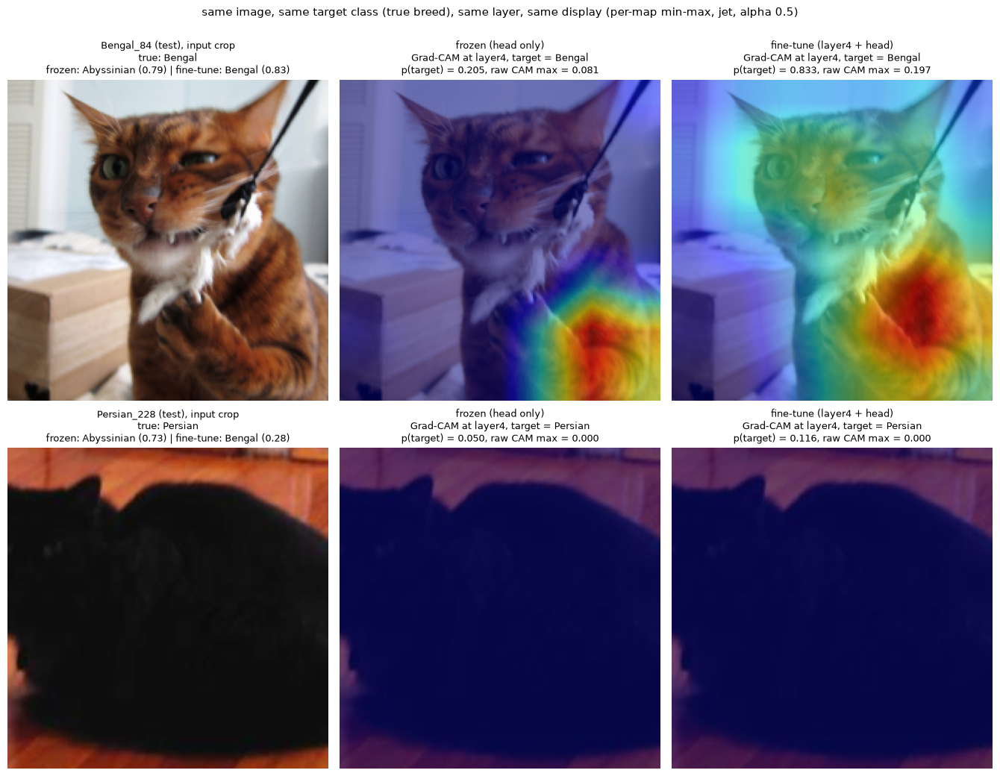

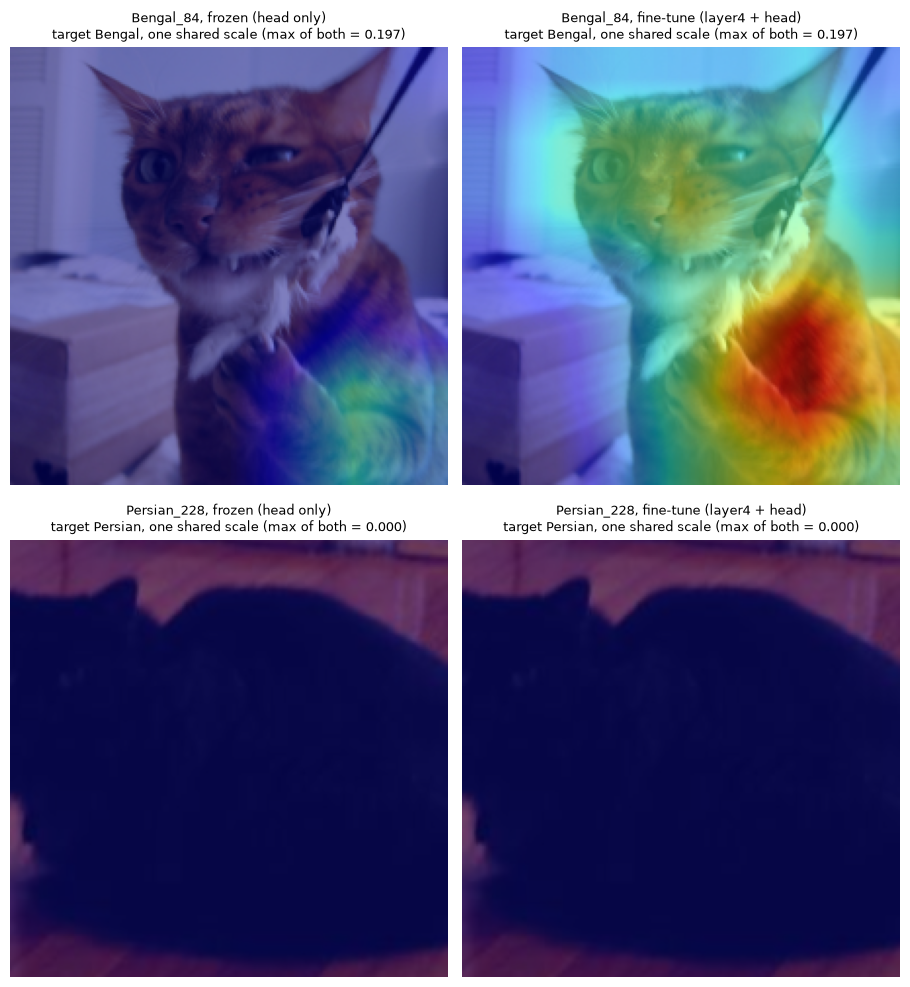

correlation between the two 7x7 maps: {'Bengal_84': 0.629, 'Persian_228': None}


,image_id,why,true,model,pred,p_target,target_logit,raw_cam_max,raw_cam_mean,cells_above_half,peak_cell,gradcam_vs_cam_dev
0,Bengal_84,the two models disagree (largest change in p(t...,Bengal,frozen,Abyssinian,0.2046,-0.6327,0.0807,0.008,4,"5,5",5.6e-08
1,Bengal_84,the two models disagree (largest change in p(t...,Bengal,finetune,Bengal,0.8332,3.6315,0.1966,0.074,10,"5,5",7.8e-07
2,Persian_228,both models wrong,Persian,frozen,Abyssinian,0.0498,-3.3974,0.0000,0.000,0,"0,0",1.6e-07
3,Persian_228,both models wrong,Persian,finetune,Bengal,0.1158,-1.3810,0.0000,0.000,0,"0,0",5.2e-08


In [18]:
def gradcam(m, x, target):
    m.eval()
    store = {}
    hk = m.layer4.register_forward_hook(lambda mod, i, o: store.update(A=o))
    try:
        with torch.enable_grad():
            xi = x.detach().clone().requires_grad_(True)
            out = m(xi)
            A = store["A"]
            g = torch.autograd.grad(out[0, target], A)[0]
    finally:
        hk.remove()
    w = g.mean((2, 3), keepdim=True)
    lin = (w * A).sum(1)[0].detach()
    raw = F.relu(lin)
    cam = (raw - raw.min()) / (raw.max() - raw.min() + 1e-6)
    up = F.interpolate(cam[None, None], size=(224, 224), mode="bilinear", align_corners=False)[0, 0]
    return dict(cam=cam.cpu().numpy(), up=up.cpu().numpy(), raw=raw.cpu().numpy(), lin=lin.cpu().numpy(),
                A=A.detach().cpu(), prob=out.detach().softmax(1)[0].cpu().numpy(), logit=out[0, target].item())

def cam_check(m, r, target):
    wc, bc = m.fc.weight[target].detach().cpu(), m.fc.bias[target].item()
    manual = F.relu((wc[:, None, None] * r["A"][0]).sum(0) / (r["A"].shape[2] * r["A"].shape[3]))
    return max((manual - torch.as_tensor(r["raw"])).abs().max().item(), abs(float(r["lin"].sum()) + bc - r["logit"]))

overlay = lambda img, cam: np.clip(0.5 * img + 0.5 * plt.cm.jet(cam)[..., :3], 0, 1)

d = pred_df.copy()
d["wf"], d["wt"] = d.pred_frozen != d.true, d.pred_finetune != d.true
chosen = []
dd = d[d.pred_frozen != d.pred_finetune]
if len(dd):
    chosen.append(dict(dd.loc[(dd.p_true_finetune - dd.p_true_frozen).abs().idxmax()], why="the two models disagree (largest change in p(true))"))
rest = d[(d.wf | d.wt) & ~d.image_id.isin([c["image_id"] for c in chosen])]
if (rest.wf & rest.wt).any():
    bw = rest[rest.wf & rest.wt]
    chosen.append(dict(bw.loc[(2 - bw.p_true_frozen - bw.p_true_finetune).idxmax()], why="both models wrong"))
elif len(rest):
    chosen.append(dict(rest.loc[np.maximum(1 - rest.p_true_frozen, 1 - rest.p_true_finetune).idxmax()], why="misclassified by one model"))
for r in d.assign(mn=np.minimum(d.p_true_frozen, d.p_true_finetune)).sort_values("mn", kind="stable").to_dict("records"):
    if len(chosen) >= 2:
        break
    if r["image_id"] not in [c["image_id"] for c in chosen]:
        chosen.append(dict(r, why="low-confidence correct (no more errors)"))
chosen = [dict(c, source="test") for c in chosen[:2]]

gc = []
for cs in chosen:
    x, yy, iid = get_img(cs)
    assert iid == cs["image_id"]
    t = int(cs["label"])
    r = {c: gradcam(mdl[c], x[None].to(device), t) for c in CONDS}
    for c in CONDS:
        r[c]["dev"] = cam_check(mdl[c], r[c], t)
        if abs(r[c]["prob"].max() - cs[f"conf_{c}"]) > 1e-3:
            warnings.warn(f"{iid} {c}: Grad-CAM forward {r[c]['prob'].max():.5f} vs saved {cs[f'conf_{c}']:.5f}")
    gc.append((cs, x, iid, t, r))

fig, ax = plt.subplots(len(gc), 3, figsize=(13.5, 5.4 * len(gc)), squeeze=False)
for i, (cs, x, iid, t, r) in enumerate(gc):
    img = show(x)
    ax[i, 0].imshow(img)
    ax[i, 0].set_title(f"{iid} (test), input crop\ntrue: {cs['true']}\nfrozen: {cs['pred_frozen']} ({cs['conf_frozen']:.2f}) | "
                       f"fine-tune: {cs['pred_finetune']} ({cs['conf_finetune']:.2f})", fontsize=9)
    for j, c in enumerate(CONDS, 1):
        ax[i, j].imshow(overlay(img, r[c]["up"]))
        ax[i, j].set_title(f"{lab[c]}\nGrad-CAM at layer4, target = {BREEDS[t]}\np(target) = {r[c]['prob'][t]:.3f}, "
                           f"raw CAM max = {r[c]['raw'].max():.3f}", fontsize=9)
    for a in ax[i]:
        a.axis("off")
fig.suptitle("same image, same target class (true breed), same layer, same display (per-map min-max, jet, alpha 0.5)", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.97), h_pad=2.5)
fig.savefig(FIG / "fig4_gradcam_pairs.png", dpi=150)
plt.show()

fig, ax = plt.subplots(len(gc), 2, figsize=(9.2, 5.0 * len(gc)), squeeze=False)
for i, (cs, x, iid, t, r) in enumerate(gc):
    img, vmax = show(x), max(r[c]["raw"].max() for c in CONDS) + 1e-6
    for j, c in enumerate(CONDS):
        up = F.interpolate(torch.as_tensor(r[c]["raw"])[None, None] / vmax, size=(224, 224), mode="bilinear", align_corners=False)[0, 0].numpy()
        ax[i, j].imshow(overlay(img, up)); ax[i, j].axis("off")
        ax[i, j].set_title(f"{iid}, {lab[c]}\ntarget {BREEDS[t]}, one shared scale (max of both = {vmax:.3f})", fontsize=9)
fig.tight_layout(h_pad=2.0)
fig.savefig(FIG / "figS1_gradcam_shared_scale.png", dpi=130)
plt.show()

gsum = []
for cs, x, iid, t, r in gc:
    for c in CONDS:
        pk = np.unravel_index(np.argmax(r[c]["cam"]), r[c]["cam"].shape)
        gsum.append(dict(image_id=iid, why=cs["why"], true=BREEDS[t], model=c, pred=cs[f"pred_{c}"],
                         p_target=round(float(r[c]["prob"][t]), 4), target_logit=round(r[c]["logit"], 4),
                         raw_cam_max=round(float(r[c]["raw"].max()), 4), raw_cam_mean=round(float(r[c]["raw"].mean()), 4),
                         cells_above_half=int((r[c]["cam"] > 0.5).sum()), peak_cell=f"{pk[0]},{pk[1]}",
                         gradcam_vs_cam_dev=f"{r[c]['dev']:.1e}"))
def map_corr(a, b):
    a, b = np.ravel(a), np.ravel(b)
    return round(float(np.corrcoef(a, b)[0, 1]), 3) if a.std() > 0 and b.std() > 0 else None   # undefined for an empty map

corr = {iid: map_corr(r["frozen"]["cam"], r["finetune"]["cam"]) for cs, x, iid, t, r in gc}
pd.DataFrame(gsum).to_csv(RES / "gradcam_summary.csv", index=False)
dump({"map_correlation": corr}, RES / "gradcam_correlation.json")
print("correlation between the two 7x7 maps:", corr)
pd.DataFrame(gsum)

**Bengal_84.** The frozen model says Abyssinian and the fine-tuned model says Bengal (0.83). Both put their Bengal evidence on the spotted chest and flank rather than the face, which fits the error analysis: the coat is the cue, and the face is something Bengals share with Abyssinians. The difference is mostly strength: raw maximum 0.081 vs. 0.197, and 4 vs. 10 of the 49 cells above half of the maximum. The peak cell is the same, and the two maps correlate at 0.63. On one shared scale (second figure) the frozen map nearly disappears, which the per-map normalization in the first figure hides.

**Persian_228.** A black cat seen from behind, basically a silhouette. For the target Persian, both maps are completely empty. The Persian logit is negative in both models (−3.40 and −1.38), and all 49 locations contribute zero or negative evidence, so the ReLU removes everything. A constant map has zero variance, so the correlation between the two maps is undefined (printed as None).

**The limit.** Grad-CAM here only shows positive evidence for the target class. It can't tell me why the true class lost or what pushed the model toward Abyssinian or Bengal, and a blank map means "no positive evidence anywhere," not "the model looked nowhere."

### Supplement: the evidence for the predicted breed
An empty map for the true breed says nothing about what pushed a model toward another breed. As a descriptive supplement, added after the locked results were known, the next cell repeats both photos with the target set to the breed the selected (frozen) model predicted, Abyssinian for both photos, again with the same target, layer and display settings in both models.

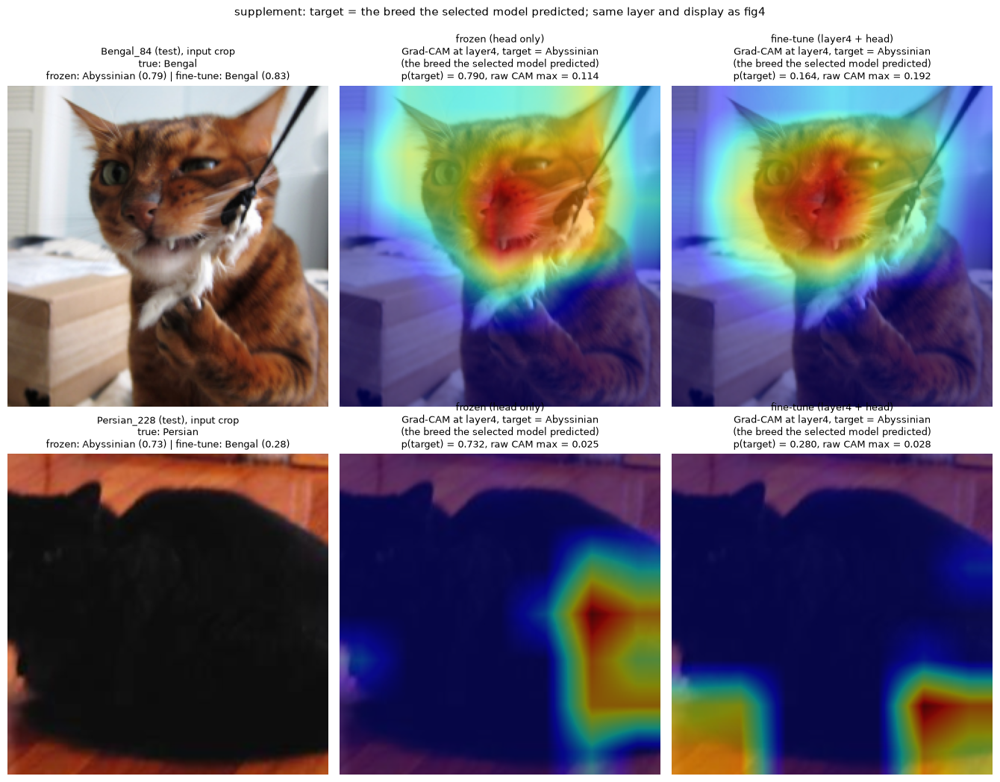

correlation between the two 7x7 maps: {'Bengal_84': 0.877, 'Persian_228': 0.28}


,image_id,true,target,model,pred,p_target,target_logit,raw_cam_max,cells_above_half,peak_cell,gradcam_vs_cam_dev
0,Bengal_84,Bengal,Abyssinian,frozen,Abyssinian,0.7901,0.7186,0.1141,14,"2,3",2.6e-07
1,Bengal_84,Bengal,Abyssinian,finetune,Bengal,0.1639,2.0057,0.1918,12,"2,3",1.4e-07
2,Persian_228,Persian,Abyssinian,frozen,Abyssinian,0.7315,-0.7095,0.0250,7,"3,5",2.0e-07
3,Persian_228,Persian,Abyssinian,finetune,Bengal,0.2796,-0.4999,0.0282,8,"5,5",1.0e-07


In [19]:
# Supplement, added after the locked results were known (descriptive, not part of the lock): the same two photos with the
# target set to the breed the selected model predicted, again the same target, layer and display in both models
sup = []
for cs, x, iid, t, r0 in gc:
    tp = BREEDS.index(cs[f"pred_{overall}"])
    if tp == t:
        continue
    rr = {c: gradcam(mdl[c], x[None].to(device), tp) for c in CONDS}
    for c in CONDS:
        rr[c]["dev"] = cam_check(mdl[c], rr[c], tp)
    sup.append((cs, x, iid, tp, rr))
fig, ax = plt.subplots(len(sup), 3, figsize=(13.5, 5.4 * len(sup)), squeeze=False)
for i, (cs, x, iid, tp, rr) in enumerate(sup):
    img = show(x)
    ax[i, 0].imshow(img)
    ax[i, 0].set_title(f"{iid} (test), input crop\ntrue: {cs['true']}\nfrozen: {cs['pred_frozen']} ({cs['conf_frozen']:.2f}) | "
                       f"fine-tune: {cs['pred_finetune']} ({cs['conf_finetune']:.2f})", fontsize=9)
    for j, c in enumerate(CONDS, 1):
        ax[i, j].imshow(overlay(img, rr[c]["up"]))
        ax[i, j].set_title(f"{lab[c]}\nGrad-CAM at layer4, target = {BREEDS[tp]}\n(the breed the selected model predicted)\n"
                           f"p(target) = {rr[c]['prob'][tp]:.3f}, raw CAM max = {rr[c]['raw'].max():.3f}", fontsize=9)
    for a in ax[i]:
        a.axis("off")
fig.suptitle("supplement: target = the breed the selected model predicted; same layer and display as fig4", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.97), h_pad=2.5)
fig.savefig(FIG / "figS2_gradcam_predicted_breed.png", dpi=150)
plt.show()
sup_tab = pd.DataFrame([dict(image_id=iid, true=cs["true"], target=BREEDS[tp], model=c, pred=cs[f"pred_{c}"],
                             p_target=round(float(rr[c]["prob"][tp]), 4), target_logit=round(rr[c]["logit"], 4),
                             raw_cam_max=round(float(rr[c]["raw"].max()), 4), cells_above_half=int((rr[c]["cam"] > 0.5).sum()),
                             peak_cell="{},{}".format(*np.unravel_index(np.argmax(rr[c]["cam"]), rr[c]["cam"].shape)),
                             gradcam_vs_cam_dev=f"{rr[c]['dev']:.1e}")
                        for cs, x, iid, tp, rr in sup for c in CONDS])
sup_tab.to_csv(RES / "gradcam_supplement.csv", index=False)
print("correlation between the two 7x7 maps:", {iid: map_corr(rr["frozen"]["cam"], rr["finetune"]["cam"]) for cs, x, iid, tp, rr in sup})
sup_tab


**What the supplement shows.** With Abyssinian as the common target, the evidence moves to the face. On Bengal_84 both models put their Abyssinian evidence on the face and mouth, with the same peak cell, while their Bengal evidence in fig4 sat on the spotted chest and flank: the face argues for Abyssinian and the coat for Bengal, as the error analysis suggested. Fine-tuning strengthens the coat evidence most: the Bengal logit rises from −0.63 to 3.63 and the Abyssinian logit only from 0.72 to 2.01, so the answer flips. On Persian_228 the Abyssinian evidence is weak (raw maximum 0.025 and 0.028, against 0.11 and 0.19 on Bengal_84) and lies on the right end of the dark body and the floor beside it, not on the head. The Abyssinian logit is negative there too (−0.71 and −0.50): the frozen model says Abyssinian because every other breed scores even lower, which no single map can show.

### Sensitivity check: the assignment's literal stopping rule
The assignment says to train until validation accuracy plateaus for 2 consecutive epochs, with at least 5 epochs. My locked protocol only starts checking for the plateau at epoch 100. The training cell already worked out on validation alone what the literal rule would have done: both models stop at epoch 5, and the selection rule picks epoch 4 for the frozen model and epoch 1 for the fine-tuned one.

Here those two checkpoints are rebuilt from the saved warm-up, epoch by epoch. Every epoch has to reproduce the batch hash and the validation result logged during the locked run. Then both checkpoints are scored once on the test set and compared exactly as above. I added this after the locked test results were known, but it leaves no choice open: the rule is the assignment's, and the epochs it selects were computed on validation before the test set was ever loaded. Its only purpose is to show whether the conclusion depends on my longer epoch budget.

In [20]:
def lit_check():
    ts_ = json.loads((RES / "training_summary.json").read_text(encoding="utf-8"))
    u5 = ts_["under_floor_5"]
    if u5 is None:
        print("under the literal rule the plateau never came within the logged epochs, so there is nothing to rebuild")
        return pd.DataFrame()
    sel = {c: int(u5["selected"][c]) for c in CONDS}
    h_ = pd.read_csv(RES / "history.csv", dtype={"batches_hash": str})
    w_ = torch.load(CKPT / "warmup_head.pt", map_location="cpu")
    pz = np.load(RES / "test_probs.npz")
    yv = pz["y"]
    P_ = {}
    for c in CONDS:
        m_ = build()
        m_.load_state_dict(w_)
        m_ = setup(m_, c).to(device)
        o_ = make_opt(m_, c)
        for ep in range(1, sel[c] + 1):
            tr_ = run_epoch(m_, o_, ep)
            va_ = evaluate(m_, val_ds)
            row = h_[(h_.condition == c) & (h_.epoch == ep)].iloc[0]
            assert tr_["batches_hash"] == row.batches_hash, f"{c} epoch {ep}: not the logged batches"
            assert va_["correct"] == row.val_correct and abs(va_["loss"] - row.val_loss) < 1e-5, f"{c} epoch {ep}: not reproduced"
        lg_, yt_ = predict(m_, test_ds)
        assert np.array_equal(yt_.numpy(), yv)
        P_[c] = lg_.softmax(1).numpy()
        if sel[c] == ts_["cond"][c]["selected_epoch"]:
            assert np.abs(P_[c] - pz[c]).max() < 1e-5, f"{c}: the rebuilt checkpoint differs from the locked one"
        del m_
    np.savez(RES / "literal_rule_test_probs.npz", y=yv, **P_)
    tm_ = json.loads((RES / "test_metrics.json").read_text(encoding="utf-8"))

    def paired(pf, pt):
        cf, ct = pf == yv, pt == yv
        b10, b01 = int((cf & ~ct).sum()), int((~cf & ct).sum())
        rng = np.random.default_rng(SEED)
        da = np.empty(10000)
        for b in range(10000):
            i = rng.integers(0, len(yv), len(yv))
            da[b] = ct[i].mean() - cf[i].mean()
        return dict(frozen=int(cf.sum()), finetune=int(ct.sum()), f1_frozen=macro_f1(yv, pf), f1_finetune=macro_f1(yv, pt),
                    d_pp=100 * (ct.mean() - cf.mean()), ci=[100 * np.percentile(da, 2.5), 100 * np.percentile(da, 97.5)],
                    p=float(binomtest(min(b10, b01), b10 + b01, 0.5).pvalue) if b10 + b01 else 1.0)

    pz_locked = np.load(RES / "test_probs.npz")
    rows = []
    for name, E_, s_, P2 in (("locked protocol (plateau checks from epoch 100)", ts_["E"],
                               {c: ts_["cond"][c]["selected_epoch"] for c in CONDS}, {c: pz_locked[c] for c in CONDS}),
                              ("the assignment's literal rule (floor of 5 epochs)", u5["E"], sel, P_)):
        r = paired(P2["frozen"].argmax(1), P2["finetune"].argmax(1))
        rows.append({"protocol": name, "epochs": E_, "selected epoch, frozen": s_["frozen"], "selected epoch, fine-tune": s_["finetune"],
                     "frozen correct": f"{r['frozen']}/{len(yv)}", "fine-tune correct": f"{r['finetune']}/{len(yv)}",
                     "macro-F1, frozen": round(r["f1_frozen"], 4), "macro-F1, fine-tune": round(r["f1_finetune"], 4),
                     "fine-tune minus frozen (pp)": round(r["d_pp"], 2), "95% CI": f"[{r['ci'][0]:+.2f}, {r['ci'][1]:+.2f}]",
                     "exact McNemar p": round(r["p"], 4)})
    assert rows[0]["frozen correct"] == f"{tm_['cond']['frozen']['correct']}/{tm_['n']}"
    dump(dict(rows=rows, note="literal-rule checkpoints rebuilt from the warm-up and checked against the logged run"),
         RES / "literal_rule_check.json")
    return pd.DataFrame(rows).set_index("protocol")


lit_tab = lit_check()
lit_tab

,epochs,"selected epoch, frozen","selected epoch, fine-tune",frozen correct,fine-tune correct,"macro-F1, frozen","macro-F1, fine-tune",fine-tune minus frozen (pp),95% CI,exact McNemar p
protocol,,,,,,,,,,
locked protocol (plateau checks from epoch 100),100,20,1,584/598,587/598,0.9765,0.9814,0.5,"[-0.67, +1.67]",0.6072
the assignment's literal rule (floor of 5 epochs),5,4,1,584/598,587/598,0.9765,0.9814,0.5,"[-0.84, +1.67]",0.6072


The conclusion does not depend on my longer epoch budget. Under the assignment's literal rule, the frozen model is selected at epoch 4 instead of 20 and still gets 584 of the 598 test photos right; the fine-tuned model is selected at epoch 1 either way, so it is the same checkpoint, with the same 587. The macro-F1 values and the McNemar p (0.6072) are unchanged. Only the bootstrap interval moves slightly at its lower end (−0.84 to +1.67 points instead of −0.67 to +1.67), because the epoch-4 frozen model makes the same number of errors on partly different photos. Every rebuilt epoch reproduced the logged batches and validation results.

In [21]:
bundle = OUT / f"d370_results_bundle{sfx}.zip"
with zipfile.ZipFile(bundle, "w", zipfile.ZIP_DEFLATED) as z:
    for d in (RES, FIG):
        for f in sorted(d.rglob("*")):
            if f.is_file():
                z.write(f, f.relative_to(OUT))
print(f"{bundle.name}: {bundle.stat().st_size / 2**20:.1f} MiB")

d370_results_bundle.zip: 12.6 MiB


This bundle covers Part 1. The last cell of the notebook rebuilds it with Part 2 included.

## Part 2. Extension: what is color worth?
The extension has two halves. Part 2a takes color away from all 80 training photos per breed and repeats Part 1 over five seeds. Part 2b, after Part 2a's results, varies the number of training photos and changes only the colors of the test photos, with its own lock.

### Where the idea came from, and why color
The idea for this extension is Prof. Lo's. My own first idea was to teach the model a new breed from photos of my own dog. When I brought it to his office hours, he suggested a black-and-white comparison instead: let the models learn from black-and-white photos and see what they can still do. I took his suggestion, and the rest of this part is how I turned it into an experiment.

It also fits what Part 1 left open. There the frozen ImageNet features already do almost all of the work, which made me want to know what those features rely on, and color is the obvious candidate. A Samoyed is white, a Pug is usually fawn with a black mask, an Abyssinian is usually a warm ruddy brown, and a Bengal is usually golden with dark spots.

Two findings make color worth testing. In controlled synthetic datasets, Hermann and Lampinen (2020) found that when several features predict the label, networks favor the one that is easiest to read out, and color was easier to read out than shape or texture; an easy feature can even push aside a harder one that predicts better. So a network may rely on color without needing it. For people, the meta-analysis of Bramão et al. (2011) found that color helps recognition mostly when it is diagnostic, meaning that an object's color is part of what it is (d = 0.43 for color-diagnostic objects, against 0.18 for the rest). Breeds are a good test of that idea, since some are defined partly by their coat color and others come in many colors.

### What I compare
In Part 2a, I repeat Part 1 with every photo converted to black and white and nothing else changed. The split, the one-epoch head-only warm-up, the two models in lockstep, the epoch rule (floor 100, plateau 2, cap 200) and the validation-based selection are all Part 1's. A black-and-white model is also validated in black and white. Every model is then scored on the 598 test photos twice, once in color and once in black and white, which gives four combinations for each model type.

The main question, fixed in the lock, is how much each model loses when color is gone everywhere: the model trained and tested in black and white against the same kind of model trained and tested in color. The combination closest to Prof. Lo's suggestion is a model that learned only from black-and-white photos and then has to recognize normal color photos; it was locked as a descriptive result, together with the reverse case, a color model shown black-and-white photos.

The color models for seed 42 are the two models of Part 1. Seeds 1 to 4 repeat both the color and the black-and-white training, which shows how far the answers move from seed to seed, something one seed cannot show. All of this uses the full training split, 80 photos per breed.

### What I expected
These three expectations were written into the notebook and the lock file before any black-and-white test result existed:
- if color matters anywhere here, it is among the three cat breeds, where all of the color models' errors already are;
- a color-trained model scored on black-and-white test photos does worse than the same kind of model trained on black and white;
- least certain: fine-tuning gains more without color, because `layer4` can adapt to the new input and a frozen backbone cannot.

### How the black-and-white photos are made
`transforms.Grayscale` turns each photo into its ITU-R 601 luma, which is copied into all three channels and then normalized with the same ImageNet statistics, so the network and its input size stay exactly the same. The conversion comes after the random crop and flip and uses no randomness, so a black-and-white run sees the same crops and flips, in the same order, as the color run with the same seed. To keep ten training pairs affordable, every photo is decoded and resized once and kept in memory; `Resize(256)` is deterministic, so applying the rest of the pipeline at each access gives the same tensors as Part 1, and the cell after next checks this instead of assuming it.

In [22]:
missing = [n for n in ("CONDS", "build", "setup", "make_opt", "train_mode", "evaluate", "predict", "better", "since_best",
                       "warm_device", "macro_f1", "tf_train", "tf_eval", "dev_train", "dev_eval") if n not in globals()]
assert not missing, f"run the Setup, Data and Model cells first (missing: {missing})"
from PIL import Image

SEEDS = [42, 1, 2, 3, 4]        # 42 is the required run: its two color models are reused, not retrained
MODES = ["color", "gray"]
B_EXT = 10000                   # bootstrap resamples, as in the required part
EXT, EXT_CK = RES / "ext_gray", CKPT / "ext_gray"
for d in (EXT / "runs", EXT / "test", EXT_CK):
    d.mkdir(parents=True, exist_ok=True)
assert SEED in SEEDS, "the seed of the required run must be one of the seeds"
sha = lambda p: hashlib.sha256(Path(p).read_bytes()).hexdigest()

req_lock = json.loads((RES / "locked_choices.json").read_text(encoding="utf-8"))
for c in CONDS:
    assert sha(CKPT / f"{c}_selected.pt") == req_lock["selected"][c]["sha256"], f"{c}: checkpoint does not match the required lock"
sp = json.loads((RES / "split.json").read_text(encoding="utf-8"))
lab_map = {sp["original_label"][b]: sp["new_label"][b] for b in BREEDS}
base_dev = OxfordIIITPet(DATA_ROOT, split="trainval", target_types="category")
base_test = OxfordIIITPet(DATA_ROOT, split="test", target_types="category")
idx = {"train": sp["train_idx"], "val": sp["val_idx"], "test": [i for i, l in enumerate(base_test._labels) if l in lab_map]}
req_pred = pd.read_csv(RES / "test_predictions.csv")
assert [Path(base_dev._images[j]).stem for j in idx["train"]] == sp["train_ids"]
assert [Path(base_dev._images[j]).stem for j in idx["val"]] == sp["val_ids"]
assert [Path(base_test._images[j]).stem for j in idx["test"]] == req_pred.image_id.tolist()

# every image is decoded and resized once; Resize(256) is deterministic, so applying the rest of the
# transform at each access gives exactly the tensors of the pipeline above (checked in the next cell)
t0 = time.perf_counter()
cache = {part: ([transforms.Resize(256)(Image.open(base._images[j]).convert("RGB")) for j in idx[part]],
                [lab_map[base._labels[j]] for j in idx[part]])
         for part, base in [("train", base_dev), ("val", base_dev), ("test", base_test)]}

def tail(part, mode):
    t = [transforms.RandomCrop(224), transforms.RandomHorizontalFlip()] if part == "train" else [transforms.CenterCrop(224)]
    if mode == "gray":
        t.append(transforms.Grayscale(num_output_channels=3))
    return transforms.Compose(t + [transforms.ToTensor(), transforms.Normalize(mean, std)])

class View(torch.utils.data.Dataset):
    def __init__(self, part, mode):
        self.imgs, self.ys = cache[part]
        self.tf = tail(part, mode)
    def __len__(self):
        return len(self.ys)
    def __getitem__(self, i):
        return self.tf(self.imgs[i]), self.ys[i]

class LabelsOnly(torch.utils.data.Dataset):
    def __init__(self, ys):
        self.ys = ys
    def __len__(self):
        return len(self.ys)
    def __getitem__(self, i):
        return 0, self.ys[i]

DS = {(part, mode): View(part, mode) for part in cache for mode in MODES}
dump(dict(seeds=SEEDS, modes=MODES, bootstrap=B_EXT, gray="transforms.Grayscale(num_output_channels=3) after the crop and flip, "
          "before ToTensor and Normalize(ImageNet mean, std); ITU-R 601 luma", settings=settings, env=env), EXT / "ext_config.json")
print(f"{sum(len(v[1]) for v in cache.values())} images cached in {time.perf_counter() - t0:.1f}s:",
      {p: len(v[1]) for p, v in cache.items()})

1198 images cached in 2.9s: {'train': 480, 'val': 120, 'test': 598}


All 1,198 photos are cached in a few seconds. Four checks follow, and each one stops the notebook if it fails: the cached pipeline gives exactly the tensors of Part 1's pipeline, image by image, for the same random state; a black-and-white photo is the luma of the very same crop, with three identical channels; replaying Part 1's data stream from the cache reproduces the batch hashes that Part 1 logged; and Part 1's two models give their locked validation results and their saved test probabilities on the cached photos.

In [23]:
def make_loader(ds, seed, epoch):
    g = torch.Generator()
    g.manual_seed(seed * 1000 + epoch)
    loader = DataLoader(ds, batch_size=BATCH, shuffle=True, num_workers=NUM_WORKERS, generator=g)
    torch.manual_seed(seed * 1000 + epoch)
    return loader

def stream_hash(ds, seed, epoch, images=True):
    h = hashlib.sha256()
    for x, y in make_loader(ds, seed, epoch):
        h.update(y.numpy().astype(np.int64).tobytes())
        if images:
            h.update(np.float64(x.double().sum().item()).tobytes())
    return h.hexdigest()[:16]

labels_hash = lambda seed, epoch: stream_hash(LabelsOnly(cache["train"][1]), seed, epoch, images=False)
mt, st = torch.tensor(mean)[:, None, None], torch.tensor(std)[:, None, None]

# 1) the cache reproduces the original pipeline image by image (same RNG state -> identical tensor)
test_ref = OxfordIIITPet(DATA_ROOT, split="test", target_types="category", transform=tf_eval, target_transform=lab_map.__getitem__)
ref = {"train": Subset(dev_train, idx["train"]), "val": Subset(dev_eval, idx["val"]), "test": Subset(test_ref, idx["test"])}
for part, r in ref.items():
    for pos in (0, 1, len(r) - 1):
        torch.manual_seed(7 + pos); a, ya = r[pos]
        torch.manual_seed(7 + pos); b, yb = DS[part, "color"][pos]
        assert ya == yb and torch.equal(a, b), (part, pos)

# 2) the gray image is the luma of the very same crop, identical in all three channels
for part in cache:
    for pos in (0, 5):
        torch.manual_seed(11 + pos); xc = DS[part, "color"][pos][0] * st + mt
        torch.manual_seed(11 + pos); xg = DS[part, "gray"][pos][0] * st + mt
        assert (xg - xg[:1]).abs().max() < 1e-5, (part, pos)
        assert (0.299 * xc[0] + 0.587 * xc[1] + 0.114 * xc[2] - xg[0]).abs().max() <= 1 / 255 + 1e-5, (part, pos)

# 3) replaying the required run's data stream from the cache gives the hashes it logged
hist_req = pd.read_csv(RES / "history.csv", dtype={"batches_hash": str})
logged = {0: json.loads((RES / "warmup.json").read_text(encoding="utf-8"))["train"][0]["batches_hash"]}
logged.update({e: hist_req.loc[(hist_req.condition == "frozen") & (hist_req.epoch == e), "batches_hash"].item() for e in (1, 2)})
for e, h in logged.items():
    assert stream_hash(DS["train", "color"], SEED, e) == h, f"epoch {e}: the cached data stream differs from the logged one"

# 4) the reused seed-42 color models give the locked validation results and the saved test probabilities
req_probs = np.load(RES / "test_probs.npz")
for c in CONDS:
    m = build()
    m.load_state_dict(torch.load(CKPT / f"{c}_selected.pt", map_location="cpu"))
    m = setup(m, c).to(device).eval()
    v = evaluate(m, DS["val", "color"])
    assert v["correct"] == req_lock["selected"][c]["val_correct"] and abs(v["loss"] - req_lock["selected"][c]["val_loss"]) < 1e-5, (c, v)
    lg, yy = predict(m, DS["test", "color"])
    assert np.array_equal(yy.numpy(), req_probs["y"]) and np.abs(lg.softmax(1).numpy() - req_probs[c]).max() < 1e-5, c
del m
print("checks passed: the cached pipeline gives the original tensors; gray = luma of the same crop in 3 equal channels;",
      f"the logged data stream of epochs {sorted(logged)} is reproduced; the seed-42 color models reproduce their",
      "validation and test outputs")

checks passed: the cached pipeline gives the original tensors; gray = luma of the same crop in 3 equal channels; the logged data stream of epochs [0, 1, 2] is reproduced; the seed-42 color models reproduce their validation and test outputs


All four checks passed, on the real photos.

`train_pair` in the next cell is Part 1's training procedure wrapped in a function, with the input type and the seed as arguments: warm-up, both models side by side, the same epoch rule and the same selection rule. On top of Part 1's checks, it verifies that each epoch's mini-batch order is the one the seed implies. Finished pairs are reloaded instead of retrained, after their checkpoints are checked against the saved hashes.

In [24]:
def build_seed(seed):
    """build() from above, with the seed of the new head as an argument"""
    m = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    m.requires_grad_(False)
    torch.manual_seed(seed)
    m.fc = nn.Linear(512, len(BREEDS))
    return m

assert all(torch.equal(a, b) for a, b in zip(build_seed(SEED).state_dict().values(), build().state_dict().values()))

def ext_epoch(m, opt, epoch, ds, seed):
    """run_epoch from above, with the data set and the seed as arguments"""
    train_mode(m)
    loader = make_loader(ds, seed, epoch)
    h, hl = hashlib.sha256(), hashlib.sha256()
    tot, correct, n = 0.0, 0, 0
    sync()
    t0 = time.perf_counter()
    for x, y in loader:
        yb = y.numpy().astype(np.int64).tobytes()
        h.update(yb)
        h.update(np.float64(x.double().sum().item()).tobytes())
        hl.update(yb)
        x, y = x.to(device), y.to(device)
        opt.zero_grad(set_to_none=True)
        out = m(x)
        loss = F.cross_entropy(out, y)
        loss.backward()
        opt.step()
        tot += loss.item() * len(y)
        correct += (out.argmax(1) == y).sum().item()
        n += len(y)
    sync()
    return dict(train_loss=tot / n, train_acc=correct / n, train_time=time.perf_counter() - t0,
                batches_hash=h.hexdigest()[:16], labels_hash=hl.hexdigest()[:16])

def ckpt_path(seed, mode, c):
    return CKPT / f"{c}_selected.pt" if (seed, mode) == (SEED, "color") else EXT_CK / f"s{seed}_{mode}_{c}.pt"

def required_pair():
    """seed 42 in color is the required run itself, read back from its files"""
    ts = json.loads((RES / "training_summary.json").read_text(encoding="utf-8"))
    for c in CONDS:
        assert ts["cond"][c]["sha256"] == req_lock["selected"][c]["sha256"]
    return dict(seed=SEED, mode="color", reused=True, E=ts["E"], plateau=ts["plateau"],
                cond={c: dict(selected_epoch=ts["cond"][c]["selected_epoch"], val_correct=ts["cond"][c]["selected"]["val_correct"],
                              val_loss=ts["cond"][c]["selected"]["val_loss"], val_macro_f1=ts["cond"][c]["selected"]["val_macro_f1"],
                              sha256=ts["cond"][c]["sha256"], train_time_total=ts["cond"][c]["train_time_total"]) for c in CONDS})

def train_pair(seed, mode):
    """the required protocol (warm-up, two runs in lockstep, epoch rule, selection) for one seed and one input mode"""
    rd = EXT / "runs" / f"s{seed}_{mode}"
    rd.mkdir(parents=True, exist_ok=True)
    if (rd / "summary.json").exists():
        s = json.loads((rd / "summary.json").read_text(encoding="utf-8"))
        if all(ckpt_path(seed, mode, c).exists() and sha(ckpt_path(seed, mode, c)) == s["cond"][c]["sha256"] for c in CONDS):
            print(f"seed {seed} {mode}: trained earlier in {s['minutes']:.1f} min (E = {s['E']}; selected "
                  + ", ".join(f"{c} epoch {s['cond'][c]['selected_epoch']} ({s['cond'][c]['val_correct']}/{len(DS['val', mode])})"
                              for c in CONDS) + "); checkpoints match their hashes, reloaded")
            return s
    tr_ds, va_ds = DS["train", mode], DS["val", mode]
    warm_device()
    t_start = time.perf_counter()
    m = setup(build_seed(seed), "warmup").to(device)
    opt = make_opt(m, "warmup")
    before = evaluate(m, va_ds)
    w_tr = []
    for e in range(WARMUP_EPOCHS):
        w_tr.append(ext_epoch(m, opt, -e, tr_ds, seed))
        assert w_tr[-1]["labels_hash"] == labels_hash(seed, -e)
    w_val = evaluate(m, va_ds)
    w_state = {k: v.detach().cpu().clone() for k, v in m.state_dict().items()}
    runs = {}
    for c in CONDS:
        m = build_seed(seed)
        m.load_state_dict(w_state)
        m = setup(m, c).to(device)
        s0 = evaluate(m, va_ds)
        if abs(s0["loss"] - w_val["loss"]) > 1e-2:
            raise RuntimeError(f"{c}: reloaded warm-up gives {s0['correct']} / {s0['loss']:.5f}")
        if s0["correct"] != w_val["correct"] or abs(s0["loss"] - w_val["loss"]) > 1e-4:
            warnings.warn(f"{c}: reloaded warm-up {s0['correct']} / {s0['loss']:.6f} vs {w_val['correct']} / {w_val['loss']:.6f}")
        runs[c] = dict(m=m, opt=make_opt(m, c), hist=[], best=None, best_state=None, plateau=None)
    stop = None
    with open(rd / "train_log.txt", "w") as log:
        for ep in range(1, MAX_EPOCHS + 1):
            want = labels_hash(seed, ep)
            for c, R in runs.items():
                tr = ext_epoch(R["m"], R["opt"], ep, tr_ds, seed)
                assert tr["labels_hash"] == want
                va = evaluate(R["m"], va_ds)
                rec = dict(condition=c, epoch=ep, **tr, val_loss=va["loss"], val_acc=va["acc"], val_correct=va["correct"],
                           val_n=va["n"], val_macro_f1=va["macro_f1"])
                R["hist"].append(rec)
                if better(rec, R["best"]):
                    R["best"] = rec
                    R["best_state"] = {k: v.detach().cpu().clone() for k, v in R["m"].state_dict().items()}
                if R["plateau"] is None and ep >= MIN_EPOCHS and since_best(R["hist"]) >= PATIENCE:
                    R["plateau"] = ep
                log.write(f"{c:8s} ep {ep:3d} | train loss {tr['train_loss']:.4f} acc {tr['train_acc']:.3f} | "
                          f"val {va['correct']}/{va['n']} loss {va['loss']:.4f} | {tr['train_time']:.1f}s | {tr['batches_hash']}\n")
            done = all(R["plateau"] for R in runs.values())
            if ep % 25 == 0 or done:
                print(f"  seed {seed} {mode} ep {ep:3d} | " + " | ".join(
                    f"{c} val {R['hist'][-1]['val_correct']}/{len(va_ds)} (best {R['best']['val_correct']} at {R['best']['epoch']})"
                    for c, R in runs.items()))
            if done:
                stop = ep
                break
    if stop is None:
        stop = MAX_EPOCHS
        print(f"  seed {seed} {mode}: hit MAX_EPOCHS before both runs plateaued")
    assert [r["batches_hash"] for r in runs["frozen"]["hist"]] == [r["batches_hash"] for r in runs["finetune"]["hist"]]
    summary = dict(seed=seed, mode=mode, reused=False, E=stop, plateau={c: R["plateau"] for c, R in runs.items()},
                   warmup=dict(val_correct_before=before["correct"], val_correct=w_val["correct"], val_loss=w_val["loss"],
                               batches_hash=w_tr[-1]["batches_hash"]),
                   minutes=(time.perf_counter() - t_start) / 60, cond={})
    for c, R in runs.items():
        sd = R["best_state"]
        changed = [k for k in sd if not torch.equal(sd[k], w_state[k])]
        bad = [k for k in changed if not k.startswith("fc.") and not (c == "finetune" and k.startswith("layer4."))]
        assert not bad, bad
        torch.save(sd, ckpt_path(seed, mode, c))
        b = R["best"]
        summary["cond"][c] = dict(selected_epoch=b["epoch"], val_correct=b["val_correct"], val_loss=b["val_loss"],
                                  val_macro_f1=b["val_macro_f1"], sha256=sha(ckpt_path(seed, mode, c)),
                                  layer4_tensors_changed=sum(k.startswith("layer4.") for k in changed),
                                  train_time_total=sum(r["train_time"] for r in R["hist"]))
    pd.DataFrame([r for R in runs.values() for r in R["hist"]]).to_csv(rd / "history.csv", index=False)
    dump(summary, rd / "summary.json")
    print(f"seed {seed} {mode}: E = {stop}, selected " + ", ".join(
        f"{c} epoch {summary['cond'][c]['selected_epoch']} ({summary['cond'][c]['val_correct']}/{len(va_ds)})" for c in CONDS)
        + f", {summary['minutes']:.1f} min")
    del runs, w_state, m
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return summary

In [25]:
todo = [(s, md) for s in SEEDS for md in MODES if (s, md) != (SEED, "color")]
print(f"{len(todo)} pairs besides the required run (finished ones are reloaded)")
summ = {(SEED, "color"): required_pair()}
t_all = time.perf_counter()
for s, md in todo:
    summ[s, md] = train_pair(s, md)
print(f"\nthis cell took {(time.perf_counter() - t_all) / 60:.1f} min (pairs trained earlier are reloaded, not retrained)")
val_tab = pd.DataFrame([dict(seed=s, trained_on=md, model=c, epochs=summ[s, md]["E"],
                             selected_epoch=summ[s, md]["cond"][c]["selected_epoch"],
                             val_correct=summ[s, md]["cond"][c]["val_correct"], val_loss=round(summ[s, md]["cond"][c]["val_loss"], 4))
                        for s in SEEDS for md in MODES for c in CONDS])
val_tab.to_csv(EXT / "validation_summary.csv", index=False)
print(f"validation images correct (out of {len(idx['val'])}) at the selected epoch:")
val_tab.pivot(index="seed", columns=["trained_on", "model"], values="val_correct").loc[SEEDS]

9 pairs besides the required run (finished ones are reloaded)
seed 42 gray: trained earlier in 3.5 min (E = 100; selected frozen epoch 33 (118/120), finetune epoch 1 (116/120)); checkpoints match their hashes, reloaded
seed 1 color: trained earlier in 3.2 min (E = 100; selected frozen epoch 7 (119/120), finetune epoch 30 (118/120)); checkpoints match their hashes, reloaded
seed 1 gray: trained earlier in 3.8 min (E = 100; selected frozen epoch 20 (118/120), finetune epoch 92 (114/120)); checkpoints match their hashes, reloaded
seed 2 color: trained earlier in 3.2 min (E = 100; selected frozen epoch 43 (118/120), finetune epoch 70 (118/120)); checkpoints match their hashes, reloaded
seed 2 gray: trained earlier in 3.5 min (E = 100; selected frozen epoch 29 (118/120), finetune epoch 59 (116/120)); checkpoints match their hashes, reloaded
seed 3 color: trained earlier in 3.4 min (E = 100; selected frozen epoch 58 (118/120), finetune epoch 2 (117/120)); checkpoints match their hashes, relo

trained_on  color            gray         
model      frozen finetune frozen finetune
seed                                      
42            119      118    118      116
1             119      118    118      114
2             118      118    118      116
3             118      117    118      115
4             119      118    118      114

All nine pairs were trained in earlier sessions, before the lock below was written on November 17, in 3.2 to 4.2 minutes each, so this execution reloads them after checking every checkpoint against its saved hash; the log above lists each pair's training time and selected epochs. At the selected epoch, all ten color models get 117–119 of the 120 validation photos right, every black-and-white frozen model gets 118, and the black-and-white fine-tuned models get 114–116. So on validation, which is where the assignment asks extensions to compare settings, the black-and-white models are 0–1 photos (frozen) and 2–4 photos (fine-tuned) behind their color twins of the same seed. Three black-and-white fine-tuned models peaked within three epochs (seeds 42, 3 and 4), early like the fine-tuned model of Part 1.

### Lock, then the test set
As in Part 1, the selected checkpoints of all 20 models, their hashes, the analysis plan and the three expectations were written to `results/ext_gray/locked_extension.json` before any model of this part saw a test photo; since the file exists, the cell now checks that nothing has changed.

In [26]:
tm = json.loads((RES / "test_metrics.json").read_text(encoding="utf-8"))
models_ = {}
for s in SEEDS:
    for md in MODES:
        for c in CONDS:
            info, p = summ[s, md]["cond"][c], ckpt_path(s, md, c)
            assert sha(p) == info["sha256"], p
            models_[f"s{s}_{md}_{c}"] = dict(seed=s, trained_on=md, condition=c, checkpoint=p.relative_to(OUT).as_posix(),
                                             sha256=info["sha256"], selected_epoch=info["selected_epoch"],
                                             val_correct=info["val_correct"], val_loss=info["val_loss"])
plan = [
    "test: every model below scored once on the color and once on the gray version of the same test images, in the same order",
    "primary, seed 42: test accuracy of each model trained and tested in gray minus the same model trained and tested in color; "
    "exact McNemar on the same images, paired bootstrap (10000, seed 42, the required part's resamples) for the accuracy and "
    "macro-F1 differences",
    "secondary, seed 42: fine-tune minus frozen in gray, tested the same way; difference in differences (fine-tune gain in gray "
    "minus gain in color), paired bootstrap",
    f"replication over seeds {SEEDS}: the same quantities per seed, their mean and SD, and a bootstrap over seeds and test images "
    "(10000, seed 43) for the means",
    "descriptive: color models scored on gray test images; gray-trained models on color test images; recall per breed; confusions "
    "of the gray models; the test images whose p(true) drops most without color (seed 42, mean of the two models)",
]
expect = [
    "if color matters anywhere, it is among the three cat breeds, where all of the color models' errors already are",
    "a color-trained model scored on gray test images does worse than the same kind of model trained on gray",
    "least certain: fine-tuning gains more without color, since layer4 can adapt to the new input and a frozen backbone cannot",
]
known = (f"the required part's color test results for seed 42 (frozen {tm['cond']['frozen']['correct']}/{tm['n']}, "
         f"fine-tune {tm['cond']['finetune']['correct']}/{tm['n']}); no gray test result and no test result for any other seed")
lock_path = EXT / "locked_extension.json"
if lock_path.exists():
    ext_lock = json.loads(lock_path.read_text(encoding="utf-8"))
    assert ext_lock["models"] == models_ and ext_lock["plan"] == plan, (
        "the checkpoints or the plan differ from the locked ones; re-lock (delete the lock and test/) only if no test result was seen")
    print("already locked at", ext_lock["locked_at"])
    same1 = all(ext_lock["models"][f"s{SEED}_color_{c}"]["sha256"] == req_lock["selected"][c]["sha256"] for c in CONDS)
    print(f"Part 1's two checkpoint hashes recorded in this lock match locked_choices.json: {same1}")
    print(f"locked_choices.json hashed to {ext_lock['required_lock_sha256'][:12]}... when this lock was written and hashes to "
          f"{sha(RES / 'locked_choices.json')[:12]}... now (its locked_at: {req_lock['locked_at']})")
else:
    ext_lock = dict(locked_at=datetime.now(timezone.utc).isoformat(timespec="seconds"),
                    required_lock_sha256=sha(RES / "locked_choices.json"), seeds=SEEDS, modes=MODES, models=models_,
                    plan=plan, expectations=expect, known_before_lock=known)
    dump(ext_lock, lock_path)
    print("locked at", ext_lock["locked_at"])
print(f"{len(models_)} models, lock sha256 {sha(lock_path)[:16]}...")
print("\n".join(f"- {p}" for p in plan))

already locked at 2026-11-17T00:04:27+00:00
Part 1's two checkpoint hashes recorded in this lock match locked_choices.json: True
locked_choices.json hashed to cd398556f468... when this lock was written and hashes to 45b8b1dcd35e... now (its locked_at: 2026-11-18T01:46:30+00:00)
20 models, lock sha256 adfb5fdf87f40093...
- test: every model below scored once on the color and once on the gray version of the same test images, in the same order
- primary, seed 42: test accuracy of each model trained and tested in gray minus the same model trained and tested in color; exact McNemar on the same images, paired bootstrap (10000, seed 42, the required part's resamples) for the accuracy and macro-F1 differences
- secondary, seed 42: fine-tune minus frozen in gray, tested the same way; difference in differences (fine-tune gain in gray minus gain in color), paired bootstrap
- replication over seeds [42, 1, 2, 3, 4]: the same quantities per seed, their mean and SD, and a bootstrap over seeds and te

The lock was written at 00:04 UTC on November 17, before any model of this part was scored on a test photo. The two lines after it check Part 1's lock: the two checkpoint hashes recorded here match `locked_choices.json`, while the file's own hash differs, because the November 18 execution rewrote it (see Part 1's lock section).

In [27]:
lock_sha = sha(lock_path)
done_path = EXT / "test" / "test_done.json"
probs = {}
if done_path.exists():
    done = json.loads(done_path.read_text(encoding="utf-8"))
    assert done["lock_sha256"] == lock_sha, "the saved test results belong to a different lock"
    for key in ext_lock["models"]:
        z = np.load(EXT / "test" / f"{key}.npz")
        assert np.array_equal(z["y"], req_probs["y"])
        probs[key] = {tv: z[tv] for tv in MODES}
    print("test results reloaded (scored " + done["time"] + ")")
else:
    t0 = time.perf_counter()
    for key, info in ext_lock["models"].items():
        p = OUT / info["checkpoint"]
        assert sha(p) == info["sha256"], key
        m = build_seed(info["seed"])
        m.load_state_dict(torch.load(p, map_location="cpu"))
        m = setup(m, info["condition"]).to(device).eval()
        out = {}
        for tv in MODES:
            lg, yy = predict(m, DS["test", tv])
            assert np.array_equal(yy.numpy(), req_probs["y"])
            out[tv] = lg.softmax(1).numpy()
        np.savez(EXT / "test" / f"{key}.npz", y=yy.numpy(), **out)
        probs[key] = out
    del m
    dump(dict(lock_sha256=lock_sha, time=datetime.now(timezone.utc).isoformat(timespec="seconds"), n=len(req_probs["y"]),
              models=len(probs)), done_path)
    print(f"{len(probs)} models x {len(MODES)} test versions scored in {time.perf_counter() - t0:.0f}s")
for c in CONDS:
    assert np.abs(probs[f"s{SEED}_color_{c}"]["color"] - req_probs[c]).max() < 1e-5
print("seed-42 color models on the color test images: same probabilities as in the required part")

test results reloaded (scored 2026-11-17T00:05:06+00:00)
seed-42 color models on the color test images: same probabilities as in the required part


All 20 models were scored on both versions of the test photos once, at 00:05 UTC on November 17, 39 seconds after the lock was written. This execution reloads those scores after checking that they belong to this lock, and the two color models of Part 1 reproduce their saved test probabilities.

### Results for seed 42
The first table has one row per model and training input, and one block of columns per test input; the diagonal combinations (color on color, black and white on black and white) are the matched ones. The second table lists the locked comparisons, all as B minus A on the same 598 photos: P1 and P2 are the main question, S1 and S2 the secondary ones, and D1 to D4 the descriptive ones. Each has a paired bootstrap interval with the same resamples as Part 1, and the two-model comparisons also have an exact McNemar test.

In [28]:
tm = json.loads((RES / "test_metrics.json").read_text(encoding="utf-8"))
y_t = req_probs["y"]
n_t, KB = len(y_t), len(BREEDS)
PR = lambda s, md, c, tv: probs[f"s{s}_{md}_{c}"][tv]
OK = lambda s, md, c, tv: PR(s, md, c, tv).argmax(1) == y_t
lab_e = {"frozen": "frozen (head only)", "finetune": "fine-tune (layer4 + head)"}
col_e = {"frozen": "tab:blue", "finetune": "tab:orange"}

def wilson_ci(k, n, z=1.959963984540054):
    ph, den = k / n, 1 + z * z / n
    mid, half = (ph + z * z / (2 * n)) / den, z * np.sqrt(ph * (1 - ph) / n + z * z / (4 * n * n)) / den
    return float(mid - half), float(mid + half)

rows = []
for c in CONDS:
    for md in MODES:
        r = {"model": lab_e[c], "trained on": md}
        for tv in MODES:
            k = int(OK(SEED, md, c, tv).sum())
            lo, hi = wilson_ci(k, n_t)
            r[f"{tv} test: accuracy"] = f"{100 * k / n_t:.2f}% ({k}/{n_t})"
            r[f"{tv} test: 95% CI"] = f"{100 * lo:.1f}-{100 * hi:.1f}"
            r[f"{tv} test: macro-F1"] = round(macro_f1(y_t, PR(SEED, md, c, tv).argmax(1)), 4)
        rows.append(r)
tab2 = pd.DataFrame(rows)
tab2.to_csv(EXT / "table_seed42.csv", index=False)
display(tab2)

rng = np.random.default_rng(SEED)
IDX = np.stack([rng.integers(0, n_t, n_t) for _ in range(B_EXT)])   # drawn exactly like the required bootstrap
bdiff = lambda a, b: b[IDX].mean(1) - a[IDX].mean(1)
bf1 = lambda pa, pb: np.array([macro_f1(y_t[i], pb[i]) - macro_f1(y_t[i], pa[i]) for i in IDX])
spec = {
    "P1 frozen: gray - color": ((SEED, "color", "frozen", "color"), (SEED, "gray", "frozen", "gray")),
    "P2 fine-tune: gray - color": ((SEED, "color", "finetune", "color"), (SEED, "gray", "finetune", "gray")),
    "S1 gray: fine-tune - frozen": ((SEED, "gray", "frozen", "gray"), (SEED, "gray", "finetune", "gray")),
    "D1 frozen color model: gray test - color test": ((SEED, "color", "frozen", "color"), (SEED, "color", "frozen", "gray")),
    "D2 fine-tune color model: gray test - color test": ((SEED, "color", "finetune", "color"), (SEED, "color", "finetune", "gray")),
    "D3 frozen, gray test: trained on gray - on color": ((SEED, "color", "frozen", "gray"), (SEED, "gray", "frozen", "gray")),
    "D4 fine-tune, gray test: trained on gray - on color": ((SEED, "color", "finetune", "gray"), (SEED, "gray", "finetune", "gray")),
}
comp = []
for name, (A, Bq) in spec.items():
    a, b = OK(*A), OK(*Bq)
    b10, b01 = int((a & ~b).sum()), int((~a & b).sum())
    d = bdiff(a, b)
    r = dict(comparison=name, A=f"{int(a.sum())}/{n_t}", B=f"{int(b.sum())}/{n_t}", diff_pp=100 * (b.mean() - a.mean()),
             ci95_pp=[100 * np.percentile(d, 2.5), 100 * np.percentile(d, 97.5)], only_A_right=b10, only_B_right=b01,
             mcnemar_p=float(binomtest(min(b10, b01), b10 + b01, 0.5).pvalue) if b10 + b01 else 1.0)
    if name[0] in "PS":
        pa, pb = PR(*A).argmax(1), PR(*Bq).argmax(1)
        df1 = bf1(pa, pb)
        r.update(macro_f1_diff=macro_f1(y_t, pb) - macro_f1(y_t, pa),
                 macro_f1_ci95=[float(np.percentile(df1, 2.5)), float(np.percentile(df1, 97.5))])
    comp.append(r)

fr_c, ft_c, fr_g, ft_g = (OK(SEED, md, c, md) for md, c in [("color", "frozen"), ("color", "finetune"), ("gray", "frozen"), ("gray", "finetune")])
d_col = bdiff(fr_c, ft_c)
assert np.allclose([np.percentile(d_col, 2.5), np.percentile(d_col, 97.5)], tm["paired"]["d_acc_ci"]), "resamples differ from the required part"
did_b = 100 * (bdiff(fr_g, ft_g) - d_col)
comp.append(dict(comparison="S2 (fine-tune - frozen in gray) - (fine-tune - frozen in color)",
                 diff_pp=100 * ((ft_g.mean() - fr_g.mean()) - (ft_c.mean() - fr_c.mean())),
                 ci95_pp=[float(np.percentile(did_b, 2.5)), float(np.percentile(did_b, 97.5))]))
dump(comp, EXT / "comparisons_seed42.json")
show_c = pd.DataFrame(comp).set_index("comparison")
show_c["diff_pp"] = show_c.diff_pp.map(lambda v: f"{v:+.2f}")
show_c["ci95_pp"] = show_c.ci95_pp.map(lambda v: f"[{v[0]:+.2f}, {v[1]:+.2f}]")
show_c["mcnemar_p"] = show_c.mcnemar_p.map(lambda v: "" if pd.isna(v) else f"{v:.4f}")
show_c["macro_f1_diff"] = show_c.macro_f1_diff.map(lambda v: "" if pd.isna(v) else f"{v:+.4f}")
show_c["macro_f1_ci95"] = show_c.macro_f1_ci95.map(lambda v: f"[{v[0]:+.4f}, {v[1]:+.4f}]" if isinstance(v, list) else "")
for col_ in ("only_A_right", "only_B_right"):
    show_c[col_] = show_c[col_].map(lambda v: "" if pd.isna(v) else str(int(v)))
display(show_c.astype(object).where(show_c.notna(), ""))
for c in CONDS:
    ac, ag = OK(SEED, "color", c, "color").mean(), OK(SEED, "gray", c, "gray").mean()
    print(f"{lab_e[c]}: {100 * ac:.2f}% in color -> {100 * ag:.2f}% in gray; errors {round(n_t * (1 - ac))} -> "
          f"{round(n_t * (1 - ag))}; keeps {100 * (ag - 1 / KB) / (ac - 1 / KB):.1f}% of its accuracy above chance (1/{KB})")

,model,trained on,color test: accuracy,color test: 95% CI,color test: macro-F1,gray test: accuracy,gray test: 95% CI,gray test: macro-F1
0,frozen (head only),color,97.66% (584/598),96.1-98.6,0.9765,97.16% (581/598),95.5-98.2,0.9716
1,frozen (head only),gray,96.49% (577/598),94.7-97.7,0.9648,97.99% (586/598),96.5-98.8,0.9799
2,fine-tune (layer4 + head),color,98.16% (587/598),96.7-99.0,0.9814,97.32% (582/598),95.7-98.3,0.9729
3,fine-tune (layer4 + head),gray,97.83% (585/598),96.3-98.7,0.9781,96.99% (580/598),95.3-98.1,0.9696


,A,B,diff_pp,ci95_pp,only_A_right,only_B_right,mcnemar_p,macro_f1_diff,macro_f1_ci95
comparison,,,,,,,,,
P1 frozen: gray - color,584/598,586/598,+0.33,"[-0.84, +1.51]",5,7,0.7744,+0.0033,"[-0.0083, +0.0146]"
P2 fine-tune: gray - color,587/598,580/598,-1.17,"[-2.17, -0.33]",8,1,0.0391,-0.0119,"[-0.0225, -0.0028]"
S1 gray: fine-tune - frozen,586/598,580/598,-1.00,"[-2.51, +0.33]",12,6,0.2379,-0.0103,"[-0.0253, +0.0036]"
D1 frozen color model: gray test - color test,584/598,581/598,-0.50,"[-1.51, +0.50]",6,3,0.5078,,
D2 fine-tune color model: gray test - color test,587/598,582/598,-0.84,"[-1.84, +0.00]",7,2,0.1797,,
"D3 frozen, gray test: trained on gray - on color",581/598,586/598,+0.84,"[-0.33, +2.01]",4,9,0.2668,,
"D4 fine-tune, gray test: trained on gray - on color",582/598,580/598,-0.33,"[-1.34, +0.50]",5,3,0.7266,,
S2 (fine-tune - frozen in gray) - (fine-tune - frozen in color),,,-1.51,"[-3.01, +0.00]",,,,,


frozen (head only): 97.66% in color -> 97.99% in gray; errors 14 -> 12; keeps 100.4% of its accuracy above chance (1/6)
fine-tune (layer4 + head): 98.16% in color -> 96.99% in gray; errors 11 -> 18; keeps 98.6% of its accuracy above chance (1/6)


**The main question.** Without color, the frozen model gets 2 more photos right (586 vs. 584; p = 0.77) and the fine-tuned model 7 fewer (580 vs. 587). The fine-tuned drop is the only locked comparison whose interval excludes zero (−2.17 to −0.33 points, McNemar p = 0.039, macro-F1 −0.012), and the next section shows whether it holds up beyond this seed.

**Prof. Lo's version.** A model that learned only from black-and-white photos and then sees normal color photos gets 577 of 598 right as a frozen model and 585 as a fine-tuned one, 7 and 2 photos fewer than the same models learned in color (584 and 587). The plan locked this as a descriptive result, so the notebook gives no paired test for it. A 7-photo gap is as large as the fine-tuned drop above, so one seed can't tell whether it is real; the next section shows how much single-seed gaps of this size move between seeds.

**The reverse case.** Color models shown black-and-white photos lose 3 (frozen) and 5 (fine-tuned) photos, with intervals that include or touch zero. On black-and-white photos, the frozen model trained in black and white gets 5 more right than the color one (D3, 586 vs. 581), while the fine-tuned one gets 2 fewer (D4, 580 vs. 582). Neither interval excludes zero, so my second expectation is not clearly supported for either model.

**Fine-tuning without color.** In black and white, fine-tuning is 1.00 points worse than the frozen head (interval −2.51 to +0.33). Its gain over the frozen head is 1.51 points smaller than in color (S2, interval −3.01 to 0.00), the opposite direction of my third expectation, although the interval reaches zero.

test recall per breed (%), seed 42


,n,frozen: color,frozen: gray,frozen: change,"frozen: color model, gray test",finetune: color,finetune: gray,finetune: change,"finetune: color model, gray test"
breed,,,,,,,,,
Abyssinian,98,94.9,94.9,0.0,98.0,91.8,89.8,-2.0,88.8
Bengal,100,94.0,97.0,3.0,89.0,99.0,99.0,0.0,98.0
Persian,100,98.0,98.0,0.0,97.0,99.0,94.0,-5.0,98.0
Beagle,100,100.0,100.0,0.0,100.0,100.0,100.0,0.0,100.0
Pug,100,99.0,98.0,-1.0,99.0,99.0,99.0,0.0,99.0
Samoyed,100,100.0,100.0,0.0,100.0,100.0,100.0,0.0,100.0



frozen (head only), trained and tested in gray: 12 errors; 5 images right in color but wrong in gray, 7 the other way round
true        pred      
Abyssinian  Beagle        2
            Bengal        2
            Persian       1
Bengal      Abyssinian    3
Persian     Bengal        2
Pug         Beagle        2

fine-tune (layer4 + head), trained and tested in gray: 18 errors; 8 images right in color but wrong in gray, 1 the other way round
true        pred      
Abyssinian  Bengal        6
            Persian       2
            Pug           2
Bengal      Abyssinian    1
Persian     Bengal        2
            Samoyed       4
Pug         Beagle        1


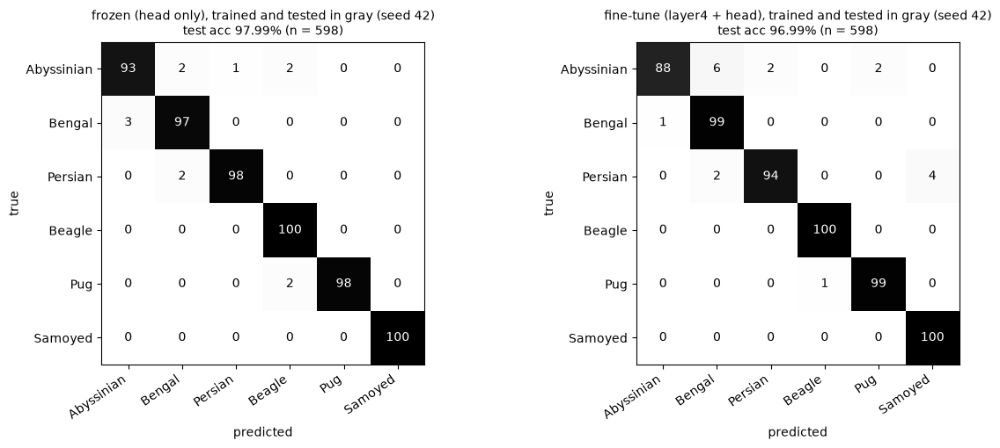

In [29]:
pc = []
for k, b in enumerate(BREEDS):
    sel = y_t == k
    r = {"breed": b, "n": int(sel.sum())}
    for c in CONDS:
        r[f"{c}: color"] = 100 * OK(SEED, "color", c, "color")[sel].mean()
        r[f"{c}: gray"] = 100 * OK(SEED, "gray", c, "gray")[sel].mean()
        r[f"{c}: change"] = r[f"{c}: gray"] - r[f"{c}: color"]
        r[f"{c}: color model, gray test"] = 100 * OK(SEED, "color", c, "gray")[sel].mean()
    pc.append(r)
pc = pd.DataFrame(pc).set_index("breed")
pc.to_csv(EXT / "per_breed_recall_seed42.csv")
print(f"test recall per breed (%), seed {SEED}")
display(pc.round(1))

for c in CONDS:
    pred_g = PR(SEED, "gray", c, "gray").argmax(1)
    e = pd.DataFrame(dict(true=[BREEDS[i] for i in y_t], pred=[BREEDS[i] for i in pred_g]))
    e = e[e.true != e.pred]
    lost = OK(SEED, "color", c, "color") & ~OK(SEED, "gray", c, "gray")
    gained = ~OK(SEED, "color", c, "color") & OK(SEED, "gray", c, "gray")
    print(f"\n{lab_e[c]}, trained and tested in gray: {len(e)} errors; {int(lost.sum())} images right in color but wrong "
          f"in gray, {int(gained.sum())} the other way round")
    if len(e):
        print(e.groupby(["true", "pred"]).size().rename("n").to_string())

fig, ax = plt.subplots(1, 2, figsize=(12.5, 5.2))
for a_, c in zip(ax, CONDS):
    cm = confusion_matrix(y_t, PR(SEED, "gray", c, "gray").argmax(1), labels=list(range(KB)))
    a_.imshow(cm, cmap="Greys")
    for i in range(KB):
        for j in range(KB):
            a_.text(j, i, cm[i, j], ha="center", va="center", fontsize=10, color="white" if cm[i, j] > cm.max() / 2 else "black")
    a_.set_xticks(range(KB)); a_.set_xticklabels(BREEDS, rotation=35, ha="right")
    a_.set_yticks(range(KB)); a_.set_yticklabels(BREEDS)
    a_.set_xlabel("predicted"); a_.set_ylabel("true")
    a_.set_title(f"{lab_e[c]}, trained and tested in gray (seed {SEED})\n"
                 f"test acc {100 * OK(SEED, 'gray', c, 'gray').mean():.2f}% (n = {n_t})", fontsize=10)
fig.tight_layout()
fig.savefig(FIG / "figE3_confusion_gray.png", dpi=150)
plt.show()

Without color the dogs stay where they were: Beagle and Samoyed are perfect in both versions, and Pug loses at most one photo. The changes are in the cats, as my first expectation said, but not all in one direction. For the frozen model, Bengal even improves (94 → 97%). For the fine-tuned model, Persian falls from 99 to 94%.

The black-and-white models' mistakes show where the losses go. The frozen model's 12 errors include two Abyssinians and two Pugs called Beagle; compared with its color version, it loses 5 photos and gains 7. The fine-tuned model's 18 errors include four Persians called Samoyed and two Abyssinians called Pug, and it loses 8 photos while gaining 1. Persian_77 below, a white Persian, is one of the four called Samoyed.

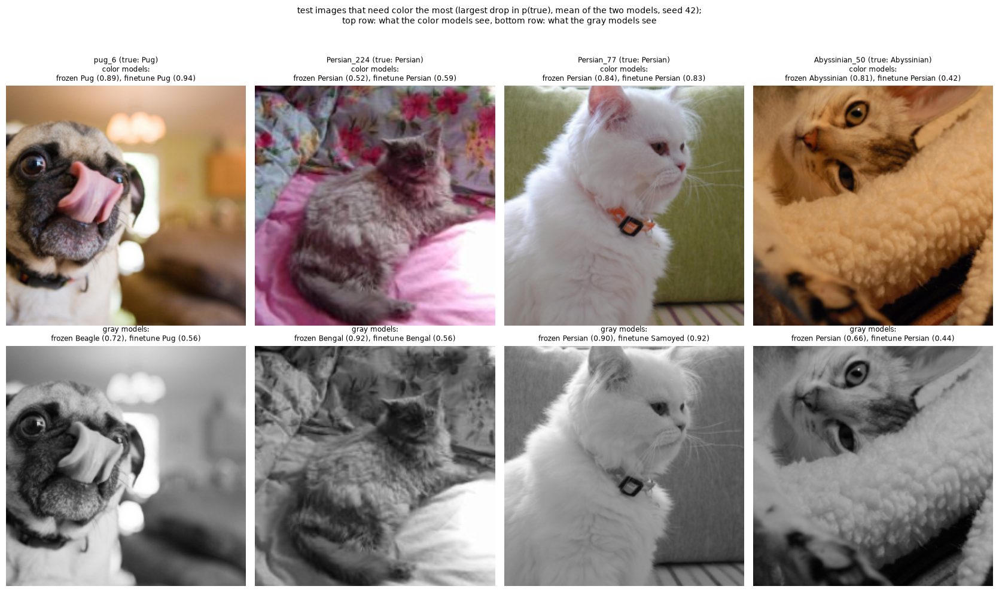

,image_id,true,drop_in_p_true
0,pug_6,Pug,0.5453
1,Persian_224,Persian,0.3940
2,Persian_77,Persian,0.3411
3,Abyssinian_50,Abyssinian,0.2988


In [30]:
ar = np.arange(n_t)
drop = np.mean([PR(SEED, "color", c, "color")[ar, y_t] - PR(SEED, "gray", c, "gray")[ar, y_t] for c in CONDS], axis=0)
top = np.argsort(-drop, kind="stable")[:4]
to_img = lambda x: (x * st + mt).clamp(0, 1).permute(1, 2, 0).numpy()
fig, ax = plt.subplots(2, len(top), figsize=(4.2 * len(top), 10.2), squeeze=False)
for j, i in enumerate(top):
    for row, md in enumerate(MODES):
        ax[row, j].imshow(to_img(DS["test", md][i][0]))
        ax[row, j].axis("off")
        guess = ", ".join(f"{c} {BREEDS[PR(SEED, md, c, md)[i].argmax()]} ({PR(SEED, md, c, md)[i].max():.2f})" for c in CONDS)
        head = f"{req_pred.image_id[i]} (true: {BREEDS[y_t[i]]})\n" if row == 0 else ""
        ax[row, j].set_title(f"{head}{md} models: {guess}".replace(": ", ":\n", 1) if row else f"{head}{md} models:\n{guess}", fontsize=8.5)
fig.suptitle(f"test images that need color the most (largest drop in p(true), mean of the two models, seed {SEED});\n"
             "top row: what the color models see, bottom row: what the gray models see", fontsize=10)
fig.tight_layout(rect=(0, 0, 1, 0.94), h_pad=3.0)
fig.savefig(FIG / "figE4_color_dependent_images.png", dpi=130)
plt.show()
pd.DataFrame(dict(image_id=req_pred.image_id.values[top], true=[BREEDS[y_t[i]] for i in top], drop_in_p_true=drop[top].round(4)))

These four photos lost the most confidence in the true breed when color was taken away, averaged over the two models of seed 42.

**pug_6.** In color, a fawn Pug with a black mask is clearly a Pug (0.89 and 0.94). In black and white, the frozen model calls it a Beagle (0.72), and the fine-tuned model only just keeps Pug (0.56).

**Persian_224.** A smoke-colored, long-haired Persian on a pink floral blanket. Both black-and-white models call it a Bengal (0.92 and 0.56); in black and white its striped gray coat may look like a Bengal's pattern.

**Persian_77.** A white Persian on a green sofa. The black-and-white frozen model still says Persian, but the fine-tuned one says Samoyed with 0.92, the same white-cat-to-white-dog confusion as above.

**Abyssinian_50.** A ruddy Abyssinian face pressed into a cream sherpa blanket. Both black-and-white models say Persian (0.66 and 0.44). Here the fine-tuned color model was already wrong (Persian 0.42), so the photo is hard in either version.

### Results over five seeds
One seed can mislead, so the same quantities are computed for seeds 42, 1, 2, 3 and 4. The table shows each seed, the mean and the standard deviation; the intervals for the means resample both the seeds and the test photos.

,color-trained frozen (%),color-trained finetune (%),gray-trained frozen (%),gray-trained finetune (%),frozen: gray - color (pp),fine-tune: gray - color (pp),"fine-tune - frozen, color (pp)","fine-tune - frozen, gray (pp)",difference in differences (pp)
42,97.66,98.16,97.99,96.99,0.33,-1.17,0.50,-1.00,-1.51
1,96.66,97.66,97.99,95.82,1.34,-1.84,1.00,-2.17,-3.18
2,96.49,95.82,97.99,96.49,1.51,0.67,-0.67,-1.51,-0.84
3,97.16,96.99,97.49,97.99,0.33,1.00,-0.17,0.50,0.67
4,97.32,97.49,97.66,98.16,0.33,0.67,0.17,0.50,0.33
mean,97.06,97.22,97.83,97.09,0.77,-0.13,0.17,-0.74,-0.90
SD,0.48,0.89,0.24,0.99,0.60,1.28,0.64,1.20,1.54


95% intervals for the means over seeds (bootstrap over seeds and test images):
  frozen: gray - color (pp): mean +0.77, [-0.37, +1.97]
  fine-tune: gray - color (pp): mean -0.13, [-1.47, +1.14]
  fine-tune - frozen, color (pp): mean +0.17, [-0.94, +1.27]
  fine-tune - frozen, gray (pp): mean -0.74, [-2.21, +0.64]
  difference in differences (pp): mean -0.90, [-2.71, +0.74]


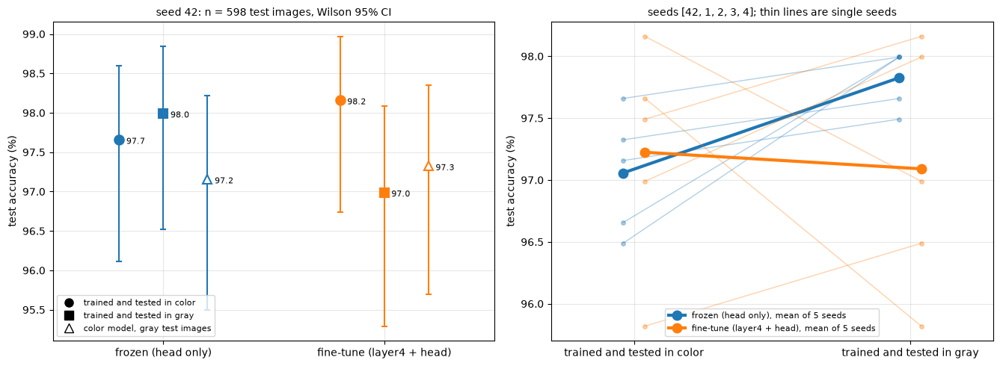

In [31]:
from matplotlib.lines import Line2D
cells4 = [("color", "frozen"), ("color", "finetune"), ("gray", "frozen"), ("gray", "finetune")]
OKS = np.stack([np.stack([OK(s, md, c, md) for md, c in cells4]) for s in SEEDS]).astype(float)   # seeds x 4 x images

def derived(acc):
    return {"frozen: gray - color": acc[..., 2] - acc[..., 0], "fine-tune: gray - color": acc[..., 3] - acc[..., 1],
            "fine-tune - frozen, color": acc[..., 1] - acc[..., 0], "fine-tune - frozen, gray": acc[..., 3] - acc[..., 2],
            "difference in differences": (acc[..., 3] - acc[..., 2]) - (acc[..., 1] - acc[..., 0])}

acc_s = OKS.mean(2)
seed_tab = pd.DataFrame({"seed": SEEDS, **{f"{md}-trained {c} (%)": 100 * acc_s[:, j] for j, (md, c) in enumerate(cells4)},
                         **{f"{k} (pp)": 100 * v for k, v in derived(acc_s).items()}}).set_index("seed")
rng_h = np.random.default_rng(SEED + 1)
S_ = len(SEEDS)
hb = {k: np.empty(B_EXT) for k in derived(acc_s)}
for b in range(B_EXT):
    si, ii = rng_h.integers(0, S_, S_), rng_h.integers(0, n_t, n_t)
    for k, v in derived(OKS[si][:, :, ii].mean(2)).items():
        hb[k][b] = v.mean()
ci = {f"{k} (pp)": [100 * np.percentile(v, 2.5), 100 * np.percentile(v, 97.5)] for k, v in hb.items()}
seed_tab.to_csv(EXT / "seeds.csv")
dump(dict(per_seed=seed_tab.reset_index().to_dict("records"), mean=seed_tab.mean().to_dict(), sd=seed_tab.std().to_dict(),
          ci95_over_seeds_and_images=ci), EXT / "seeds_summary.json")
display(pd.concat([seed_tab, pd.DataFrame({"mean": seed_tab.mean(), "SD": seed_tab.std()}).T]).round(2))
print("95% intervals for the means over seeds (bootstrap over seeds and test images):")
for k, v in ci.items():
    print(f"  {k}: mean {seed_tab[k].mean():+.2f}, [{v[0]:+.2f}, {v[1]:+.2f}]")

fig, ax = plt.subplots(1, 2, figsize=(13.5, 5))
pts = [("trained and tested in color", "color", "color", "o", True, -0.2), ("trained and tested in gray", "gray", "gray", "s", True, 0.0),
       ("color model, gray test images", "color", "gray", "^", False, 0.2)]
for xi, c in enumerate(CONDS):
    for name, md, tv, mk, filled, dx in pts:
        k = int(OK(SEED, md, c, tv).sum())
        lo, hi = wilson_ci(k, n_t)
        a = 100 * k / n_t
        ax[0].errorbar(xi + dx, a, yerr=[[max(a - 100 * lo, 0)], [max(100 * hi - a, 0)]], fmt=mk, ms=9, color=col_e[c],
                       mfc=col_e[c] if filled else "white", mew=1.5, capsize=3)
        ax[0].annotate(f"{a:.1f}", (xi + dx, a), textcoords="offset points", xytext=(7, -4), fontsize=8)
ax[0].legend(handles=[Line2D([], [], marker=mk, ls="", color="k", mfc="k" if filled else "white", ms=8, label=name)
                      for name, md, tv, mk, filled, dx in pts], fontsize=8, loc="lower left")
ax[0].set_xticks(range(len(CONDS))); ax[0].set_xticklabels([lab_e[c] for c in CONDS]); ax[0].set_xlim(-0.5, len(CONDS) - 0.5)
ax[0].set_ylabel("test accuracy (%)"); ax[0].grid(alpha=0.3)
ax[0].set_title(f"seed {SEED}: n = {n_t} test images, Wilson 95% CI", fontsize=10)
for c, dx in zip(CONDS, (-0.04, 0.04)):
    for s in SEEDS:
        ax[1].plot([dx, 1 + dx], [100 * OK(s, md, c, md).mean() for md in MODES], "-o", color=col_e[c], alpha=0.35, lw=1, ms=4)
    ax[1].plot([dx, 1 + dx], [100 * np.mean([OK(s, md, c, md).mean() for s in SEEDS]) for md in MODES], "-o", color=col_e[c],
               lw=3, ms=9, label=f"{lab_e[c]}, mean of {len(SEEDS)} seeds")
ax[1].set_xticks([0, 1]); ax[1].set_xticklabels(["trained and tested in color", "trained and tested in gray"])
ax[1].set_xlim(-0.3, 1.3); ax[1].set_ylabel("test accuracy (%)"); ax[1].grid(alpha=0.3); ax[1].legend(fontsize=8)
ax[1].set_title(f"seeds {SEEDS}; thin lines are single seeds", fontsize=10)
fig.tight_layout()
fig.savefig(FIG / "figE1_color_vs_gray.png", dpi=150)
plt.show()

**The seed-42 drop does not replicate.** The fine-tuned model lost 1.17 points without color at seed 42, which looked significant on its own. Over five seeds its change ranges from −1.84 to +1.00 points, with two seeds losing and three gaining, and the mean is −0.13 (interval −1.47 to +1.14). The frozen model is at least as accurate in black and white in all five seeds (+0.33 to +1.51 points), with a mean of +0.77 (interval −0.37 to +1.97). So with 80 photos per breed, neither model loses measurable accuracy without color. This is also a lesson about one seed: a single run can produce a convincing-looking p value that the other seeds do not confirm on average.

**Part 1's question over five seeds.** In color, fine-tuning beats the frozen head by 0.17 points on average (interval −0.94 to +1.27), which agrees with Part 1's single-seed answer. Seed 42 happened to give the best frozen model of the five (97.66%, against 96.49–97.32% for the others). In black and white, fine-tuning is 0.74 points worse on average (interval −2.21 to +0.64). The difference in differences, −0.90 (interval −2.71 to +0.74), points against my third expectation but is not conclusive.

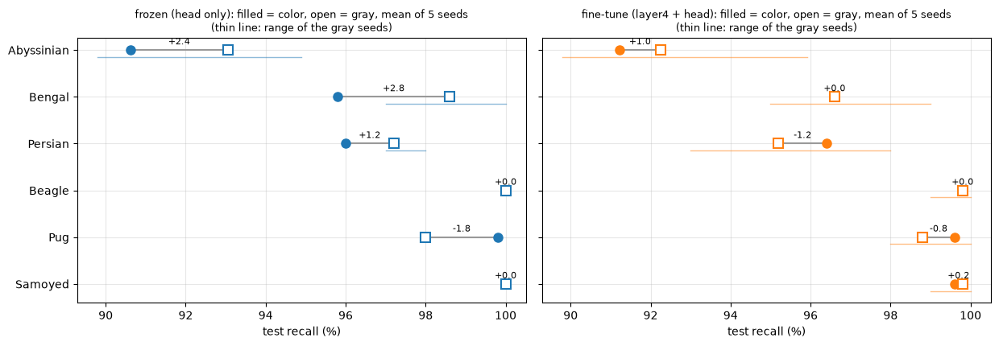

,frozen: color,frozen: gray,finetune: color,finetune: gray,frozen: change,finetune: change
breed,,,,,,
Abyssinian,90.6,93.1,91.2,92.2,2.4,1.0
Bengal,95.8,98.6,96.6,96.6,2.8,0.0
Persian,96.0,97.2,96.4,95.2,1.2,-1.2
Beagle,100.0,100.0,99.8,99.8,0.0,0.0
Pug,99.8,98.0,99.6,98.8,-1.8,-0.8
Samoyed,100.0,100.0,99.6,99.8,0.0,0.2


In [32]:
rec = {(c, md): np.array([[OK(s, md, c, md)[y_t == k].mean() for k in range(KB)] for s in SEEDS]) for c in CONDS for md in MODES}
pcs = pd.DataFrame({f"{c}: {md}": 100 * rec[c, md].mean(0) for c in CONDS for md in MODES}, index=BREEDS)
for c in CONDS:
    pcs[f"{c}: change"] = pcs[f"{c}: gray"] - pcs[f"{c}: color"]
pcs.index.name = "breed"
pcs.to_csv(EXT / "per_breed_recall_mean_over_seeds.csv")
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.4), sharey=True, sharex=True)
for a_, c in zip(ax, CONDS):
    for k, b in enumerate(BREEDS):
        mc, mg = pcs.loc[b, f"{c}: color"], pcs.loc[b, f"{c}: gray"]
        a_.plot([100 * rec[c, "gray"][:, k].min(), 100 * rec[c, "gray"][:, k].max()], [k + 0.15] * 2, "-", color=col_e[c], alpha=0.5, lw=1)
        a_.plot([mc, mg], [k, k], "-", color="0.6", lw=1.5)
        a_.plot(mc, k, "o", color=col_e[c], ms=8)
        a_.plot(mg, k, "s", color=col_e[c], mfc="white", mew=1.5, ms=8)
        a_.annotate(f"{mg - mc:+.1f}", ((mc + mg) / 2, k), textcoords="offset points", xytext=(0, 5), ha="center", fontsize=8)
    a_.set_yticks(range(KB)); a_.set_yticklabels(BREEDS); a_.set_xlabel("test recall (%)"); a_.grid(alpha=0.3)
    a_.set_title(f"{lab_e[c]}: filled = color, open = gray, mean of {len(SEEDS)} seeds\n(thin line: range of the gray seeds)", fontsize=9)
ax[0].invert_yaxis()
fig.tight_layout()
fig.savefig(FIG / "figE2_per_breed_recall.png", dpi=150)
plt.show()
pcs.round(1)

Averaged over the five seeds, the breeds that move are the cats and the Pug; Beagle and Samoyed stay at about 100% in every version. For the frozen model, Abyssinian, Bengal and Persian even improve without color (+2.4, +2.8 and +1.2 points), while Pug loses 1.8. For the fine-tuned model, the changes are within about one point either way.

## Part 2b. Fewer photos, and changing only the color

Part 2a shows that with 80 photos per breed the models do not *need* color. That does not show that they don't *use* it. In synthetic datasets, Hermann and Lampinen (2020) found that when several features predict the label, networks prefer the one that is easiest to read out, and color was easier than shape or texture; an easy feature can even push aside a harder one that predicts better. So a color model may lean on color without needing it, and how much it needs color may depend on how many photos it learns from. Part 2b asks both questions, and it holds everything else fixed.

**Fewer photos per breed.** I repeat Part 2a with 1, 5 and 20 training photos per breed instead of 80, in color and in black and white, for the same five seeds and both model types: 30 new training pairs. The assignment lists changing the training set size as an extension and asks for a fixed subset per breed with the validation and test sets intact, which is what this does. Each seed draws its own order of the photos within each breed and takes the first k, so the subsets are nested (1 ⊂ 5 ⊂ 20 ⊂ 80), and at 80 they are the full split, so the models of Part 2a serve as the 80-photo point. Everything else is Part 1's protocol, unchanged: warm-up, the two models in lockstep, the epoch rule, selection on all 120 validation photos.

**Changing only the color.** A color model's use of color can be measured directly, by changing a photo's colors while keeping its brightness exactly as it was. I convert each test photo to YCbCr, rotate its two color channels around the color wheel, and convert back. The ITU-R 601 brightness Y = 0.299 R + 0.587 G + 0.114 B, which is what `transforms.Grayscale` keeps, stays unchanged except in the few pixels that have to be clipped, so the black-and-white version of the photo is the same image. A black-and-white model therefore cannot notice the change, and serves as a built-in control. The trimaps that come with Oxford-IIIT Pet let me change the colors of the pet alone (with its border), of the background alone, or of the whole photo. A 180° rotation gives every color its opposite, so a fawn Pug turns blue-gray, while a white Samoyed, which has almost no color to rotate, stays almost as it was. A rotation of ±30° is closer to what a camera's wrong white balance does, so it shows what a realistic color error costs. Lowering the saturation to 0 gives the black-and-white photo again, which separates a *wrong* color from a *missing* one.

**Main and secondary comparisons.** Each question has one main comparison, fixed in the lock. For the first, it is the black-and-white model on black-and-white photos against the color model of the same seed on color photos, at each training size. For the second, it is the color models on photos with the pet's colors rotated by 180°, against the same photos unchanged. Everything else is a reference or descriptive: the background and the whole photo, the ±30° and ±90° rotations, the saturation levels, the breeds and the confusions. Every interval is a 95% interval for its own comparison and is not corrected for the number of comparisons, so I read the pattern across training sizes and model types, and not a single interval that happens to exclude zero.

The black-and-white photos of Part 2a were made by PIL's own conversion; the photos here are rounded back to 8 bits after the change, so "saturation 0%" reproduces Part 2a's black-and-white test photos only up to rounding.

### What I expect
These expectations, like the plan, go into a new lock file before any model of Part 2b is scored on a test photo and before any recolored photo is shown to any model:
1. With fewer photos per breed, learning without color costs more: the black-and-white models fall further behind the color models at 1 photo per breed than at 80, where Part 2a found no measurable cost.
2. The color models use color even where they don't need it: rotating the pet's colors by 180° lowers their accuracy at every training size, and more with fewer photos.
3. It is the pet's color that matters, not the background's: rotating the pet's colors costs more than rotating the background's.
4. The cost falls on the breeds whose coat color is diagnostic, Abyssinian, Bengal and Pug, and is close to zero for the Samoyed, whose white coat has almost no color to rotate.
5. Least certain: for a color model, a wrong color costs more than no color at all (whole photo rotated by 180° against saturation 0%).

In [33]:
import math
from collections import Counter
PB_SIZES = [1, 5, 20]                       # photos per breed; 80, the full split, is Part 2a
PB_DIR, PB_CK = RES / "ext_size", CKPT / "ext_size"
for _d in (PB_DIR / "runs", PB_DIR / "test", PB_CK):
    _d.mkdir(parents=True, exist_ok=True)
PB_YTR = np.array(cache["train"][1])        # labels of the cached training photos, in Part 1's order
PB_POS = {b: np.flatnonzero(PB_YTR == b) for b in range(len(BREEDS))}
assert all(len(v) >= max(PB_SIZES) for v in PB_POS.values())


def pb_subset(k, seed):
    """positions of the first k training photos of each breed, in an order fixed by the seed; nested across k"""
    rng = np.random.default_rng([seed, 2026])
    return sorted(int(j) for b in range(len(BREEDS)) for j in rng.permutation(PB_POS[b])[:k])


assert all(set(pb_subset(a, s)) <= set(pb_subset(b, s)) for s in SEEDS for a, b in zip(PB_SIZES, PB_SIZES[1:]))
assert all(pb_subset(80, s) == list(range(len(PB_YTR))) for s in SEEDS) or len(PB_YTR) != 80 * len(BREEDS)


def pb_ckpt(k, seed, mode, c):
    return PB_CK / f"k{k}_s{seed}_{mode}_{c}.pt"


def pb_load(k, seed, mode, c):
    """the ImageNet ResNet18 with the trained part of a Part 2b model: the head, and layer4 for the fine-tuned one"""
    m = build_seed(seed)
    sd = torch.load(pb_ckpt(k, seed, mode, c), map_location="cpu")
    assert all(q.startswith("fc.") or (c == "finetune" and q.startswith("layer4.")) for q in sd)
    _, unexpected = m.load_state_dict(sd, strict=False)
    assert not unexpected
    return setup(m, c).to(device).eval()


def pb_train(k, seed, mode):
    """Part 1's protocol on k photos per breed (warm-up, lockstep, epoch rule, selection), as train_pair above"""
    rd = PB_DIR / "runs" / f"k{k}_s{seed}_{mode}"
    rd.mkdir(parents=True, exist_ok=True)
    if (rd / "summary.json").exists():
        s = json.loads((rd / "summary.json").read_text(encoding="utf-8"))
        if all(pb_ckpt(k, seed, mode, c).exists() and sha(pb_ckpt(k, seed, mode, c)) == s["cond"][c]["sha256"] for c in CONDS):
            return dict(s, reloaded=True)
    sub = pb_subset(k, seed)
    tr_ds, va_ds = Subset(DS["train", mode], sub), DS["val", mode]
    labs = LabelsOnly([int(PB_YTR[j]) for j in sub])
    lh = lambda e: stream_hash(labs, seed, e, images=False)
    warm_device()
    t_start = time.perf_counter()
    m = setup(build_seed(seed), "warmup").to(device)
    opt = make_opt(m, "warmup")
    w_tr = []
    for e in range(WARMUP_EPOCHS):
        w_tr.append(ext_epoch(m, opt, -e, tr_ds, seed))
        assert w_tr[-1]["labels_hash"] == lh(-e)
    w_val = evaluate(m, va_ds)
    w_state = {q: v.detach().cpu().clone() for q, v in m.state_dict().items()}
    runs = {}
    for c in CONDS:
        m = build_seed(seed)
        m.load_state_dict(w_state)
        m = setup(m, c).to(device)
        s0 = evaluate(m, va_ds)
        if abs(s0["loss"] - w_val["loss"]) > 1e-2:
            raise RuntimeError(f"{c}: reloaded warm-up gives {s0['correct']} / {s0['loss']:.5f}")
        runs[c] = dict(m=m, opt=make_opt(m, c), hist=[], best=None, best_state=None, plateau=None)
    stop = None
    with open(rd / "train_log.txt", "w") as log:
        for ep in range(1, MAX_EPOCHS + 1):
            want = lh(ep)
            for c, R in runs.items():
                tr = ext_epoch(R["m"], R["opt"], ep, tr_ds, seed)
                assert tr["labels_hash"] == want
                va = evaluate(R["m"], va_ds)
                rec = dict(condition=c, epoch=ep, **tr, val_loss=va["loss"], val_acc=va["acc"], val_correct=va["correct"],
                           val_n=va["n"], val_macro_f1=va["macro_f1"])
                R["hist"].append(rec)
                if better(rec, R["best"]):
                    R["best"] = rec
                    R["best_state"] = {q: v.detach().cpu().clone() for q, v in R["m"].state_dict().items()}
                if R["plateau"] is None and ep >= MIN_EPOCHS and since_best(R["hist"]) >= PATIENCE:
                    R["plateau"] = ep
                log.write(f"{c:8s} ep {ep:3d} | train loss {tr['train_loss']:.4f} | val {va['correct']}/{va['n']} "
                          f"loss {va['loss']:.4f} | {tr['batches_hash']}\n")
            if all(R["plateau"] for R in runs.values()):
                stop = ep
                break
    stop = stop or MAX_EPOCHS
    assert [r["batches_hash"] for r in runs["frozen"]["hist"]] == [r["batches_hash"] for r in runs["finetune"]["hist"]]
    summary = dict(k=k, seed=seed, mode=mode, E=stop, plateau={c: R["plateau"] for c, R in runs.items()},
                   photos=[Path(base_dev._images[idx["train"][j]]).stem for j in sub],
                   warmup=dict(val_correct=w_val["correct"], val_loss=w_val["loss"]), minutes=(time.perf_counter() - t_start) / 60, cond={})
    for c, R in runs.items():
        sd = R["best_state"]
        changed = [q for q in sd if not torch.equal(sd[q], w_state[q])]
        assert not [q for q in changed if not q.startswith("fc.") and not (c == "finetune" and q.startswith("layer4."))]
        torch.save({q: v for q, v in sd.items() if q.startswith("fc.") or (c == "finetune" and q.startswith("layer4."))},
                   pb_ckpt(k, seed, mode, c))
        b = R["best"]
        summary["cond"][c] = dict(selected_epoch=b["epoch"], val_correct=b["val_correct"], val_loss=b["val_loss"],
                                  val_macro_f1=b["val_macro_f1"], sha256=sha(pb_ckpt(k, seed, mode, c)))
    pd.DataFrame([r for R in runs.values() for r in R["hist"]]).to_csv(rd / "history.csv", index=False)
    dump(summary, rd / "summary.json")
    del runs, w_state, m
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return summary


def pb_train_all():
    out, t0 = {}, time.perf_counter()
    for k in PB_SIZES:
        for s in SEEDS:
            for md in MODES:
                out[k, s, md] = pb_train(k, s, md)
                r = out[k, s, md]
                print(f"k = {k:2d}, seed {s:2d}, {md:5s}: E = {r['E']:3d}, selected "
                      + ", ".join(f"{c} epoch {r['cond'][c]['selected_epoch']} ({r['cond'][c]['val_correct']}/120)" for c in CONDS)
                      + f"  [trained in {60 * r['minutes']:.0f}s{', reloaded' if r.get('reloaded') else ''}]")
    print(f"\n{len(out)} pairs, {sum(r['minutes'] for r in out.values()):.1f} min of training in total; this cell took "
          f"{(time.perf_counter() - t0) / 60:.1f} min (pairs trained earlier are reloaded after their hashes are checked)")
    return out


PB_SUMM = pb_train_all()
pb_val = pd.DataFrame([dict(photos_per_breed=k, seed=s, trained_on=md, model=c, epochs=PB_SUMM[k, s, md]["E"],
                            selected_epoch=PB_SUMM[k, s, md]["cond"][c]["selected_epoch"],
                            val_correct=PB_SUMM[k, s, md]["cond"][c]["val_correct"])
                       for k in PB_SIZES for s in SEEDS for md in MODES for c in CONDS])
pb_val.to_csv(PB_DIR / "validation_summary.csv", index=False)
pb_val.pivot_table(index="photos_per_breed", columns=["trained_on", "model"], values="val_correct", aggfunc="mean").round(1)

k =  1, seed 42, color: E = 100, selected frozen epoch 18 (103/120), finetune epoch 70 (94/120)  [trained in 32s, reloaded]
k =  1, seed 42, gray : E = 102, selected frozen epoch 102 (97/120), finetune epoch 11 (93/120)  [trained in 40s, reloaded]
k =  1, seed  1, color: E = 100, selected frozen epoch 91 (107/120), finetune epoch 11 (102/120)  [trained in 33s, reloaded]
k =  1, seed  1, gray : E = 100, selected frozen epoch 100 (104/120), finetune epoch 19 (90/120)  [trained in 39s, reloaded]
k =  1, seed  2, color: E = 100, selected frozen epoch 90 (106/120), finetune epoch 6 (99/120)  [trained in 34s, reloaded]
k =  1, seed  2, gray : E = 100, selected frozen epoch 91 (99/120), finetune epoch 5 (97/120)  [trained in 41s, reloaded]
k =  1, seed  3, color: E = 100, selected frozen epoch 33 (96/120), finetune epoch 95 (83/120)  [trained in 34s, reloaded]
k =  1, seed  3, gray : E = 100, selected frozen epoch 100 (98/120), finetune epoch 100 (87/120)  [trained in 42s, reloaded]
k =  1, s

trained_on          color            gray       
model            finetune frozen finetune frozen
photos_per_breed                                
1                    93.0  101.2     90.6   98.4
5                   109.2  112.0    106.4  111.2
20                  116.8  117.0    112.6  115.6

All 30 pairs were trained on November 18, 27.5 minutes of training in all, before the lock below was written, and are reloaded here after their hashes are checked. Even one photo per breed goes a long way on validation: the frozen color models get 101 of the 120 validation photos right on average, and the fine-tuned ones 93. With 5 photos the averages rise to 112 and 109, and with 20 to 117 for both, against 117–119 with all 80. At every size the frozen model is ahead of or level with the fine-tuned one, and the black-and-white models are a little behind the color models of their kind.

The next cell prepares the color changes. It rebuilds the 598 test photos exactly as the test pipeline crops them and checks that they give the same tensors, then defines the change and measures how well it keeps the brightness: the share of changed pixels whose 8-bit brightness moves at all, and how many had to be clipped.

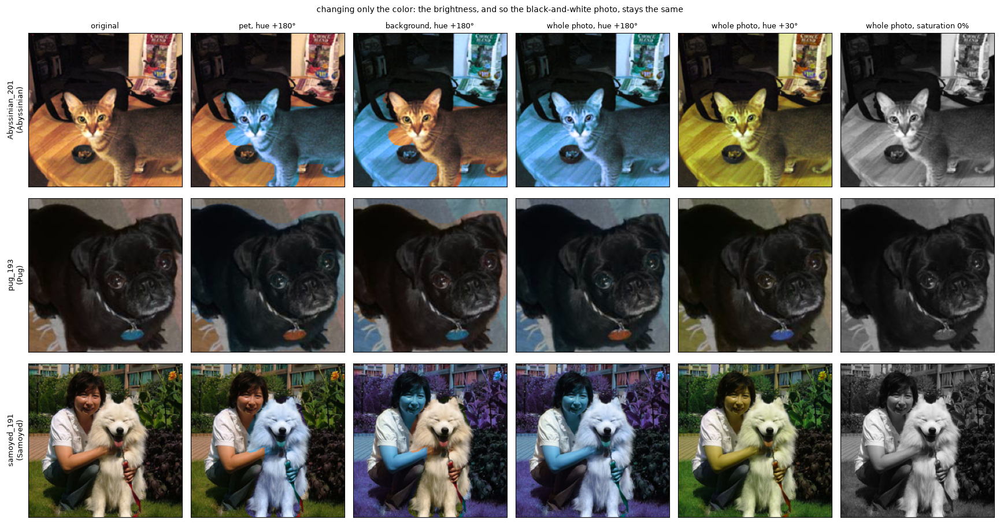

,pixels in the region (%),region pixels whose color changed (%),region pixels whose brightness moved by more than 1 of 255 (%)
change,,,
"pet, hue +180°",60.96,98.444,1.583
"background, hue +180°",39.04,96.209,3.844
"whole photo, hue +180°",100.00,97.571,2.466
"whole photo, hue +90°",100.00,97.571,1.539
"whole photo, hue −90°",100.00,97.571,1.181
"whole photo, hue +30°",100.00,96.273,1.619
"whole photo, hue −30°",100.00,96.248,1.384
"whole photo, saturation 50%",100.00,96.276,0.000
"whole photo, saturation 0%",100.00,97.571,0.000


In [34]:
def pb_load_test():
    rs, cc = transforms.Resize(256), transforms.CenterCrop(224)
    rs_nn = transforms.Resize(256, interpolation=transforms.InterpolationMode.NEAREST)
    rgb, tri = [], []
    for j in idx["test"]:
        stem = Path(base_test._images[j]).stem
        with Image.open(base_test._images[j]) as f:
            rgb.append(torch.from_numpy(np.array(cc(rs(f.convert("RGB"))), dtype=np.uint8)).permute(2, 0, 1))
        with Image.open(Path(base_test._anns_folder) / "trimaps" / f"{stem}.png") as f:
            tri.append(np.array(cc(rs_nn(f)), dtype=np.uint8))
    return torch.stack(rgb), np.stack(tri)


PB_RGB, PB_TRI = pb_load_test()
PB_Y = req_probs["y"]
assert set(np.unique(PB_TRI)) <= {1, 2, 3}
_m, _s = torch.tensor(mean).view(1, 3, 1, 1), torch.tensor(std).view(1, 3, 1, 1)
for _pos in (0, len(PB_Y) // 2, len(PB_Y) - 1):
    assert torch.equal(((PB_RGB[_pos:_pos + 1].float().div(255) - _m) / _s)[0], DS["test", "color"][_pos][0]), _pos
PB_M, PB_S = _m.to(device), _s.to(device)
PB_REGION = {"pet": torch.from_numpy(PB_TRI != 2)[:, None].float(),             # the pet and its border
             "background": torch.from_numpy(PB_TRI == 2)[:, None].float(),
             "whole photo": torch.ones(len(PB_Y), 1, 224, 224)}
PB_CONDS = {"pet, hue +180°": ("pet", 180, 1.0), "background, hue +180°": ("background", 180, 1.0),
            "whole photo, hue +180°": ("whole photo", 180, 1.0), "whole photo, hue +90°": ("whole photo", 90, 1.0),
            "whole photo, hue −90°": ("whole photo", -90, 1.0), "whole photo, hue +30°": ("whole photo", 30, 1.0),
            "whole photo, hue −30°": ("whole photo", -30, 1.0), "whole photo, saturation 50%": ("whole photo", 0, 0.5),
            "whole photo, saturation 0%": ("whole photo", 0, 0.0)}
PB_LUMA = lambda x: 0.299 * x[:, 0:1] + 0.587 * x[:, 1:2] + 0.114 * x[:, 2:3]


def pb_recolor(u8, sl, cond):
    """uint8 photos -> the same photos with their chroma rotated and scaled inside a region, brightness kept, rounded to 8 bits"""
    region, angle, sat = PB_CONDS[cond]
    x = u8.to(device).float().div(255)
    Y = PB_LUMA(x)
    cb, cr = (x[:, 2:3] - Y) / 1.772, (x[:, 0:1] - Y) / 1.402
    t = math.radians(angle)
    cb2, cr2 = sat * (math.cos(t) * cb - math.sin(t) * cr), sat * (math.sin(t) * cb + math.cos(t) * cr)
    r2, b2 = Y + 1.402 * cr2, Y + 1.772 * cb2
    g2 = (Y - 0.299 * r2 - 0.114 * b2) / 0.587
    w = PB_REGION[region][sl].to(device)
    out = w * torch.cat([r2, g2, b2], 1) + (1 - w) * x
    return (out.clamp(0, 1) * 255).round().div(255)


def pb_slices(n):
    return [slice(a, min(a + EVAL_BATCH, n)) for a in range(0, n, EVAL_BATCH)]


def pb_check_luma():
    rows = []
    with torch.no_grad():
        for cond, (region, _, _) in PB_CONDS.items():
            moved = changed = clipped = inside = 0
            for sl in pb_slices(len(PB_Y)):
                x = PB_RGB[sl].to(device).float().div(255)
                y8 = pb_recolor(PB_RGB[sl], sl, cond)
                w = PB_REGION[region][sl].to(device)
                dY = (PB_LUMA(y8) - PB_LUMA(x)).abs() * 255
                moved += int(((dY > 1.0) * w).sum())
                changed += int((((y8 - x).abs().amax(1, keepdim=True) > 0.5 / 255) * w).sum())
                inside += int(w.sum())
            rows.append({"change": cond, "pixels in the region (%)": 100 * inside / (len(PB_Y) * 224 * 224),
                         "region pixels whose color changed (%)": 100 * changed / max(inside, 1),
                         "region pixels whose brightness moved by more than 1 of 255 (%)": 100 * moved / max(inside, 1)})
    return pd.DataFrame(rows).set_index("change")


def pb_fig_examples():
    show = [int(np.flatnonzero(PB_Y == BREEDS.index(b))[0]) for b in ("Abyssinian", "Pug", "Samoyed") if b in BREEDS]
    cols = ["original", "pet, hue +180°", "background, hue +180°", "whole photo, hue +180°", "whole photo, hue +30°",
            "whole photo, saturation 0%"]
    fig, ax = plt.subplots(len(show), len(cols), figsize=(2.9 * len(cols), 3.1 * len(show)), squeeze=False)
    for r, i in enumerate(show):
        for c_, cond in enumerate(cols):
            img = PB_RGB[i:i + 1].float().div(255) if cond == "original" else pb_recolor(PB_RGB[i:i + 1], slice(i, i + 1), cond).cpu()
            ax[r, c_].imshow(img[0].permute(1, 2, 0).numpy())
            ax[r, c_].set_xticks([]); ax[r, c_].set_yticks([])
            if r == 0:
                ax[r, c_].set_title(cond, fontsize=9)
        ax[r, 0].set_ylabel(f"{req_pred.image_id[i]}\n({BREEDS[PB_Y[i]]})", fontsize=9)
    fig.suptitle("changing only the color: the brightness, and so the black-and-white photo, stays the same", fontsize=10)
    fig.tight_layout()
    fig.savefig(FIG / "figE11_recolored_examples.png", dpi=130)
    plt.show()


pb_luma_tab = pb_check_luma()
pb_luma_tab.to_csv(PB_DIR / "recolor_brightness_check.csv")
pb_fig_examples()
pb_luma_tab.round(3)

The change does what it should. In every condition at least 96% of the pixels in the region change color, the rotations move the brightness of only 1.2–3.8% of them by more than 1 of 255 (pixels that had to be clipped back into range), and lowering the saturation moves none.

### Lock, then the test set
The 60 new models, their hashes and selected epochs, the analysis plan and the five expectations above were written to `results/ext_size/locked_size_and_color.json` at 02:14 UTC on November 18, before any of these models saw a test photo and before any recolored photo was shown to any model. Since the file exists, the cell now checks that nothing has changed.

In [35]:
def pb_lock():
    models_b = {}
    for k in PB_SIZES:
        for s in SEEDS:
            for md in MODES:
                for c in CONDS:
                    info, p = PB_SUMM[k, s, md]["cond"][c], pb_ckpt(k, s, md, c)
                    assert sha(p) == info["sha256"], p
                    models_b[f"k{k}_s{s}_{md}_{c}"] = dict(k=k, seed=s, trained_on=md, condition=c, checkpoint=p.relative_to(OUT).as_posix(),
                                                           sha256=info["sha256"], selected_epoch=info["selected_epoch"],
                                                           val_correct=info["val_correct"], val_loss=info["val_loss"])
    plan = [f"need: for k in {PB_SIZES} photos per breed and both model types, accuracy of the black-and-white model on black-and-white test "
            "photos minus the color model of the same seed on color test photos, over the five seeds, with a bootstrap over seeds and photos; "
            "k = 80 is Part 2a",
            "use: for k in " + str(PB_SIZES + [80]) + " and both model types, the color models' accuracy on recolored test photos minus on the "
            "original ones, for 'pet, hue +180°' (main), 'background, hue +180°' and 'whole photo, saturation 0%'; the pet-minus-background "
            "and the wrong-minus-missing ('whole photo, hue +180°' minus 'saturation 0%') differences; same bootstrap",
            "descriptive: hue +30° and −30° (a realistic white-balance error), hue +90° and −90°, saturation 50%, models learned in "
            "black and white on color photos, per-breed results, "
            "confusions, mean probability of the true breed and log loss",
            "check: black-and-white models on the black-and-white version of recolored photos, against the original ones"]
    known = ("all test results of Part 2a (80 photos per breed, five seeds), including its per-breed results; no test result of any model "
             "with fewer photos, and no result of any model on a recolored photo")
    if PB_LOCKFILE.exists():
        lk = json.loads(PB_LOCKFILE.read_text(encoding="utf-8"))
        assert lk["models"] == models_b and lk["plan"] == plan, "models or plan differ from the lock"
        print("already locked at", lk["locked_at"])
        return lk
    lk = dict(locked_at=datetime.now(timezone.utc).isoformat(timespec="seconds"), sizes=PB_SIZES, seeds=SEEDS, models=models_b,
              plan=plan, conditions={c: list(v) for c, v in PB_CONDS.items()}, expectations=PB_EXPECT, known_before_lock=known)
    dump(lk, PB_LOCKFILE)
    print("locked at", lk["locked_at"])
    return lk


PB_EXPECT = ["with fewer photos per breed, learning without color costs more than at 80",
             "rotating the pet's colors by 180° lowers the color models' accuracy at every training size, more with fewer photos",
             "rotating the pet's colors costs more than rotating the background's",
             "the cost falls on Abyssinian, Bengal and Pug and is close to zero for the Samoyed",
             "least certain: a wrong color (whole photo, hue +180°) costs a color model more than no color (saturation 0%)"]
PB_LOCKFILE = PB_DIR / "locked_size_and_color.json"
PB_LOCKED = pb_lock()

already locked at 2026-11-18T02:14:57+00:00


In [36]:
def pb_score_all():
    lock_sha = sha(PB_LOCKFILE)
    done = PB_DIR / "test" / "test_done.json"
    keys80 = {f"k80_s{s}_{md}_{c}": f"s{s}_{md}_{c}" for s in SEEDS for md in MODES for c in CONDS}
    if done.exists():
        d = json.loads(done.read_text(encoding="utf-8"))
        assert d["lock_sha256"] == lock_sha, "the saved results belong to a different lock"
        z, names = np.load(PB_DIR / "test" / "all_probs.npz"), json.loads((PB_DIR / "test" / "all_probs_keys.json").read_text(encoding="utf-8"))
        out = {n: z[f"a{i}"] for i, n in enumerate(names)}
        print("test results reloaded (scored " + d["time"] + ")")
        return out
    out, t0 = {}, time.perf_counter()

    def load(key):
        if key in keys80:
            info = ext_lock["models"][keys80[key]]
            assert sha(OUT / info["checkpoint"]) == info["sha256"], key
            m = build_seed(info["seed"])
            m.load_state_dict(torch.load(OUT / info["checkpoint"], map_location="cpu"))
            return setup(m, info["condition"]).to(device).eval()
        info = PB_LOCKED["models"][key]
        assert sha(OUT / info["checkpoint"]) == info["sha256"], key
        return pb_load(info["k"], info["seed"], info["trained_on"], info["condition"])

    with torch.no_grad():
        for key, info in PB_LOCKED["models"].items():          # 1) the new models on both versions of the test photos
            m = load(key)
            for tv in MODES:
                lg, yy = predict(m, DS["test", tv])
                assert np.array_equal(yy.numpy(), PB_Y)
                out[f"{key}|{tv}"] = lg.softmax(1).numpy()
            del m
        for k in PB_SIZES + [80]:                                # 2) every color model on every recolored version
            for s in SEEDS:
                for c in CONDS:
                    key = f"k{k}_s{s}_color_{c}"
                    m = load(key)
                    base = np.concatenate([m((PB_RGB[sl].to(device).float().div(255) - PB_M) / PB_S).softmax(1).cpu().numpy()
                                           for sl in pb_slices(len(PB_Y))])
                    ref = probs[keys80[key]]["color"] if k == 80 else out[f"{key}|color"]
                    assert np.abs(base - ref).max() < 1e-4, f"{key}: the rebuilt photos give different probabilities"
                    for cond in PB_CONDS:
                        out[f"{key}|{cond}"] = np.concatenate([m((pb_recolor(PB_RGB[sl], sl, cond) - PB_M) / PB_S).softmax(1).cpu().numpy()
                                                               for sl in pb_slices(len(PB_Y))])
                    del m
        to_gray = transforms.Grayscale(num_output_channels=3)    # 3) the control: black-and-white models cannot see the change
        for s in SEEDS:
            for c in CONDS:
                key = f"k80_s{s}_gray_{c}"
                m = load(key)
                ps = []
                for sl in pb_slices(len(PB_Y)):
                    x8 = (pb_recolor(PB_RGB[sl], sl, "whole photo, hue +180°") * 255).round().byte().cpu()
                    g = torch.stack([transforms.functional.pil_to_tensor(to_gray(transforms.functional.to_pil_image(im))) for im in x8])
                    ps.append(m((g.to(device).float().div(255) - PB_M) / PB_S).softmax(1).cpu().numpy())
                out[f"{key}|control"] = np.concatenate(ps)
                del m
    names = list(out)                                         # file-safe array names; the readable keys are kept next to them
    np.savez(PB_DIR / "test" / "all_probs.npz", **{f"a{i}": out[n] for i, n in enumerate(names)})
    (PB_DIR / "test" / "all_probs_keys.json").write_text(json.dumps(names, ensure_ascii=False, indent=0), encoding="utf-8")
    dump(dict(lock_sha256=lock_sha, time=datetime.now(timezone.utc).isoformat(timespec="seconds"), arrays=len(out)), done)
    print(f"{len(out)} score sets in {time.perf_counter() - t0:.0f}s")
    return out


PB_P = pb_score_all()
pb_ctrl = [dict(seed=s, model=c, changed=int((PB_P[f"k80_s{s}_gray_{c}|control"].argmax(1) != probs[f"s{s}_gray_{c}"]["gray"].argmax(1)).sum()),
                largest_p_change=float(np.abs(PB_P[f"k80_s{s}_gray_{c}|control"] - probs[f"s{s}_gray_{c}"]["gray"]).max()))
           for s in SEEDS for c in CONDS]
print("control, black-and-white models on the black-and-white version of photos whose colors were rotated by 180°:")
pd.DataFrame(pb_ctrl).set_index(["seed", "model"])

test results reloaded (scored 2026-11-18T02:20:52+00:00)
control, black-and-white models on the black-and-white version of photos whose colors were rotated by 180°:


changed  largest_p_change
seed model                              
42   frozen          0          0.062311
     finetune        0          0.062462
1    frozen          0          0.045031
     finetune        0          0.152510
2    frozen          0          0.061726
     finetune        0          0.101150
3    frozen          0          0.036167
     finetune        0          0.039858
4    frozen          1          0.044067
     finetune        2          0.038178

Every model was scored on every version once, at 02:20 UTC on November 18, six minutes after the lock was written, and this execution reloads those scores after checking that they belong to the lock. When they were computed, every color model first reproduced its saved test probabilities on the rebuilt photos. The control holds: shown the black-and-white version of photos whose colors were rotated by 180°, eight of the ten black-and-white models of Part 2a give exactly the same prediction on all 598 photos, and the other two change 1 and 2 photos, where clipping moved the brightness a little.

### How much is color needed, by training size?
For each training size and model type: accuracy of the color models on color photos and of the black-and-white models on black-and-white photos, the difference with a 95% interval that resamples both the seeds and the photos (as in Part 2a), the same in log loss, and, as descriptive results, the models that learned in black and white shown color photos (Prof. Lo's version) and the color models shown black-and-white photos. The 80-photo rows are Part 2a's models. Outside the lock, a second table compares the fine-tuned with the frozen model at each size, with the same kind of interval; its 80-photo rows reuse Part 2a's resamples and so repeat Part 2a's intervals.

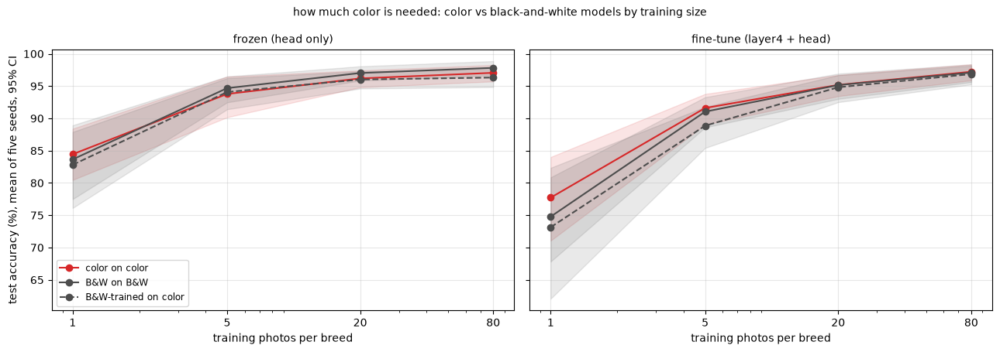

,model,photos per breed,color on color (%),B&W on B&W (%),B&W minus color (pp),CI low,CI high,"log loss, B&W minus color",log loss CI,B&W-trained on color photos (%),color-trained on B&W photos (%)
0,frozen (head only),1,84.45,83.65,-0.80,-4.41,2.61,-0.03,"[-0.114, +0.033]",82.81,83.78
1,frozen (head only),5,93.78,94.68,0.90,-1.07,3.14,0.01,"[-0.060, +0.084]",94.08,94.52
2,frozen (head only),20,96.19,97.02,0.84,-0.33,2.07,-0.01,"[-0.027, +0.013]",96.02,96.72
3,frozen (head only),80,97.06,97.83,0.77,-0.37,1.97,-0.02,"[-0.035, +0.000]",96.32,98.06
4,fine-tune (layer4 + head),1,77.73,74.78,-2.94,-7.12,0.84,0.06,"[+0.032, +0.098]",73.14,73.81
5,fine-tune (layer4 + head),5,91.61,91.04,-0.57,-1.97,0.94,0.07,"[+0.000, +0.166]",88.86,90.64
6,fine-tune (layer4 + head),20,95.18,95.15,-0.03,-1.34,1.27,-0.00,"[-0.031, +0.022]",94.82,93.71
7,fine-tune (layer4 + head),80,97.22,97.09,-0.13,-1.51,1.14,-0.00,"[-0.047, +0.048]",96.86,96.19


,trained and tested on,photos per breed,frozen (%),fine-tuned (%),fine-tuned minus frozen (pp),CI low,CI high
0,color,1,84.45,77.73,-6.72,-10.60,-2.94
1,color,5,93.78,91.61,-2.17,-4.08,-0.17
2,color,20,96.19,95.18,-1.00,-2.54,0.50
3,color,80,97.06,97.22,0.17,-0.94,1.27
4,gray,1,83.65,74.78,-8.86,-13.21,-4.78
5,gray,5,94.68,91.04,-3.65,-5.28,-2.04
6,gray,20,97.02,95.15,-1.87,-3.61,-0.27
7,gray,80,97.83,97.09,-0.74,-2.21,0.64


In [37]:
def pb_get(k, s, md, c, tv):
    """probabilities of one model on one version of the test photos, from Part 2a (k = 80) or Part 2b"""
    return probs[f"s{s}_{md}_{c}"][tv] if k == 80 else PB_P[f"k{k}_s{s}_{md}_{c}|{tv}"]


def pb_ci(stat, *arrs, seed):
    rng = np.random.default_rng(seed)
    S, N = arrs[0].shape[:2]
    out = np.empty(B_EXT)
    for b in range(B_EXT):
        si, ii = rng.integers(0, S, S), rng.integers(0, N, N)
        out[b] = stat(*(a[si][:, ii] for a in arrs))
    return np.percentile(out, [2.5, 97.5])


def pb_need():
    ar = np.arange(len(PB_Y))
    okk = lambda P: (P.argmax(1) == PB_Y).astype(float)
    nll = lambda P: -np.log(np.clip(P[ar, PB_Y], 1e-12, None))
    rows, curves = [], {}
    for c in CONDS:
        for k in PB_SIZES + [80]:
            g = lambda md, tv, f=okk: np.stack([f(pb_get(k, s, md, c, tv)) for s in SEEDS])
            A, B, GC, CG = g("color", "color"), g("gray", "gray"), g("gray", "color"), g("color", "gray")
            LA, LB = g("color", "color", nll), g("gray", "gray", nll)
            lo, hi = pb_ci(lambda a, b: b.mean() - a.mean(), A, B, seed=SEED + k)
            llo, lhi = pb_ci(lambda a, b: b.mean() - a.mean(), LA, LB, seed=SEED + k + 1)
            curves[c, k] = {n_: (100 * a.mean(), *(100 * pb_ci(np.mean, a, seed=SEED + k + 2))) for n_, a in
                            (("color on color", A), ("B&W on B&W", B), ("B&W-trained on color", GC))}
            rows.append({"model": lab_e[c], "photos per breed": k, "color on color (%)": 100 * A.mean(), "B&W on B&W (%)": 100 * B.mean(),
                         "B&W minus color (pp)": 100 * (B.mean() - A.mean()), "CI low": 100 * lo, "CI high": 100 * hi,
                         "log loss, B&W minus color": LB.mean() - LA.mean(), "log loss CI": f"[{llo:+.3f}, {lhi:+.3f}]",
                         "B&W-trained on color photos (%)": 100 * GC.mean(), "color-trained on B&W photos (%)": 100 * CG.mean()})
    return pd.DataFrame(rows), curves


def pb_fig_need(curves):
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
    ks = PB_SIZES + [80]
    for a_, c in zip(ax, CONDS):
        for name, col, ls in (("color on color", "tab:red", "-"), ("B&W on B&W", "0.3", "-"), ("B&W-trained on color", "0.3", "--")):
            mu = np.array([curves[c, k][name][0] for k in ks])
            lo = np.array([curves[c, k][name][1] for k in ks])
            hi = np.array([curves[c, k][name][2] for k in ks])
            a_.plot(ks, mu, ls, marker="o", color=col, label=name)
            a_.fill_between(ks, lo, hi, color=col, alpha=0.12)
        a_.set_xscale("log")
        a_.set_xticks(ks); a_.set_xticklabels([str(k) for k in ks])
        a_.set_xlabel("training photos per breed")
        a_.set_title(lab_e[c], fontsize=10)
        a_.grid(alpha=0.3)
    ax[0].set_ylabel("test accuracy (%), mean of five seeds, 95% CI")
    ax[0].legend(fontsize=8.5)
    fig.suptitle("how much color is needed: color vs black-and-white models by training size", fontsize=10)
    fig.tight_layout()
    fig.savefig(FIG / "figE12_need_by_size.png", dpi=150)
    plt.show()


pb_need_tab, pb_curves = pb_need()
pb_need_tab.to_csv(PB_DIR / "need_by_size.csv", index=False)
pb_fig_need(pb_curves)
display(pb_need_tab.round(2))


def pb_ft_vs_frozen():
    """not in the lock, descriptive: the fine-tuned minus the frozen model of the same seed, both trained and tested on the
    same kind of photo, by training size; the 80-photo rows reuse Part 2a's resamples (seed 43) and so repeat its intervals"""
    okk = lambda P: (P.argmax(1) == PB_Y).astype(float)
    rows = []
    for md in MODES:
        for k in PB_SIZES + [80]:
            A = np.stack([okk(pb_get(k, s, md, "frozen", md)) for s in SEEDS])
            B = np.stack([okk(pb_get(k, s, md, "finetune", md)) for s in SEEDS])
            lo, hi = pb_ci(lambda a, b: b.mean() - a.mean(), A, B, seed=SEED + 1 if k == 80 else SEED + k + 13)
            rows.append({"trained and tested on": md, "photos per breed": k, "frozen (%)": 100 * A.mean(),
                         "fine-tuned (%)": 100 * B.mean(), "fine-tuned minus frozen (pp)": 100 * (B.mean() - A.mean()),
                         "CI low": 100 * lo, "CI high": 100 * hi})
    return pd.DataFrame(rows)


pb_ftfr_tab = pb_ft_vs_frozen()
pb_ftfr_tab.to_csv(PB_DIR / "finetune_minus_frozen_by_size.csv", index=False)
pb_ftfr_tab.round(2)

**Learning without color costs little at any size.** For the frozen model, the black-and-white models stay within one point of the color models at every training size: −0.80 points with 1 photo per breed, and +0.90, +0.84 and +0.77 with 5, 20 and 80, all with intervals that include zero. For the fine-tuned model the gap grows as the photos become fewer, from −0.13 points with 80 and −0.03 with 20 to −0.57 with 5 and −2.94 with 1, where the interval (−7.12 to +0.84) still reaches zero. Log loss, which also counts confidence, is clearer at 1 photo: there the black-and-white fine-tuned models are worse by 0.06 (interval +0.032 to +0.098). So my first expectation holds, weakly, for the fine-tuned model, and not for the frozen one.

Two more things stand out. Learning in black and white and then seeing color photos (Prof. Lo's version) costs a little more than staying in black and white, at most 4.6 points below the color models (fine-tuned, 1 photo per breed). And below 80 photos the frozen model is ahead of the fine-tuned one at every size: 84.45% against 77.73% with 1 photo per breed, 93.78% against 91.61% with 5, and 96.19% against 95.18% with 20. In the second table, the gaps with 1 and 5 photos per breed have intervals below zero (−6.72 points, −10.60 to −2.94, and −2.17, −4.08 to −0.17), the gap with 20 photos does not (−1.00, −2.54 to +0.50), and with 80 photos fine-tuning is 0.17 points ahead (−0.94 to +1.27, Part 2a's result). In black and white the frozen model is ahead with intervals below zero at 1, 5 and 20 photos per breed. None of this was part of the locked plan, but it extends Part 1's answer: fine-tuning `layer4` never helps measurably here, and with few photos it hurts.

### How much is color used?
For each training size and model type, the color models' accuracy on each recolored version of the test photos, minus their accuracy on the original photos. The main comparison is the pet's colors rotated by 180°; the background's colors rotated by 180° and the whole photo at saturation 0% are the two references, and two differences answer expectations 3 and 5 directly. The ±30° rotations of the whole photo, averaged, show what a realistic color error costs. The second table and the last figure panel break the main comparison down by breed at 80 and at 1 photo per breed, and the third table shows where the recolored photos go.

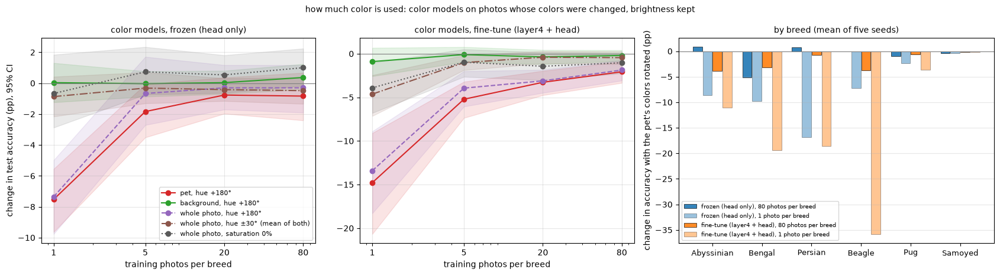

,model,photos per breed,original (%),"pet, hue +180° (pp)","pet, hue +180°: CI","background, hue +180° (pp)","background, hue +180°: CI","whole photo, hue +180° (pp)","whole photo, hue +180°: CI","whole photo, hue +90° (pp)",...,"whole photo, hue −30° (pp)","whole photo, saturation 50% (pp)","whole photo, saturation 0% (pp)","whole photo, saturation 0%: CI","whole photo, hue ±30°, mean of both (pp)","whole photo, hue ±30°: CI",pet minus background (pp),pet minus background: CI,wrong minus missing color (pp),wrong minus missing color: CI
0,frozen (head only),1,84.45,-7.53,"[-9.63, -5.55]",0.03,"[-1.24, +1.30]",-7.36,"[-9.77, -4.98]",-6.12,...,-1.67,0.37,-0.67,"[-2.88, +1.84]",-0.87,"[-2.16, +0.42]",-7.56,"[-9.60, -5.52]",-6.69,"[-10.43, -3.44]"
1,frozen (head only),5,93.78,-1.84,"[-3.51, -0.07]",-0.03,"[-0.87, +0.77]",-0.67,"[-2.71, +1.71]",-2.24,...,0.00,0.74,0.74,"[-0.74, +2.34]",-0.32,"[-1.30, +0.70]",-1.81,"[-3.51, +0.10]",-1.40,"[-2.84, -0.03]"
2,frozen (head only),20,96.19,-0.77,"[-1.97, +0.37]",0.03,"[-0.70, +0.80]",-0.30,"[-1.71, +1.17]",-1.97,...,-0.64,0.37,0.54,"[-0.64, +1.81]",-0.42,"[-1.15, +0.32]",-0.80,"[-1.97, +0.30]",-0.84,"[-1.91, +0.23]"
3,frozen (head only),80,97.06,-0.84,"[-2.41, +0.67]",0.37,"[-0.40, +1.24]",-0.30,"[-1.91, +1.17]",-1.44,...,-0.77,0.23,1.00,"[-0.17, +2.24]",-0.48,"[-1.34, +0.37]",-1.20,"[-2.58, +0.13]",-1.30,"[-2.48, -0.23]"
4,fine-tune (layer4 + head),1,77.73,-14.78,"[-20.67, -9.10]",-0.90,"[-2.58, +0.67]",-13.41,"[-18.29, -8.90]",-10.00,...,-5.99,-1.14,-3.91,"[-6.79, -1.04]",-4.63,"[-7.14, -2.46]",-13.88,"[-19.93, -8.43]",-9.50,"[-14.05, -4.88]"
5,fine-tune (layer4 + head),5,91.61,-5.22,"[-7.36, -3.21]",-0.10,"[-0.94, +0.77]",-3.95,"[-6.05, -2.01]",-4.38,...,-1.37,0.23,-0.97,"[-2.64, +0.50]",-1.02,"[-1.87, -0.17]",-5.12,"[-7.29, -3.18]",-2.98,"[-4.98, -1.40]"
6,fine-tune (layer4 + head),20,95.18,-3.28,"[-4.75, -1.97]",-0.37,"[-1.20, +0.43]",-3.11,"[-4.48, -1.84]",-3.08,...,-0.50,-0.33,-1.44,"[-3.04, +0.17]",-0.40,"[-1.12, +0.30]",-2.91,"[-4.38, -1.57]",-1.67,"[-3.18, -0.30]"
7,fine-tune (layer4 + head),80,97.22,-2.07,"[-3.34, -0.90]",-0.20,"[-0.84, +0.40]",-1.87,"[-3.08, -0.74]",-2.51,...,-0.50,-0.47,-1.04,"[-2.24, +0.10]",-0.45,"[-1.19, +0.27]",-1.87,"[-3.28, -0.60]",-0.84,"[-1.81, +0.13]"


Abyssinian  Bengal  Persian  \
photos per breed model                                                    
80               frozen (head only)                0.8    -5.2      0.8   
                 fine-tune (layer4 + head)        -3.9    -3.2     -0.8   
1                frozen (head only)               -8.6    -9.8    -16.8   
                 fine-tune (layer4 + head)       -11.0   -19.4    -18.6   

                                            Beagle  Pug  Samoyed  
photos per breed model                                            
80               frozen (head only)            0.0 -1.0     -0.4  
                 fine-tune (layer4 + head)    -3.8 -0.6     -0.2  
1                frozen (head only)           -7.2 -2.4     -0.4  
                 fine-tune (layer4 + head)   -35.8 -3.6     -0.2

,true breed,called after the change,count
0,Bengal,Abyssinian,39
1,Abyssinian,Bengal,33
2,Abyssinian,Pug,15
3,Beagle,Pug,9
4,Beagle,Samoyed,9
5,Bengal,Persian,8
6,Pug,Abyssinian,7
7,Persian,Samoyed,5
8,Abyssinian,Persian,3
9,Persian,Bengal,2


In [38]:
def pb_use():
    ok = lambda P: (P.argmax(1) == PB_Y).astype(float)
    main = ["pet, hue +180°", "background, hue +180°", "whole photo, hue +180°", "whole photo, saturation 0%"]
    rows, curves = [], {}
    for c in CONDS:
        for k in PB_SIZES + [80]:
            g = lambda cond: np.stack([ok(PB_P[f"k{k}_s{s}_color_{c}|{cond}"]) for s in SEEDS])
            O = np.stack([ok(pb_get(k, s, "color", c, "color")) for s in SEEDS])
            r = {"model": lab_e[c], "photos per breed": k, "original (%)": 100 * O.mean()}
            for cond in PB_CONDS:
                X = g(cond)
                r[f"{cond} (pp)"] = 100 * (X.mean() - O.mean())
                if cond in main:
                    lo, hi = pb_ci(lambda a, b: b.mean() - a.mean(), O, X, seed=SEED + 3 * k)
                    r[f"{cond}: CI"] = f"[{100 * lo:+.2f}, {100 * hi:+.2f}]"
                    curves[c, k, cond] = (100 * (X.mean() - O.mean()), 100 * lo, 100 * hi)
            Pt, Bg, Wh, Gr = g(main[0]), g(main[1]), g(main[2]), g(main[3])
            X30 = (g("whole photo, hue +30°") + g("whole photo, hue −30°")) / 2
            lo, hi = pb_ci(lambda a, b: b.mean() - a.mean(), O, X30, seed=SEED + 7 * k)
            r["whole photo, hue ±30°, mean of both (pp)"] = 100 * (X30.mean() - O.mean())
            r["whole photo, hue ±30°: CI"] = f"[{100 * lo:+.2f}, {100 * hi:+.2f}]"
            curves[c, k, "whole photo, hue ±30° (mean of both)"] = (100 * (X30.mean() - O.mean()), 100 * lo, 100 * hi)
            for name, a, b in (("pet minus background (pp)", Bg, Pt), ("wrong minus missing color (pp)", Gr, Wh)):
                lo, hi = pb_ci(lambda x, y: y.mean() - x.mean(), a, b, seed=SEED + 5 * k)
                r[name] = 100 * (b.mean() - a.mean())
                r[name.replace(" (pp)", ": CI")] = f"[{100 * lo:+.2f}, {100 * hi:+.2f}]"
            rows.append(r)
    return pd.DataFrame(rows), curves


def pb_breeds():
    ok = lambda P: (P.argmax(1) == PB_Y).astype(float)
    rows = []
    for k in (80, PB_SIZES[0]):
        for c in CONDS:
            O = np.stack([ok(pb_get(k, s, "color", c, "color")) for s in SEEDS])
            X = np.stack([ok(PB_P[f"k{k}_s{s}_color_{c}|pet, hue +180°"]) for s in SEEDS])
            rows.append({"photos per breed": k, "model": lab_e[c],
                         **{b: 100 * (X[:, PB_Y == i].mean() - O[:, PB_Y == i].mean()) for i, b in enumerate(BREEDS)}})
    return pd.DataFrame(rows).set_index(["photos per breed", "model"])


def pb_moves(k=80, cond="pet, hue +180°"):
    rows = []
    for s in SEEDS:
        for c in CONDS:
            before, after_ = pb_get(k, s, "color", c, "color").argmax(1), PB_P[f"k{k}_s{s}_color_{c}|{cond}"].argmax(1)
            for i in np.flatnonzero((before == PB_Y) & (after_ != PB_Y)):
                rows.append((BREEDS[PB_Y[i]], BREEDS[after_[i]]))
    return pd.DataFrame([(t, p, n) for (t, p), n in Counter(rows).most_common()],
                        columns=["true breed", "called after the change", "count"])


def pb_fig_use(curves, br):
    ks = PB_SIZES + [80]
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.7), gridspec_kw=dict(width_ratios=[1, 1, 1.15]))
    styles = {"pet, hue +180°": ("tab:red", "-"), "background, hue +180°": ("tab:green", "-"),
              "whole photo, hue +180°": ("tab:purple", "--"), "whole photo, hue ±30° (mean of both)": ("tab:brown", "-."),
              "whole photo, saturation 0%": ("0.35", ":")}
    for a_, c in zip(ax[:2], CONDS):
        for cond, (col, ls) in styles.items():
            mu = np.array([curves[c, k, cond][0] for k in ks])
            a_.plot(ks, mu, ls, marker="o", color=col, label=cond)
            a_.fill_between(ks, [curves[c, k, cond][1] for k in ks], [curves[c, k, cond][2] for k in ks], color=col, alpha=0.12)
        a_.axhline(0, color="0.5", lw=0.8)
        a_.set_xscale("log"); a_.set_xticks(ks); a_.set_xticklabels([str(k) for k in ks])
        a_.set_xlabel("training photos per breed")
        a_.set_title(f"color models, {lab_e[c]}", fontsize=10)
        a_.grid(alpha=0.3)
    ax[0].set_ylabel("change in test accuracy (pp), 95% CI")
    ax[0].legend(fontsize=8)
    x = np.arange(len(BREEDS))
    for off, (key, c) in zip((-0.3, -0.1, 0.1, 0.3), [(k_, c_) for c_ in CONDS for k_ in (80, PB_SIZES[0])]):
        if (key, lab_e[c]) in br.index:
            ax[2].bar(x + off, br.loc[(key, lab_e[c])].to_numpy(dtype=float), 0.19, color=col_e[c],
                      alpha=0.9 if key == 80 else 0.45, edgecolor="k", lw=0.5,
                      label=f"{lab_e[c]}, {key} photo{'s' if key > 1 else ''} per breed")
    ax[2].axhline(0, color="0.5", lw=0.8)
    ax[2].set_xticks(x); ax[2].set_xticklabels(BREEDS, fontsize=9)
    ax[2].set_ylabel("change in accuracy with the pet's colors rotated (pp)")
    ax[2].set_title("by breed (mean of five seeds)", fontsize=10)
    ax[2].legend(fontsize=7.5); ax[2].grid(alpha=0.3, axis="y")
    fig.suptitle("how much color is used: color models on photos whose colors were changed, brightness kept", fontsize=10)
    fig.tight_layout()
    fig.savefig(FIG / "figE13_use_of_color.png", dpi=150)
    plt.show()


pb_use_tab, pb_use_curves = pb_use()
pb_breed_tab = pb_breeds()
pb_moves_tab = pb_moves()
for _t, _n in ((pb_use_tab, "use_by_size.csv"), (pb_breed_tab, "use_by_breed.csv"), (pb_moves_tab, "moves_pet_hue180_k80.csv")):
    _t.to_csv(PB_DIR / _n)
pb_fig_use(pb_use_curves, pb_breed_tab)
display(pb_use_tab.round(2))
display(pb_breed_tab.round(1))
pb_moves_tab.head(12)

**The color models do use color, and the fewer photos they learned from, the more.** Rotating the pet's colors by 180° lowers the fine-tuned models' accuracy at every training size, with intervals that exclude zero: by 14.78 points with 1 photo per breed, 5.22 with 5, 3.28 with 20 and 2.07 with 80. The frozen models lose 7.53 points with 1 photo and 1.84 with 5, while with 20 and 80 their losses (0.77 and 0.84) are within the noise. So my second expectation holds, fully for the fine-tuned model and at the small sizes for the frozen one, and at every size the fine-tuned models lose more than the frozen ones.

**It is the pet's color, not the background's.** Rotating the background's colors changes accuracy by less than one point in every case, and the pet-minus-background difference is negative everywhere; for the fine-tuned model it is −13.88 points with 1 photo and −1.87 with 80, both with intervals below zero. That confirms my third expectation, and it settles the Clever Hans worry for color: the scenery's color plays no measurable part.

**A wrong color is worse than no color.** For the frozen color models, the whole photo at saturation 0% costs nothing measurable at any size (−0.67 to +1.00 points), while the same photo with its colors rotated by 180° costs more. The wrong-minus-missing difference is below zero with 1, 5 and 80 photos for the frozen model and with 1, 5 and 20 for the fine-tuned one, so my fifth expectation, the least certain one, holds. A realistic error of ±30° costs little: nothing measurable for the frozen model at any size, and for the fine-tuned model 4.63 points with 1 photo and 1.02 with 5, but nothing measurable beyond.

**The breeds are not the ones I expected.** As predicted, the white Samoyed barely moves (at most 0.40 points). But the Pug barely moves either (at most 3.60 points), although its fawn coat looked diagnostic. With 80 photos the losses are small and fall on Abyssinian, Bengal and Beagle; with 1 photo per breed they are large for Beagle (−35.80 points for the fine-tuned model), Bengal, Persian and Abyssinian. Persians come in many colors, so a model that has seen a single Persian has probably learned that one cat's color. My fourth expectation is only half right. The last table shows where the photos go: about half of those that flip with 80 photos per breed move between the two cats, Bengal to Abyssinian (39) and Abyssinian to Bengal (33), the pair at the center of Part 1's errors.

### Where the evidence moves when only the color changes
For the four test photos whose probability of the true breed falls most when the pet's colors are rotated, averaged over the two 80-photo color models of seed 42, the figure shows Grad-CAM of the true breed at `layer4` on the original and on the recolored photo. For this layer Grad-CAM equals the class activation map divided by 49, the identity Part 1 checks, so I compute it from the class activation map directly. Each model's two maps share one color scale, so a weaker map on the recolored photo means less evidence for the true breed, not just a different normalization. Since the brightness is the same in both photos, any difference between the two maps comes from color alone.

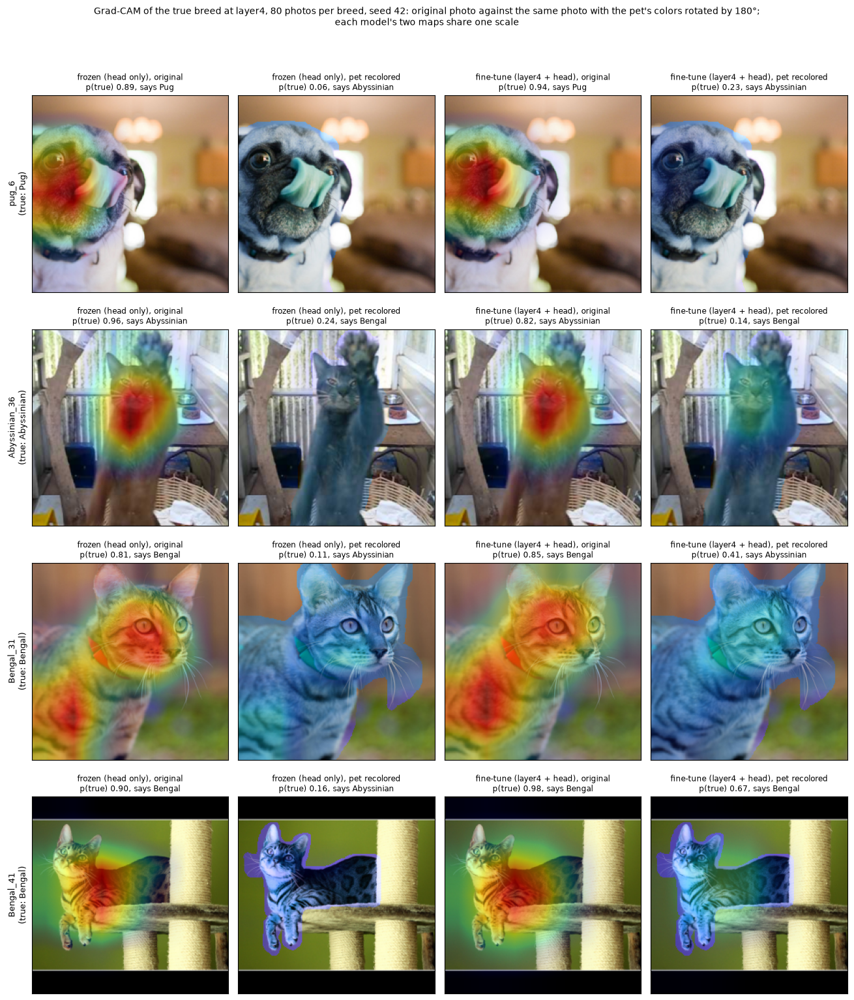

In [39]:
def pb_cam(m, x):
    """logits and the true breed's class activation maps (positive part, N x 7 x 7) at layer4"""
    a = m.maxpool(m.relu(m.bn1(m.conv1(x))))
    a = m.layer4(m.layer3(m.layer2(m.layer1(a))))
    lg = m.fc(torch.flatten(m.avgpool(a), 1))
    return lg, a


def pb_fig_cam():
    ar = np.arange(len(PB_Y))
    drop = np.mean([pb_get(80, SEED, "color", c, "color")[ar, PB_Y] - PB_P[f"k80_s{SEED}_color_{c}|pet, hue +180°"][ar, PB_Y] for c in CONDS], 0)
    top = np.argsort(-drop, kind="stable")[:4]
    fig, ax = plt.subplots(len(top), 4, figsize=(13.2, 3.95 * len(top)), squeeze=False)
    with torch.no_grad():
        for col0, c in ((0, "frozen"), (2, "finetune")):
            info = ext_lock["models"][f"s{SEED}_color_{c}"]
            m = build_seed(SEED)
            m.load_state_dict(torch.load(OUT / info["checkpoint"], map_location="cpu"))
            m = setup(m, c).to(device).eval()
            W = m.fc.weight
            for r, i in enumerate(top):
                ims = [PB_RGB[i:i + 1].to(device).float().div(255), pb_recolor(PB_RGB[i:i + 1], slice(i, i + 1), "pet, hue +180°")]
                maps, ps = [], []
                for x in ims:
                    lg, feat = pb_cam(m, (x - PB_M) / PB_S)
                    maps.append(torch.einsum("nkhw,k->nhw", feat, W[int(PB_Y[i])]).clamp(min=0)[0].cpu())
                    ps.append(lg.softmax(1)[0].cpu().numpy())
                lim = max(float(mm.max()) for mm in maps) or 1.0
                for j, (x, mm, p) in enumerate(zip(ims, maps, ps)):
                    a_ = ax[r, col0 + j]
                    up = torch.nn.functional.interpolate(mm[None, None], size=(224, 224), mode="bilinear", align_corners=False)[0, 0].numpy()
                    rgba = plt.get_cmap("jet")(up / lim)
                    rgba[..., 3] = 0.6 * (up / lim) ** 0.8
                    a_.imshow(x[0].permute(1, 2, 0).cpu().numpy())
                    a_.imshow(rgba)
                    a_.set_title(f"{lab_e[c]}, {'original' if j == 0 else 'pet recolored'}\np(true) {p[PB_Y[i]]:.2f}, "
                                 f"says {BREEDS[int(p.argmax())]}", fontsize=8.5)
                    a_.set_xticks([]); a_.set_yticks([])
                ax[r, 0].set_ylabel(f"{req_pred.image_id[i]}\n(true: {BREEDS[PB_Y[i]]})", fontsize=9)
            del m
    fig.suptitle(f"Grad-CAM of the true breed at layer4, 80 photos per breed, seed {SEED}: original photo against the same photo with "
                 "the pet's colors rotated by 180°;\neach model's two maps share one scale", fontsize=10)
    fig.tight_layout(rect=(0, 0, 1, 0.955), h_pad=1.8)
    fig.savefig(FIG / "figE14_gradcam_recolored.png", dpi=130)
    plt.show()


pb_fig_cam()

On these four photos, the evidence for the true breed nearly vanishes once the pet's colors are rotated, although the brightness, and with it every shape and texture, is unchanged. In the original photos the maps sit where one would hope: on the Pug's face, on the Abyssinian's head, and on the Bengals' faces and spotted coats. On the recolored photos the same regions give almost no evidence for the true breed, and the models answer with the look-alike: the Pug and both Bengals become Abyssinians, and the Abyssinian becomes a Bengal. Only the fine-tuned model keeps one of them, Bengal_41, at 0.67. For these photos, what the models found on the pet was its color. pug_6 is also the first photo of figE4, the fawn Pug that the black-and-white frozen model called a Beagle.

### Summary of Part 2b
The next cell writes every table of Part 2b to `results/ext_size/SUMMARY.md`, so that the report can be checked against it.

In [40]:
from IPython.display import Markdown


def pb_summary():
    def rows_md(df):
        df = df.reset_index() if not isinstance(df.index, pd.RangeIndex) else df
        f = lambda v: f"{v:.2f}" if isinstance(v, (float, np.floating)) else str(v)
        return (["| " + " | ".join(str(c_) for c_ in df.columns) + " |", "|" + "---|" * len(df.columns)]
                + ["| " + " | ".join(f(v) for v in r) + " |" for r in df.itertuples(index=False)])
    L = ["# Part 2b: fewer photos, and changing only the color (generated from the saved results)", "",
         f"locked {PB_LOCKED['locked_at']}; sizes {PB_SIZES} plus 80 (Part 2a); seeds {SEEDS}; bootstrap {B_EXT} resamples", ""]
    for title, df in (("Literal stopping rule (Part 1)", lit_tab), ("Validation, mean correct of 120", pb_val.pivot_table(
            index="photos_per_breed", columns=["trained_on", "model"], values="val_correct", aggfunc="mean").round(1)),
                      ("Brightness check of the color changes", pb_luma_tab), ("Control: black-and-white models", pd.DataFrame(pb_ctrl)),
                      ("Need, by training size", pb_need_tab),
                      ("Fine-tuned minus frozen, by training size (not in the lock)", pb_ftfr_tab), ("Use, by training size", pb_use_tab),
                      ("Use by breed: pet's colors rotated by 180° (pp)", pb_breed_tab), ("Where the recolored photos go (80 photos)", pb_moves_tab)):
        L += [f"## {title}", ""] + rows_md(df) + [""]
    text_ = "\n".join(L) + "\n"
    (PB_DIR / "SUMMARY.md").write_text(text_, encoding="utf-8")
    return text_


display(Markdown(pb_summary()))

# Part 2b: fewer photos, and changing only the color (generated from the saved results)

locked 2026-11-18T02:14:57+00:00; sizes [1, 5, 20] plus 80 (Part 2a); seeds [42, 1, 2, 3, 4]; bootstrap 10000 resamples

## Literal stopping rule (Part 1)

| protocol | epochs | selected epoch, frozen | selected epoch, fine-tune | frozen correct | fine-tune correct | macro-F1, frozen | macro-F1, fine-tune | fine-tune minus frozen (pp) | 95% CI | exact McNemar p |
|---|---|---|---|---|---|---|---|---|---|---|
| locked protocol (plateau checks from epoch 100) | 100 | 20 | 1 | 584/598 | 587/598 | 0.98 | 0.98 | 0.50 | [-0.67, +1.67] | 0.61 |
| the assignment's literal rule (floor of 5 epochs) | 5 | 4 | 1 | 584/598 | 587/598 | 0.98 | 0.98 | 0.50 | [-0.84, +1.67] | 0.61 |

## Validation, mean correct of 120

| ('photos_per_breed', '') | ('color', 'finetune') | ('color', 'frozen') | ('gray', 'finetune') | ('gray', 'frozen') |
|---|---|---|---|---|
| 1 | 93.00 | 101.20 | 90.60 | 98.40 |
| 5 | 109.20 | 112.00 | 106.40 | 111.20 |
| 20 | 116.80 | 117.00 | 112.60 | 115.60 |

## Brightness check of the color changes

| change | pixels in the region (%) | region pixels whose color changed (%) | region pixels whose brightness moved by more than 1 of 255 (%) |
|---|---|---|---|
| pet, hue +180° | 60.96 | 98.44 | 1.58 |
| background, hue +180° | 39.04 | 96.21 | 3.84 |
| whole photo, hue +180° | 100.00 | 97.57 | 2.47 |
| whole photo, hue +90° | 100.00 | 97.57 | 1.54 |
| whole photo, hue −90° | 100.00 | 97.57 | 1.18 |
| whole photo, hue +30° | 100.00 | 96.27 | 1.62 |
| whole photo, hue −30° | 100.00 | 96.25 | 1.38 |
| whole photo, saturation 50% | 100.00 | 96.28 | 0.00 |
| whole photo, saturation 0% | 100.00 | 97.57 | 0.00 |

## Control: black-and-white models

| seed | model | changed | largest_p_change |
|---|---|---|---|
| 42 | frozen | 0 | 0.06 |
| 42 | finetune | 0 | 0.06 |
| 1 | frozen | 0 | 0.05 |
| 1 | finetune | 0 | 0.15 |
| 2 | frozen | 0 | 0.06 |
| 2 | finetune | 0 | 0.10 |
| 3 | frozen | 0 | 0.04 |
| 3 | finetune | 0 | 0.04 |
| 4 | frozen | 1 | 0.04 |
| 4 | finetune | 2 | 0.04 |

## Need, by training size

| model | photos per breed | color on color (%) | B&W on B&W (%) | B&W minus color (pp) | CI low | CI high | log loss, B&W minus color | log loss CI | B&W-trained on color photos (%) | color-trained on B&W photos (%) |
|---|---|---|---|---|---|---|---|---|---|---|
| frozen (head only) | 1 | 84.45 | 83.65 | -0.80 | -4.41 | 2.61 | -0.03 | [-0.114, +0.033] | 82.81 | 83.78 |
| frozen (head only) | 5 | 93.78 | 94.68 | 0.90 | -1.07 | 3.14 | 0.01 | [-0.060, +0.084] | 94.08 | 94.52 |
| frozen (head only) | 20 | 96.19 | 97.02 | 0.84 | -0.33 | 2.07 | -0.01 | [-0.027, +0.013] | 96.02 | 96.72 |
| frozen (head only) | 80 | 97.06 | 97.83 | 0.77 | -0.37 | 1.97 | -0.02 | [-0.035, +0.000] | 96.32 | 98.06 |
| fine-tune (layer4 + head) | 1 | 77.73 | 74.78 | -2.94 | -7.12 | 0.84 | 0.06 | [+0.032, +0.098] | 73.14 | 73.81 |
| fine-tune (layer4 + head) | 5 | 91.61 | 91.04 | -0.57 | -1.97 | 0.94 | 0.07 | [+0.000, +0.166] | 88.86 | 90.64 |
| fine-tune (layer4 + head) | 20 | 95.18 | 95.15 | -0.03 | -1.34 | 1.27 | -0.00 | [-0.031, +0.022] | 94.82 | 93.71 |
| fine-tune (layer4 + head) | 80 | 97.22 | 97.09 | -0.13 | -1.51 | 1.14 | -0.00 | [-0.047, +0.048] | 96.86 | 96.19 |

## Fine-tuned minus frozen, by training size (not in the lock)

| trained and tested on | photos per breed | frozen (%) | fine-tuned (%) | fine-tuned minus frozen (pp) | CI low | CI high |
|---|---|---|---|---|---|---|
| color | 1 | 84.45 | 77.73 | -6.72 | -10.60 | -2.94 |
| color | 5 | 93.78 | 91.61 | -2.17 | -4.08 | -0.17 |
| color | 20 | 96.19 | 95.18 | -1.00 | -2.54 | 0.50 |
| color | 80 | 97.06 | 97.22 | 0.17 | -0.94 | 1.27 |
| gray | 1 | 83.65 | 74.78 | -8.86 | -13.21 | -4.78 |
| gray | 5 | 94.68 | 91.04 | -3.65 | -5.28 | -2.04 |
| gray | 20 | 97.02 | 95.15 | -1.87 | -3.61 | -0.27 |
| gray | 80 | 97.83 | 97.09 | -0.74 | -2.21 | 0.64 |

## Use, by training size

| model | photos per breed | original (%) | pet, hue +180° (pp) | pet, hue +180°: CI | background, hue +180° (pp) | background, hue +180°: CI | whole photo, hue +180° (pp) | whole photo, hue +180°: CI | whole photo, hue +90° (pp) | whole photo, hue −90° (pp) | whole photo, hue +30° (pp) | whole photo, hue −30° (pp) | whole photo, saturation 50% (pp) | whole photo, saturation 0% (pp) | whole photo, saturation 0%: CI | whole photo, hue ±30°, mean of both (pp) | whole photo, hue ±30°: CI | pet minus background (pp) | pet minus background: CI | wrong minus missing color (pp) | wrong minus missing color: CI |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| frozen (head only) | 1 | 84.45 | -7.53 | [-9.63, -5.55] | 0.03 | [-1.24, +1.30] | -7.36 | [-9.77, -4.98] | -6.12 | -3.48 | -0.07 | -1.67 | 0.37 | -0.67 | [-2.88, +1.84] | -0.87 | [-2.16, +0.42] | -7.56 | [-9.60, -5.52] | -6.69 | [-10.43, -3.44] |
| frozen (head only) | 5 | 93.78 | -1.84 | [-3.51, -0.07] | -0.03 | [-0.87, +0.77] | -0.67 | [-2.71, +1.71] | -2.24 | -0.77 | -0.64 | 0.00 | 0.74 | 0.74 | [-0.74, +2.34] | -0.32 | [-1.30, +0.70] | -1.81 | [-3.51, +0.10] | -1.40 | [-2.84, -0.03] |
| frozen (head only) | 20 | 96.19 | -0.77 | [-1.97, +0.37] | 0.03 | [-0.70, +0.80] | -0.30 | [-1.71, +1.17] | -1.97 | -0.47 | -0.20 | -0.64 | 0.37 | 0.54 | [-0.64, +1.81] | -0.42 | [-1.15, +0.32] | -0.80 | [-1.97, +0.30] | -0.84 | [-1.91, +0.23] |
| frozen (head only) | 80 | 97.06 | -0.84 | [-2.41, +0.67] | 0.37 | [-0.40, +1.24] | -0.30 | [-1.91, +1.17] | -1.44 | -0.74 | -0.20 | -0.77 | 0.23 | 1.00 | [-0.17, +2.24] | -0.48 | [-1.34, +0.37] | -1.20 | [-2.58, +0.13] | -1.30 | [-2.48, -0.23] |
| fine-tune (layer4 + head) | 1 | 77.73 | -14.78 | [-20.67, -9.10] | -0.90 | [-2.58, +0.67] | -13.41 | [-18.29, -8.90] | -10.00 | -10.84 | -3.28 | -5.99 | -1.14 | -3.91 | [-6.79, -1.04] | -4.63 | [-7.14, -2.46] | -13.88 | [-19.93, -8.43] | -9.50 | [-14.05, -4.88] |
| fine-tune (layer4 + head) | 5 | 91.61 | -5.22 | [-7.36, -3.21] | -0.10 | [-0.94, +0.77] | -3.95 | [-6.05, -2.01] | -4.38 | -3.61 | -0.67 | -1.37 | 0.23 | -0.97 | [-2.64, +0.50] | -1.02 | [-1.87, -0.17] | -5.12 | [-7.29, -3.18] | -2.98 | [-4.98, -1.40] |
| fine-tune (layer4 + head) | 20 | 95.18 | -3.28 | [-4.75, -1.97] | -0.37 | [-1.20, +0.43] | -3.11 | [-4.48, -1.84] | -3.08 | -3.61 | -0.30 | -0.50 | -0.33 | -1.44 | [-3.04, +0.17] | -0.40 | [-1.12, +0.30] | -2.91 | [-4.38, -1.57] | -1.67 | [-3.18, -0.30] |
| fine-tune (layer4 + head) | 80 | 97.22 | -2.07 | [-3.34, -0.90] | -0.20 | [-0.84, +0.40] | -1.87 | [-3.08, -0.74] | -2.51 | -2.47 | -0.40 | -0.50 | -0.47 | -1.04 | [-2.24, +0.10] | -0.45 | [-1.19, +0.27] | -1.87 | [-3.28, -0.60] | -0.84 | [-1.81, +0.13] |

## Use by breed: pet's colors rotated by 180° (pp)

| photos per breed | model | Abyssinian | Bengal | Persian | Beagle | Pug | Samoyed |
|---|---|---|---|---|---|---|---|
| 80 | frozen (head only) | 0.82 | -5.20 | 0.80 | 0.00 | -1.00 | -0.40 |
| 80 | fine-tune (layer4 + head) | -3.88 | -3.20 | -0.80 | -3.80 | -0.60 | -0.20 |
| 1 | frozen (head only) | -8.57 | -9.80 | -16.80 | -7.20 | -2.40 | -0.40 |
| 1 | fine-tune (layer4 + head) | -11.02 | -19.40 | -18.60 | -35.80 | -3.60 | -0.20 |

## Where the recolored photos go (80 photos)

| true breed | called after the change | count |
|---|---|---|
| Bengal | Abyssinian | 39 |
| Abyssinian | Bengal | 33 |
| Abyssinian | Pug | 15 |
| Beagle | Pug | 9 |
| Beagle | Samoyed | 9 |
| Bengal | Persian | 8 |
| Pug | Abyssinian | 7 |
| Persian | Samoyed | 5 |
| Abyssinian | Persian | 3 |
| Persian | Bengal | 2 |
| Persian | Abyssinian | 2 |
| Samoyed | Abyssinian | 2 |
| Bengal | Pug | 2 |
| Pug | Beagle | 2 |
| Beagle | Abyssinian | 2 |
| Bengal | Samoyed | 1 |
| Abyssinian | Beagle | 1 |
| Samoyed | Beagle | 1 |



## Summary and files
The last cell writes every number of Part 2a to `results/ext_gray/SUMMARY.md` (Part 2b's are in `results/ext_size/SUMMARY.md`), so the report can be checked against them, and rebuilds `d370_results_bundle.zip` with all results and figures of both parts, but without model weights.

In [41]:
def md_table(df, fmt="{:.2f}"):
    out = ["| " + " | ".join([str(df.index.name or "")] + [str(c) for c in df.columns]) + " |", "|" + "---|" * (len(df.columns) + 1)]
    for i, r in df.iterrows():
        out.append("| " + " | ".join([str(i)] + [fmt.format(v) if isinstance(v, (float, np.floating)) else str(v) for v in r]) + " |")
    return out

L = ["# Extension: what is left without color? (generated from the saved results)", "",
     f"locked {ext_lock['locked_at']}, test scored {json.loads(done_path.read_text(encoding="utf-8"))['time']}, "
     f"{len(ext_lock['models'])} models, seeds {SEEDS}", "", f"## Seed {SEED} (n = {n_t} test images)", "",
     "| model | trained on | color test | gray test |", "|---|---|---|---|"]
for c in CONDS:
    for md in MODES:
        L.append(f"| {lab_e[c]} | {md} | " + " | ".join(f"{100 * OK(SEED, md, c, tv).mean():.2f}% ({int(OK(SEED, md, c, tv).sum())}/{n_t})"
                                                     for tv in MODES) + " |")
L += ["", "| comparison | difference (pp) | 95% CI | McNemar p | macro-F1 difference [95% CI] |", "|---|---|---|---|---|"]
for r in comp:
    f1s = f"{r['macro_f1_diff']:+.4f} [{r['macro_f1_ci95'][0]:+.4f}, {r['macro_f1_ci95'][1]:+.4f}]" if "macro_f1_diff" in r else ""
    L.append(f"| {r['comparison']} | {r['diff_pp']:+.2f} | [{r['ci95_pp'][0]:+.2f}, {r['ci95_pp'][1]:+.2f}] | "
             f"{r['mcnemar_p']:.4f} | {f1s} |" if "mcnemar_p" in r else
             f"| {r['comparison']} | {r['diff_pp']:+.2f} | [{r['ci95_pp'][0]:+.2f}, {r['ci95_pp'][1]:+.2f}] |  | {f1s} |")
L += [""] + [f"- {lab_e[c]}: errors {round(n_t * (1 - OK(SEED, 'color', c, 'color').mean()))} in color, "
             f"{round(n_t * (1 - OK(SEED, 'gray', c, 'gray').mean()))} in gray" for c in CONDS]
L += ["", f"## All seeds {SEEDS}", ""] + md_table(pd.concat([seed_tab, pd.DataFrame({"mean": seed_tab.mean(), "SD": seed_tab.std()}).T]))
L += ["", "95% intervals for the means (bootstrap over seeds and test images):", ""]
L += [f"- {k}: mean {seed_tab[k].mean():+.2f}, [{v[0]:+.2f}, {v[1]:+.2f}]" for k, v in ci.items()]
L += ["", "## Recall by breed (%), mean over seeds", ""] + md_table(pcs, "{:.1f}")
text = "\n".join(L) + "\n"
(EXT / "SUMMARY.md").write_text(text, encoding="utf-8")

bundle = OUT / f"d370_results_bundle{sfx}.zip"
with zipfile.ZipFile(bundle, "w", zipfile.ZIP_DEFLATED) as z:
    for d in (RES, FIG):
        for f in sorted(d.rglob("*")):
            if f.is_file():
                z.write(f, f.relative_to(OUT))
print(f"results/ext_gray/SUMMARY.md written; {bundle.name}: {bundle.stat().st_size / 2**20:.1f} MiB")
from IPython.display import Markdown
display(Markdown(text))

results/ext_gray/SUMMARY.md written; d370_results_bundle.zip: 20.8 MiB


# Extension: what is left without color? (generated from the saved results)

locked 2026-11-17T00:04:27+00:00, test scored 2026-11-17T00:05:06+00:00, 20 models, seeds [42, 1, 2, 3, 4]

## Seed 42 (n = 598 test images)

| model | trained on | color test | gray test |
|---|---|---|---|
| frozen (head only) | color | 97.66% (584/598) | 97.16% (581/598) |
| frozen (head only) | gray | 96.49% (577/598) | 97.99% (586/598) |
| fine-tune (layer4 + head) | color | 98.16% (587/598) | 97.32% (582/598) |
| fine-tune (layer4 + head) | gray | 97.83% (585/598) | 96.99% (580/598) |

| comparison | difference (pp) | 95% CI | McNemar p | macro-F1 difference [95% CI] |
|---|---|---|---|---|
| P1 frozen: gray - color | +0.33 | [-0.84, +1.51] | 0.7744 | +0.0033 [-0.0083, +0.0146] |
| P2 fine-tune: gray - color | -1.17 | [-2.17, -0.33] | 0.0391 | -0.0119 [-0.0225, -0.0028] |
| S1 gray: fine-tune - frozen | -1.00 | [-2.51, +0.33] | 0.2379 | -0.0103 [-0.0253, +0.0036] |
| D1 frozen color model: gray test - color test | -0.50 | [-1.51, +0.50] | 0.5078 |  |
| D2 fine-tune color model: gray test - color test | -0.84 | [-1.84, +0.00] | 0.1797 |  |
| D3 frozen, gray test: trained on gray - on color | +0.84 | [-0.33, +2.01] | 0.2668 |  |
| D4 fine-tune, gray test: trained on gray - on color | -0.33 | [-1.34, +0.50] | 0.7266 |  |
| S2 (fine-tune - frozen in gray) - (fine-tune - frozen in color) | -1.51 | [-3.01, +0.00] |  |  |

- frozen (head only): errors 14 in color, 12 in gray
- fine-tune (layer4 + head): errors 11 in color, 18 in gray

## All seeds [42, 1, 2, 3, 4]

|  | color-trained frozen (%) | color-trained finetune (%) | gray-trained frozen (%) | gray-trained finetune (%) | frozen: gray - color (pp) | fine-tune: gray - color (pp) | fine-tune - frozen, color (pp) | fine-tune - frozen, gray (pp) | difference in differences (pp) |
|---|---|---|---|---|---|---|---|---|---|
| 42 | 97.66 | 98.16 | 97.99 | 96.99 | 0.33 | -1.17 | 0.50 | -1.00 | -1.51 |
| 1 | 96.66 | 97.66 | 97.99 | 95.82 | 1.34 | -1.84 | 1.00 | -2.17 | -3.18 |
| 2 | 96.49 | 95.82 | 97.99 | 96.49 | 1.51 | 0.67 | -0.67 | -1.51 | -0.84 |
| 3 | 97.16 | 96.99 | 97.49 | 97.99 | 0.33 | 1.00 | -0.17 | 0.50 | 0.67 |
| 4 | 97.32 | 97.49 | 97.66 | 98.16 | 0.33 | 0.67 | 0.17 | 0.50 | 0.33 |
| mean | 97.06 | 97.22 | 97.83 | 97.09 | 0.77 | -0.13 | 0.17 | -0.74 | -0.90 |
| SD | 0.48 | 0.89 | 0.24 | 0.99 | 0.60 | 1.28 | 0.64 | 1.20 | 1.54 |

95% intervals for the means (bootstrap over seeds and test images):

- frozen: gray - color (pp): mean +0.77, [-0.37, +1.97]
- fine-tune: gray - color (pp): mean -0.13, [-1.47, +1.14]
- fine-tune - frozen, color (pp): mean +0.17, [-0.94, +1.27]
- fine-tune - frozen, gray (pp): mean -0.74, [-2.21, +0.64]
- difference in differences (pp): mean -0.90, [-2.71, +0.74]

## Recall by breed (%), mean over seeds

| breed | frozen: color | frozen: gray | finetune: color | finetune: gray | frozen: change | finetune: change |
|---|---|---|---|---|---|---|
| Abyssinian | 90.6 | 93.1 | 91.2 | 92.2 | 2.4 | 1.0 |
| Bengal | 95.8 | 98.6 | 96.6 | 96.6 | 2.8 | 0.0 |
| Persian | 96.0 | 97.2 | 96.4 | 95.2 | 1.2 | -1.2 |
| Beagle | 100.0 | 100.0 | 99.8 | 99.8 | 0.0 | 0.0 |
| Pug | 99.8 | 98.0 | 99.6 | 98.8 | -1.8 | -0.8 |
| Samoyed | 100.0 | 100.0 | 99.6 | 99.8 | 0.0 | 0.2 |


## What I take from this

**Part 1.** On these six breeds, partially fine-tuning ResNet18 does not improve the predictions enough to pay for it. The gain is 3 of 598 test photos, well inside the noise, and the five-seed repeat in Part 2a tells the same story (+0.17 points, interval −0.94 to +1.27). The cost is small either way on my GPU: about 10% more time per epoch, and counted to the selected checkpoints, the fine-tuned model needed even less training (about 2 s against under 40 s). What fine-tuning really costs is care: its best checkpoint came after one epoch, and without validation-based selection it would have overfit badly. The errors that remain sit in the two breeds ImageNet never labeled, Abyssinian and Bengal. The assignment's literal stopping rule gives the same answer (584 and 587), and Part 2b adds that with fewer photos the frozen model is clearly ahead (84.45% against 77.73% with one photo per breed; interval for the difference −10.60 to −2.94 points).

**Part 2a.** With 80 training photos per breed, color is almost free to lose. Matched in black and white, neither model loses measurable accuracy over five seeds, and at seed 42 the models that learned in black and white recognized color photos almost as well as the models that learned in color (7 and 2 photos fewer). Where color does seem to matter is in single photos where it separates a breed from a look-alike, such as a fawn Pug against a Beagle or a white Persian against a Samoyed. That resembles what Bramão et al. (2011) describe for people, where color helps most when it is diagnostic.

**Part 2b.** The models do not need color, but they use it. Learning without color costs at most a few points even with one photo per breed, and nothing measurable from 20 photos on. Yet changing only the pet's colors, with the brightness kept, lowers the fine-tuned color models' accuracy at every training size, much more with few photos (14.78 points with 1 photo per breed, 2.07 with 80), and the frozen ones' with 1 and 5 photos. That is what Hermann and Lampinen (2020) lead one to expect: color is an easy feature, so a model that has it uses it, even when other cues would do. With more photos the reliance shrinks, which is why taking color away from 80 photos per breed costs almost nothing. The color that matters is the pet's, not the scenery's, and a wrong color is worse than none. Which breeds depend on it is less predictable than I thought: the white Samoyed is immune by construction, but so, unexpectedly, is the Pug, while with a single photo per breed even the many-colored Persian falls.

## Uncertainty, limitations and next experiment

**One source of uncertainty: the seed.** The test set holds 598 photos, so one photo is 0.17 points, and the seed moves results as much as the effects themselves: the seed-to-seed standard deviations in the five-seed table reach 1.5 points, and seed 42 happened to give the best frozen model of the five. That is why Part 2 reports every comparison over five seeds, with intervals that resample both the seeds and the photos.

**Other limits.** Only the frozen and `layer4` settings were tried, with the assignment's constant learning rates and no weight decay. The color change of Part 2b produces colors that real pets never have, such as a blue-gray Pug, so it measures how much the models rely on color, not how they would do on natural photos, and the trimap's uncertain border is counted as part of the pet. At one photo per breed, the fine-tuned model's BatchNorm statistics in `layer4` come from only six photos, and each seed draws a different six, so results at that size vary much more than at the others.

**One next experiment.** Since the color models do lean on color, the natural next step is to train with random hue rotations as augmentation, which removes color as a cue but keeps the brightness, and to test whether that removes the reliance without costing accuracy and whether it changes the look-alike errors, such as the fawn Pug called a Beagle.

## References

Anthropic. (2026). *Claude* [Large language model]. <https://www.anthropic.com/claude>

Bramão, I., Reis, A., Petersson, K. M., & Faísca, L. (2011). The role of color information on object recognition: A review and meta-analysis. *Acta Psychologica, 138*(1), 244–253. <https://doi.org/10.1016/j.actpsy.2011.06.010>

He, K., Zhang, X., Ren, S., & Sun, J. (2016). Deep residual learning for image recognition. In *Proceedings of the 2016 IEEE Conference on Computer Vision and Pattern Recognition* (pp. 770–778). IEEE. <https://doi.org/10.1109/CVPR.2016.90>

Hermann, K. L., & Lampinen, A. K. (2020). What shapes feature representations? Exploring datasets, architectures, and training. *Advances in Neural Information Processing Systems, 33*, 9995–10006. <https://proceedings.neurips.cc/paper/2020/hash/71e9c6620d381d60196ebe694840aaaa-Abstract.html>

Kornblith, S., Shlens, J., & Le, Q. V. (2019). Do better ImageNet models transfer better? In *Proceedings of the 2019 IEEE/CVF Conference on Computer Vision and Pattern Recognition* (pp. 2656–2666). IEEE. <https://doi.org/10.1109/CVPR.2019.00277>

Parkhi, O. M., Vedaldi, A., Zisserman, A., & Jawahar, C. V. (2012). Cats and dogs. In *Proceedings of the 2012 IEEE Conference on Computer Vision and Pattern Recognition* (pp. 3498–3505). IEEE. <https://doi.org/10.1109/CVPR.2012.6248092>

Selvaraju, R. R., Cogswell, M., Das, A., Vedantam, R., Parikh, D., & Batra, D. (2017). Grad-CAM: Visual explanations from deep networks via gradient-based localization. In *Proceedings of the 2017 IEEE International Conference on Computer Vision* (pp. 618–626). IEEE. <https://doi.org/10.1109/ICCV.2017.74>

Zhou, B., Khosla, A., Lapedriza, A., Oliva, A., & Torralba, A. (2016). Learning deep features for discriminative localization. In *Proceedings of the 2016 IEEE Conference on Computer Vision and Pattern Recognition* (pp. 2921–2929). IEEE. <https://doi.org/10.1109/CVPR.2016.319>

**Data, model and code.** The Oxford-IIIT Pet dataset (Parkhi et al., 2012) was created by O. M. Parkhi, A. Vedaldi, A. Zisserman and C. V. Jawahar at the Visual Geometry Group, University of Oxford, and is shared under a CC BY-SA 4.0 license (<https://www.robots.ox.ac.uk/~vgg/data/pets/>); I loaded it with torchvision, and Part 2b uses the trimaps that come with it. The pretrained network is ResNet18 (He et al., 2016) with torchvision's `IMAGENET1K_V1` weights. The frozen-BatchNorm handling and the best-validation checkpoint follow DATA 37000 Lab 7a, and Grad-CAM (Selvaraju et al., 2017; at this layer it equals the class activation map of Zhou et al., 2016, divided by 49) follows Lab 7b.

**Extension idea.** Comparing what the models learn from black-and-white photos was Prof. Lo's suggestion in his office hours. I designed the experiment around it and ran it, with the AI help described next.

**AI use.** I used UChicago Claude to help write and test the code, search the literature and draft the text of this notebook. I ran everything on my own GPU and checked every number in the text against the outputs above.